In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv
/kaggle/input/datasets/rohanrao/formula

## 1. Setup and table inventory

All 14 expected tables are present (no extras). Every table is loaded **as text** with `keep_default_na=False`, so pandas does not guess types or silently convert placeholders before we have audited them. 

Row counts match the expected coverage: `seasons` = 75 (1950-2024), `races` = 1,125, `results` = 26,759.

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# Find the dataset folder automatically
BASE = "/kaggle/input"
for root, dirs, files in os.walk(BASE):
    csvs = [f for f in files if f.endswith(".csv")]
    if csvs:
        DATA_DIR = root
        break

print("DATA_DIR:", DATA_DIR)
print()
for f in sorted(os.listdir(DATA_DIR)):
    size_mb = os.path.getsize(os.path.join(DATA_DIR, f)) / 1e6
    print(f"{f:30s} {size_mb:8.2f} MB")

DATA_DIR: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020

circuits.csv                       0.01 MB
constructor_results.csv            0.22 MB
constructor_standings.csv          0.32 MB
constructors.csv                   0.02 MB
driver_standings.csv               0.88 MB
drivers.csv                        0.09 MB
lap_times.csv                     17.62 MB
pit_stops.csv                      0.44 MB
qualifying.csv                     0.47 MB
races.csv                          0.16 MB
results.csv                        1.72 MB
seasons.csv                        0.00 MB
sprint_results.csv                 0.02 MB
status.csv                         0.00 MB


In [3]:
TABLES = [
    "circuits", "constructor_results", "constructor_standings", "constructors",
    "driver_standings", "drivers", "lap_times", "pit_stops", "qualifying",
    "races", "results", "seasons", "sprint_results", "status",
]

# keep_default_na=False -> pandas won't silently convert anything to NaN,
# so the literal "\N" strings stay visible for the audit.
raw = {
    t: pd.read_csv(os.path.join(DATA_DIR, f"{t}.csv"), keep_default_na=False, dtype=str)
    for t in TABLES
}

inventory = pd.DataFrame({
    "table": TABLES,
    "rows": [raw[t].shape[0] for t in TABLES],
    "cols": [raw[t].shape[1] for t in TABLES],
    "columns": [", ".join(raw[t].columns) for t in TABLES],
})
display(inventory)

,table,rows,cols,columns
0,circuits,77,9,"circuitId, circuitRef, name, location, country..."
1,constructor_results,12625,5,"constructorResultsId, raceId, constructorId, p..."
2,constructor_standings,13391,7,"constructorStandingsId, raceId, constructorId,..."
3,constructors,212,5,"constructorId, constructorRef, name, nationali..."
4,driver_standings,34863,7,"driverStandingsId, raceId, driverId, points, p..."
5,drivers,861,9,"driverId, driverRef, number, code, forename, s..."
6,lap_times,589081,6,"raceId, driverId, lap, position, time, millise..."
7,pit_stops,11371,7,"raceId, driverId, stop, lap, time, duration, m..."
8,qualifying,10494,9,"qualifyId, raceId, driverId, constructorId, nu..."
9,races,1125,18,"raceId, year, round, circuitId, name, date, ti..."


## 2. "Before" EDA: placeholder (sentinel) audit

**Method:** count `\N` plus other common placeholders (empty string, NA, null, "-", ...) in every column of every table.

**Findings**
- 30 of 120 columns contain placeholders. `\N` is the main sentinel.
- The only other placeholder is the **empty string**, 68 values, all in `qualifying.q2` (22) and `qualifying.q3` (46). They mean the same as `\N` (driver did not take part in that session), so both are mapped to NaN.
- `results.positionOrder` has **no** placeholders, so the target is complete for every row.
- Heavily missing post-race columns (`time`, `milliseconds`, `fastestLap*`, `rank`) are leakage columns we never use, so their missingness does not affect modelling.
- `races` practice/qualifying/sprint dates exist only for recent seasons, so they cannot be used to measure qualifying coverage. We measure coverage from `qualifying.csv` itself (section 8).
- Sprint check: 18 races have a sprint date and `sprint_results` has 18 distinct races, so they reconcile.

### Hidden sentinel: `grid == 0`
A sentinel audit cannot find a placeholder that looks like a real number. `results.grid == 0` is such a case: 1,638 rows (6.1%), peaking in the 1980s (12.7%). A model would read 0 as "started ahead of pole", which is wrong.

**Decision:** keep the raw value for audit, add `grid_is_zero`, and set `grid_clean = NaN` where `grid == 0`.

Columns with at least one placeholder: 30 of 120
Other (non-\N) placeholders found: 68


,table,column,n_rows,n_backslashN,n_other_placeholder,pct_missing
0,constructor_results,status,12625,12608,0,99.865347
1,races,sprint_time,1125,1110,0,98.666667
2,races,sprint_date,1125,1107,0,98.400000
3,races,fp3_time,1125,1072,0,95.288889
4,races,fp1_time,1125,1057,0,93.955556
5,races,fp2_time,1125,1057,0,93.955556
6,races,quali_time,1125,1057,0,93.955556
7,races,fp3_date,1125,1053,0,93.600000
8,drivers,number,861,802,0,93.147503
9,races,fp1_date,1125,1035,0,92.000000



races: 1950-2024, 1125 races


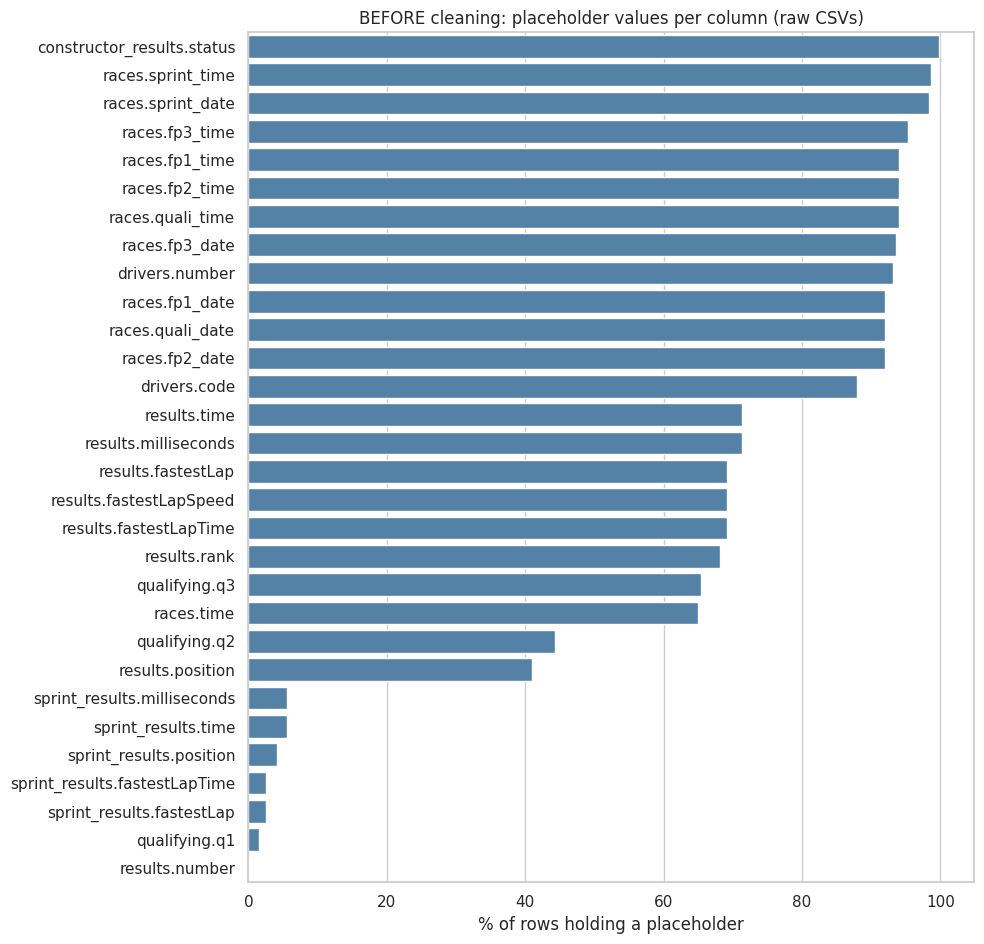

In [4]:
SENTINELS = {r"\N", "", "NA", "N/A", "nan", "NaN", "null", "NULL", "None", "-"}

rows = []
for t in TABLES:
    df = raw[t]
    n = len(df)
    for c in df.columns:
        col = df[c].str.strip()
        n_backslash_N = (col == r"\N").sum()
        n_other = col.isin(SENTINELS - {r"\N"}).sum()
        rows.append({"table": t, "column": c, "n_rows": n,
                     "n_backslashN": n_backslash_N, "n_other_placeholder": n_other,
                     "pct_missing": 100 * (n_backslash_N + n_other) / n})

sent = pd.DataFrame(rows)
sent_nonzero = sent[sent.pct_missing > 0].sort_values("pct_missing", ascending=False)

print("Columns with at least one placeholder:", len(sent_nonzero), "of", len(sent))
print("Other (non-\\N) placeholders found:", int(sent.n_other_placeholder.sum()))
display(sent_nonzero.reset_index(drop=True))

# Sanity check on coverage
yrs = raw["races"]["year"].astype(int)
print(f"\nraces: {yrs.min()}-{yrs.max()}, {len(yrs)} races")

# Plot: % missing per (table.column), only columns affected
plot_df = sent_nonzero.copy()
plot_df["label"] = plot_df["table"] + "." + plot_df["column"]
plt.figure(figsize=(10, max(4, 0.32 * len(plot_df))))
sns.barplot(data=plot_df, y="label", x="pct_missing", color="steelblue")
plt.xlabel("% of rows holding a placeholder")
plt.ylabel("")
plt.title("BEFORE cleaning: placeholder values per column (raw CSVs)")
plt.tight_layout()
plt.show()

In [5]:
# 1) What exactly are the 68 non-\N placeholders?
other_rows = []
for t in TABLES:
    for c in raw[t].columns:
        col = raw[t][c].str.strip()
        vc = col[col.isin(SENTINELS - {r"\N"})].value_counts()
        for v, n in vc.items():
            other_rows.append({"table": t, "column": c, "value": repr(v), "count": n})
print("Non-\\N placeholder values found:")
display(pd.DataFrame(other_rows))

# 2) Hidden sentinel candidate: grid == 0 in results
res = raw["results"].copy()
res["year"] = res["raceId"].map(raw["races"].set_index("raceId")["year"]).astype(int)
res["grid_i"] = res["grid"].astype(int)
print("\nresults.grid == 0 overall:", (res.grid_i == 0).sum(), "of", len(res))
g0 = (res.assign(grid0=res.grid_i == 0)
         .groupby((res.year // 10) * 10)["grid0"].agg(["sum", "mean"]))
g0.columns = ["n_grid0", "share"]
display(g0)

# 3) The 6 rows in results with a missing car number
print("\nresults rows with missing number:")
display(res[res["number"] == r"\N"][["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "year"]])

# 4) Sprint check: races with a sprint vs rows in sprint_results
n_sprint_races = (raw["races"]["sprint_date"] != r"\N").sum()
print("\nraces with a sprint date:", n_sprint_races,
      "| distinct raceIds in sprint_results:", raw["sprint_results"]["raceId"].nunique())

Non-\N placeholder values found:


,table,column,value,count
0,qualifying,q2,'',22
1,qualifying,q3,'',46



results.grid == 0 overall: 1638 of 26759


,n_grid0,share
year,,
1950,68,0.033881
1960,198,0.093706
1970,351,0.092199
1980,571,0.126804
1990,357,0.084000
2000,8,0.002196
2010,28,0.006516
2020,57,0.026648



results rows with missing number:


,resultId,raceId,driverId,constructorId,grid,positionOrder,year
17715,17716,732,459,66,0,19,1962
17716,17717,732,462,95,0,20,1962
17717,17718,732,446,172,0,21,1962
17718,17719,732,437,170,0,22,1962
17939,17940,741,485,172,0,28,1961
20319,20322,728,305,26,0,23,1963



races with a sprint date: 18 | distinct raceIds in sprint_results: 18


## 3. Primary-key and foreign-key audit

**Primary keys:** all 14 tables pass (unique and non-null). `lap_times` and `pit_stops` have no ID column, so composite keys are used: (raceId, driverId, lap) and (raceId, driverId, stop).

**Foreign keys:** all 23 relationships reconcile. There are no orphans and no null FKs. `races` and `results` both cover all 1,125 races, so no race lacks results.

**Informational:** constructor 88 (Eagle) exists in `constructors.csv` but has no result rows. It does not affect the modelling table.

Because the keys are clean, the only grain problem is duplicate (raceId, driverId) pairs inside `results`, handled next.

In [6]:
PK = {
    "circuits": ["circuitId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "constructors": ["constructorId"],
    "driver_standings": ["driverStandingsId"],
    "drivers": ["driverId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "seasons": ["year"],
    "sprint_results": ["resultId"],
    "status": ["statusId"],
}

pk_rows = []
for t, cols in PK.items():
    df = raw[t]
    n_null = int(df[cols].apply(lambda s: s.str.strip().isin([r"\N", ""])).any(axis=1).sum())
    n_dup = int(df.duplicated(subset=cols, keep=False).sum())
    pk_rows.append({"table": t, "primary_key": "+".join(cols), "rows": len(df),
                    "null_pk_rows": n_null, "duplicate_pk_rows": n_dup,
                    "PASS": (n_null == 0) and (n_dup == 0)})

pk_audit = pd.DataFrame(pk_rows)
display(pk_audit)

,table,primary_key,rows,null_pk_rows,duplicate_pk_rows,PASS
0,circuits,circuitId,77,0,0,True
1,constructor_results,constructorResultsId,12625,0,0,True
2,constructor_standings,constructorStandingsId,13391,0,0,True
3,constructors,constructorId,212,0,0,True
4,driver_standings,driverStandingsId,34863,0,0,True
5,drivers,driverId,861,0,0,True
6,lap_times,raceId+driverId+lap,589081,0,0,True
7,pit_stops,raceId+driverId+stop,11371,0,0,True
8,qualifying,qualifyId,10494,0,0,True
9,races,raceId,1125,0,0,True


In [7]:
# (child_table, child_col, parent_table, parent_col)
FK = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
]

fk_rows = []
orphan_examples = {}
for child, ccol, parent, pcol in FK:
    c = raw[child][ccol].str.strip()
    parent_vals = set(raw[parent][pcol].str.strip())
    is_null = c.isin([r"\N", ""])
    orphan_mask = ~is_null & ~c.isin(parent_vals)
    fk_rows.append({
        "child": child, "fk_col": ccol, "parent": f"{parent}.{pcol}",
        "rows": len(c), "null_fk": int(is_null.sum()),
        "orphan_rows": int(orphan_mask.sum()),
        "distinct_orphan_values": c[orphan_mask].nunique(),
        "PASS": int(orphan_mask.sum()) == 0,
    })
    if orphan_mask.any():
        orphan_examples[(child, ccol)] = raw[child][orphan_mask].head(5)

fk_audit = pd.DataFrame(fk_rows)
display(fk_audit)
print("All foreign keys reconcile:", fk_audit["PASS"].all())

for k, v in orphan_examples.items():
    print("\nOrphan examples:", k)
    display(v)

# Reverse check (informational): parents with no children in results
used_drivers = raw["results"]["driverId"].nunique()
used_constr = raw["results"]["constructorId"].nunique()
print(f"\nDrivers in drivers.csv: {len(raw['drivers'])} | appearing in results: {used_drivers}")
print(f"Constructors in constructors.csv: {len(raw['constructors'])} | appearing in results: {used_constr}")
print(f"Races in races.csv: {len(raw['races'])} | with results: {raw['results']['raceId'].nunique()}")

,child,fk_col,parent,rows,null_fk,orphan_rows,distinct_orphan_values,PASS
0,races,circuitId,circuits.circuitId,1125,0,0,0,True
1,races,year,seasons.year,1125,0,0,0,True
2,results,raceId,races.raceId,26759,0,0,0,True
3,results,driverId,drivers.driverId,26759,0,0,0,True
4,results,constructorId,constructors.constructorId,26759,0,0,0,True
5,results,statusId,status.statusId,26759,0,0,0,True
6,sprint_results,raceId,races.raceId,360,0,0,0,True
7,sprint_results,driverId,drivers.driverId,360,0,0,0,True
8,sprint_results,constructorId,constructors.constructorId,360,0,0,0,True
9,sprint_results,statusId,status.statusId,360,0,0,0,True


All foreign keys reconcile: True

Drivers in drivers.csv: 861 | appearing in results: 861
Constructors in constructors.csv: 212 | appearing in results: 211
Races in races.csv: 1125 | with results: 1125


## 4. Fixing the grain: one row per (raceId, driverId)

### Diagnosis
85 (raceId, driverId) pairs are duplicated (79 with 2 rows, 6 with 3), which is 91 surplus rows. They occur mostly in 1950-1958, with a few in 1960-64 and 1978. 69 of the 85 pairs have the same constructor (a driver taking over a teammate's car), 16 have different constructors. The 1978, 1962 and 1958 cases without a grid slot are non-starters (DNQ/DNPQ/withdrawn), not shared drives.

### Why the obvious rules fail
The "keep the row with grid > 0" rule from the glossary resolves **zero** pairs: 76 pairs have two rows with a grid slot, 6 have three, and 3 have none.

### Candidate rules compared (Cell 8)
| Rule | Podium rows kept among the 85 pairs |
|---|---|
| A: best positionOrder | 22 |
| B: lowest positive grid | 5 |
| C: first resultId | 6 |
| D: most laps | 22 |

The rules disagree on the podium label for 20 of 85 pairs. In every flipped pair the podium row is the car the driver **took over**, and the retirement row carries his own early grid slot.

### Decision: separate the label from the features
- **Target:** the driver's best (lowest) `positionOrder` across his rows. This is how the sport credits a shared drive.
- **Pre-race attributes** (`grid`, `constructorId`, `number`): from the row with the **lowest positive grid** (ties broken by `resultId`). This choice does not depend on the race outcome.

**Why not just keep the best-positionOrder row (rule A)?** It would select rows by race outcome and then inherit that row's `grid`. The finishing row usually has a worse grid slot, so `grid` would be systematically tied to the label, which is selection bias.

### Impact
26,759 -> 26,668 rows; `(raceId, driverId)` is unique (asserted). Podium rows 3,397 -> 3,395. In 17 pairs the label and the features come from different rows. 18 races (all 1950-1956) now have more than 3 podium rows, because shared drives credit the podium to two drivers. This is documented, not an error.

Constructor(s) with no results rows:


,constructorId,constructorRef,name,nationality,url
86,88,eagle,Eagle,American,http://en.wikipedia.org/wiki/Anglo_American_Ra...



Rows involved in duplicates : 176
Distinct duplicated pairs   : 85
Surplus rows to remove      : 91

Group size distribution:
               n_pairs
rows_per_pair         
2                   79
3                    6

Years with duplicates: 1950 - 1978


year,1950,1951,1952,1953,1954,1955,1956,1957,1958,1960,1961,1962,1964,1978
dup_rows,8,8,6,30,33,33,24,16,6,2,4,2,2,2



Pairs where rows have different constructorId: 16 | same constructorId: 69

Number of rows with grid > 0 within each duplicated pair:
                  n_pairs
rows_with_grid>0         
2                      76
3                       6
0                       3


,resultId,raceId,driverId,constructorId,grid,position,positionText,positionOrder,points,laps,status,year
13188,13189,540,229,54,0,\N,F,26,0.0,0,Did not qualify,1978
13191,13192,540,229,57,0,\N,F,29,0.0,0,Did not prequalify,1978
17362,17363,717,373,172,1,7,7,7,0.0,102,Out of fuel,1964
24298,24304,717,373,172,1,\N,R,12,0.0,54,Injection,1964
17740,17741,733,465,172,0,\N,W,22,0.0,0,Withdrew,1962
17743,17744,733,465,97,0,\N,W,25,0.0,0,Withdrew,1962
17961,17962,742,475,102,20,\N,D,19,0.0,56,Disqualified,1961
17963,17964,742,475,172,5,\N,R,21,0.0,44,Brakes,1961
18062,18063,745,418,172,11,\N,R,17,0.0,23,Gearbox,1961
24297,24303,745,418,172,15,11,11,11,0.0,92,+8 Laps,1961


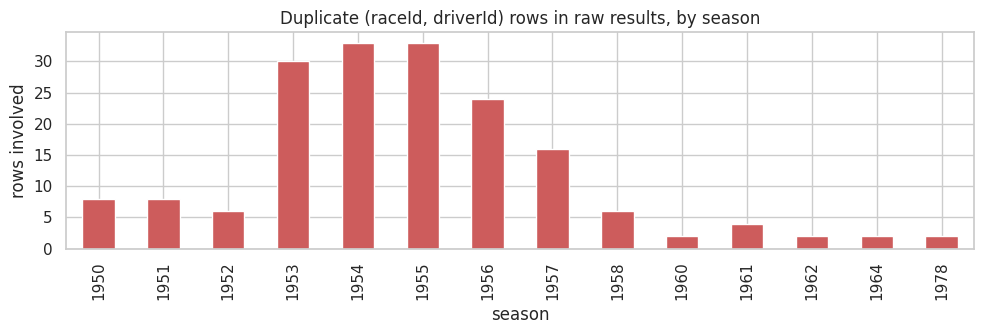

In [8]:
# --- the constructor that never appears in results ---
missing_c = set(raw["constructors"]["constructorId"]) - set(raw["results"]["constructorId"])
print("Constructor(s) with no results rows:")
display(raw["constructors"][raw["constructors"]["constructorId"].isin(missing_c)])

# --- typed working copy of results (raw stays untouched) ---
res = raw["results"].copy()
res["year"] = res["raceId"].map(raw["races"].set_index("raceId")["year"]).astype(int)
for c in ["grid", "positionOrder", "laps"]:
    res[c] = res[c].astype(int)
res["points"] = res["points"].astype(float)
res["status"] = res["statusId"].map(raw["status"].set_index("statusId")["status"])

# --- how many duplicates? ---
key = ["raceId", "driverId"]
dup_mask = res.duplicated(key, keep=False)
dups = res[dup_mask].copy()
grp = dups.groupby(key)

print(f"\nRows involved in duplicates : {len(dups)}")
print(f"Distinct duplicated pairs   : {grp.ngroups}")
print(f"Surplus rows to remove      : {len(dups) - grp.ngroups}")
print("\nGroup size distribution:")
print(grp.size().value_counts().rename_axis("rows_per_pair").to_frame("n_pairs"))

# --- when do they happen? ---
by_year = dups.groupby("year").size()
print("\nYears with duplicates:", by_year.index.min(), "-", by_year.index.max())
display(by_year.to_frame("dup_rows").T)

# --- do the duplicate rows use different cars (constructors)? ---
n_constr = grp["constructorId"].nunique()
print("\nPairs where rows have different constructorId:", int((n_constr > 1).sum()),
      "| same constructorId:", int((n_constr == 1).sum()))

# --- would 'keep the row with grid > 0' resolve each pair? ---
n_grid_pos = grp["grid"].apply(lambda s: (s > 0).sum())
print("\nNumber of rows with grid > 0 within each duplicated pair:")
print(n_grid_pos.value_counts().rename_axis("rows_with_grid>0").to_frame("n_pairs"))

# --- look at examples ---
show = ["resultId", "raceId", "driverId", "constructorId", "grid", "position",
        "positionText", "positionOrder", "points", "laps", "status", "year"]
examples = dups.sort_values(key + ["resultId"]).head(12)
display(examples[show])

# --- plot ---
plt.figure(figsize=(10, 3.5))
by_year.plot(kind="bar", color="indianred")
plt.title("Duplicate (raceId, driverId) rows in raw results, by season")
plt.xlabel("season"); plt.ylabel("rows involved")
plt.tight_layout(); plt.show()

In [9]:
res["podium"] = (res["positionOrder"] <= 3).astype(int)
d = res[res.duplicated(key, keep=False)].copy()

def pick(df, sort_cols, asc):
    out = (df.sort_values(key + sort_cols, ascending=[True, True] + asc)
             .drop_duplicates(key, keep="first"))
    return out.set_index(key)

rules = {
    "A_best_positionOrder": pick(d, ["positionOrder", "resultId"], [True, True]),
    "B_lowest_gridpos":     pick(d.assign(g=d.grid.where(d.grid > 0)), ["g", "positionOrder"], [True, True]),
    "C_first_resultId":     pick(d, ["resultId"], [True]),
    "D_most_laps":          pick(d, ["laps", "positionOrder"], [False, True]),
}

cmp_podium = pd.DataFrame({k: v["podium"] for k, v in rules.items()})
cmp_grid   = pd.DataFrame({k: v["grid"]   for k, v in rules.items()})

print("Podium rows kept among the 85 pairs, per rule:")
print(cmp_podium.sum().to_string())

podium_disagree = cmp_podium.nunique(axis=1) > 1
grid_disagree   = cmp_grid.nunique(axis=1) > 1
print(f"\nPairs where rules disagree on the podium label: {podium_disagree.sum()} of {len(cmp_podium)}")
print(f"Pairs where rules disagree on grid value:       {grid_disagree.sum()} of {len(cmp_grid)}")

# Pairs where at least one row is a podium and at least one is not
mixed = d.groupby(key)["podium"].agg(lambda s: s.nunique() > 1)
print(f"Pairs with a podium row AND a non-podium row:   {mixed.sum()}")

# Detail of the pairs where the label depends on the rule
show = ["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "points", "laps", "status", "year"]
idx = cmp_podium[podium_disagree].index
detail = d.set_index(key).loc[idx].reset_index().sort_values(key + ["resultId"])
display(detail[show])

# The 3 pairs where no row has a grid slot
zero_pairs = d.groupby(key)["grid"].apply(lambda s: (s > 0).sum() == 0)
print("\nPairs with no grid slot at all:")
display(d.set_index(key).loc[zero_pairs[zero_pairs].index].reset_index()[show])

Podium rows kept among the 85 pairs, per rule:
A_best_positionOrder    22
B_lowest_gridpos         5
C_first_resultId         6
D_most_laps             22

Pairs where rules disagree on the podium label: 20 of 85
Pairs where rules disagree on grid value:       73 of 85
Pairs with a podium row AND a non-podium row:   21


,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,status,year
0,18083,746,475,170,1,17,0.00,40,Suspension,1960
1,22372,746,475,170,8,3,0.00,80,Finished,1960
2,18817,780,475,118,1,12,0.00,51,Engine,1957
3,20291,780,475,118,3,1,5.00,90,Finished,1957
4,18806,780,479,118,3,1,4.00,90,Finished,1957
5,20293,780,479,118,1,12,0.00,51,Engine,1957
6,18895,784,579,6,1,13,0.00,22,Fuel pump,1956
7,20267,784,579,6,3,1,5.00,98,Finished,1956
8,18899,785,579,6,1,4,1.50,99,+1 Lap,1956
9,20270,785,579,6,9,2,4.00,100,Finished,1956



Pairs with no grid slot at all:


,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,status,year
0,13189,540,229,54,0,26,0.0,0,Did not qualify,1978
1,13192,540,229,57,0,29,0.0,0,Did not prequalify,1978
2,17741,733,465,172,0,22,0.0,0,Withdrew,1962
3,17744,733,465,97,0,25,0.0,0,Withdrew,1962
4,18510,766,541,87,0,17,0.0,0,Did not qualify,1958
5,18520,766,541,66,0,27,0.0,0,Did not qualify,1958


In [10]:
# --- 1) label: best official classification across the driver's rows ---
best = (res.groupby(key)["positionOrder"].min()
           .rename("positionOrder_best").reset_index())

# --- 2) pre-race attributes: row with lowest POSITIVE grid (outcome-independent) ---
res["grid_pos"] = res["grid"].where(res["grid"] > 0)   # grid 0 -> NaN just for sorting
start_row = (res.sort_values(key + ["grid_pos", "resultId"])   # NaN sorts last
                .drop_duplicates(key, keep="first"))

n_raw = res.groupby(key).size().rename("n_rows_raw").reset_index()

base = (start_row.merge(best, on=key, validate="1:1")
                 .merge(n_raw, on=key, validate="1:1"))
base["was_duplicated"] = base["n_rows_raw"] > 1
base["podium"] = (base["positionOrder_best"] <= 3).astype(int)

# --- verification ---
assert not base.duplicated(key).any(), "grain violated"
assert len(base) == len(res) - 91, "unexpected number of rows"
print("Rows before:", len(res), "| after:", len(base), "| removed:", len(res) - len(base))
print("(raceId, driverId) unique:", base.set_index(key).index.is_unique)

# --- impact on the target ---
raw_podium_rows = int((res["positionOrder"] <= 3).sum())
print(f"\nPodium rows in raw results      : {raw_podium_rows}")
print(f"Podium rows after dedup (rule)  : {int(base['podium'].sum())}")
print(f"Podium rate before/after        : {raw_podium_rows/len(res):.4f} / {base['podium'].mean():.4f}")

# did the start row's own label differ from the best label? (the 'relabelled' pairs)
chg = base[base["was_duplicated"] & ((base["positionOrder"] <= 3).astype(int) != base["podium"])]
print("Pairs where target comes from a different row than the features:", len(chg))

# --- shared-drive side effect: races with more than 3 podium rows ---
pod_per_race = base.groupby("raceId")["podium"].sum()
over = pod_per_race[pod_per_race > 3]
print("\nRaces with >3 podium rows:", len(over))
display(over.rename("podium_rows").reset_index()
        .merge(raw["races"][["raceId", "year", "name"]], on="raceId").sort_values("year").head(15))

# --- unresolved: non-starters (grid_pos is NaN) ---
print("\nRows with no positive grid after dedup:", int(base["grid_pos"].isna().sum()))

# --- duplicate-handling log (keep for the report) ---
dup_log = (res[res.set_index(key).index.isin(base[base.was_duplicated].set_index(key).index)]
             .merge(base[key + ["resultId"]].assign(kept_for_features=True), on=key + ["resultId"], how="left"))
dup_log["kept_for_features"] = dup_log["kept_for_features"].fillna(False)
print("\nDuplicate log rows:", len(dup_log), "| pairs:", dup_log.groupby(key).ngroups)

Rows before: 26759 | after: 26668 | removed: 91
(raceId, driverId) unique: True

Podium rows in raw results      : 3397
Podium rows after dedup (rule)  : 3395
Podium rate before/after        : 0.1269 / 0.1273
Pairs where target comes from a different row than the features: 17

Races with >3 podium rows: 18


,raceId,podium_rows,year,name
17,839,4,1950,Italian Grand Prix
15,828,5,1951,French Grand Prix
14,826,4,1951,Indianapolis 500
16,831,4,1951,Italian Grand Prix
13,810,4,1953,Dutch Grand Prix
12,809,4,1953,Indianapolis 500
11,806,4,1954,Italian Grand Prix
10,804,4,1954,German Grand Prix
9,794,4,1955,Indianapolis 500
8,793,4,1955,Monaco Grand Prix



Rows with no positive grid after dedup: 1635

Duplicate log rows: 176 | pairs: 85


## 5. Which rows belong in the modelling table?

### Non-starters
After deduplication, 1,635 rows have no positive grid slot. They are two different populations:
- **Never raced** (1,563 rows, `laps == 0`): mostly Did not qualify (1,012), Did not prequalify (330) and Withdrew (163), peaking in 1989-92 (the prequalifying era). **Excluded**: they never competed, and none of them is a podium.
- **Raced without a grid slot** (72 rows, `laps > 0`, all 2010 onward): genuine pit-lane starts. **Kept**, with `grid_clean = NaN` and `grid_is_zero = 1`.

*Caveat:* DNQ/DNPQ/Withdrew/107%-rule rows are known before the race, but `laps == 0` is a race outcome. For the 13 non-starter rows since 2010 with failure statuses (Engine, Brakes, Fuel system, ...) the test is not strictly pre-race. None is a podium, and they are 0.05% of the table. Stated as a limitation.

### Indianapolis 500 (1950-1960)
381 rows in 11 races (17.8% of 1950-60 rows), 36 podium rows. It counted for the championship, but almost no F1 regulars entered it and its grid structure is different. **Excluded**, with the `is_indy500` flag kept in the audit file so the choice is reversible.

### Effect (waterfall)
26,668 -> 26,287 (Indy) -> **24,724** (non-starters). Podium rate 12.73% -> 12.78% -> 13.59%. The 1980s field size falls from 28.9 to 25.2 and the 1980s podium rate rises from 10.4% to 11.9%. From 2000 onward the filters change almost nothing.

Non-positive-grid rows by status (top 15):


,n
status,
Did not qualify,1012
Did not prequalify,330
Withdrew,163
+1 Lap,27
Finished,22
Accident,20
Injury,8
+2 Laps,7
Engine,6



Laps completed among these rows:
laps == 0: 1563 | laps > 0: 72


raced,never_raced(laps=0),raced(laps>0)
decade,,
1950,67,0
1960,197,0
1970,350,0
1980,571,0
1990,357,0
2000,8,0
2010,9,19
2020,4,53



Podium rows among no-grid rows: 0


,raceId,driverId,constructorId,grid,positionOrder_best,laps,status,year



No-grid rows since 2000: 93


,year,status,n
0,2000,Safety concerns,2
1,2001,107% Rule,1
3,2002,Did not qualify,2
2,2002,107% Rule,1
4,2002,Injury,1
5,2009,Withdrew,1
6,2011,Did not qualify,2
7,2011,Injury,1
8,2012,Did not qualify,2
9,2012,Withdrew,1



Indy 500 races: 11 | rows: 381 | years: 1950 - 1960
Share of rows that are Indy 500 in 1950-1960: 0.1777


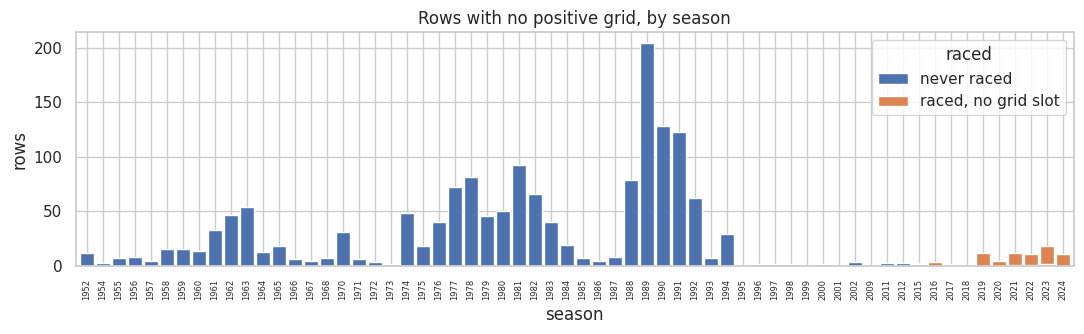

In [11]:
# --- 1) who are the 1,635 rows with no positive grid? ---
ns = base[base["grid_pos"].isna()].copy()
ns["decade"] = (ns["year"] // 10) * 10

print("Non-positive-grid rows by status (top 15):")
display(ns["status"].value_counts().head(15).rename("n").to_frame())

print("\nLaps completed among these rows:")
print("laps == 0:", int((ns.laps == 0).sum()), "| laps > 0:", int((ns.laps > 0).sum()))

# --- 2) by decade: zero-lap (never raced) vs laps>0 (raced, but no grid slot) ---
by_dec = (ns.assign(raced=ns.laps > 0)
            .groupby(["decade", "raced"]).size().unstack(fill_value=0)
            .rename(columns={False: "never_raced(laps=0)", True: "raced(laps>0)"}))
display(by_dec)

# --- 3) do any of these rows reach the podium? ---
print("\nPodium rows among no-grid rows:", int(ns["podium"].sum()))
display(ns[ns.podium == 1][["raceId", "driverId", "constructorId", "grid", "positionOrder_best",
                            "laps", "status", "year"]].sort_values("year").tail(15))

# --- 4) modern era (2000+): what is grid == 0 there? ---
modern = ns[ns.year >= 2000]
print("\nNo-grid rows since 2000:", len(modern))
display(modern.groupby(["year", "status"]).size().rename("n").reset_index()
        .sort_values(["year", "n"], ascending=[True, False]).head(25))

# --- 5) Indianapolis 500 in the base table ---
indy_ids = raw["races"].loc[raw["races"]["name"].str.contains("Indianapolis"), "raceId"]
indy = base[base["raceId"].isin(indy_ids)]
print("\nIndy 500 races:", indy["raceId"].nunique(), "| rows:", len(indy),
      "| years:", indy["year"].min(), "-", indy["year"].max())
print("Share of rows that are Indy 500 in 1950-1960:",
      round(len(indy) / (base["year"].between(1950, 1960)).sum(), 4))

# plot: non-starter rows per season, split by laps
plt.figure(figsize=(11, 3.5))
(ns.assign(raced=np.where(ns.laps > 0, "raced, no grid slot", "never raced"))
   .groupby(["year", "raced"]).size().unstack(fill_value=0)
   .plot(kind="bar", stacked=True, ax=plt.gca(), width=0.9))
plt.title("Rows with no positive grid, by season"); plt.xlabel("season"); plt.ylabel("rows")
plt.xticks(rotation=90, fontsize=6); plt.tight_layout(); plt.show()

Non-starters since 2010: 13


,year,status,n
0,2011,Did not qualify,2
1,2011,Injury,1
2,2012,Did not qualify,2
3,2012,Withdrew,1
4,2015,Fuel system,1
5,2015,Withdrew,1
6,2017,Battery,1
7,2021,Brakes,1
8,2022,Withdrew,1
9,2023,Engine,1



Races with >3 podium rows: 18 | of which Indy 500: 3


,step,rows,podium_rows,removed,podium_rate
0,after dedup (grain fixed),26668,3395,0,0.1273
1,- Indy 500 (1950-60),26287,3359,381,0.1278
2,"- non-starters (no grid, 0 laps)",24724,3359,1563,0.1359


Pit-lane starts kept: 72 | rows with grid_clean NaN: 72


,rows_before,races_before,podium_rate_before,field_size_before,rows_after,races_after,podium_rate_after,field_size_after
decade,,,,,,,,
1950,1922,84,0.141,22.881,1507,74,0.158,20.365
1960,2108,100,0.143,21.080,1878,99,0.159,18.970
1970,3806,144,0.114,26.431,3456,144,0.125,24.000
1980,4503,156,0.104,28.865,3932,156,0.119,25.205
1990,4250,162,0.114,26.235,3893,162,0.125,24.031
2000,3643,174,0.143,20.937,3635,174,0.144,20.891
2010,4297,198,0.138,21.702,4288,198,0.139,21.657
2020,2139,107,0.150,19.991,2135,107,0.150,19.953


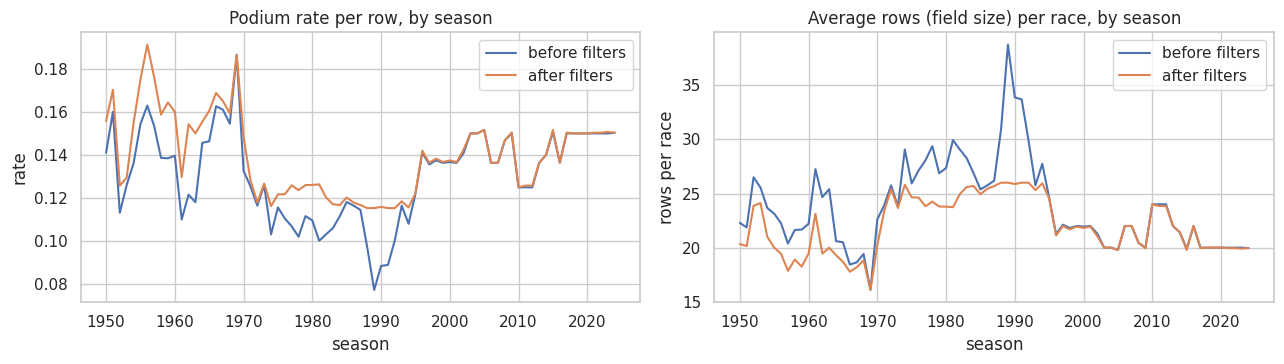

In [12]:
# --- flags (nothing is dropped from `base`) ---
base["is_indy500"]       = base["raceId"].isin(indy_ids)
base["no_grid"]          = base["grid_pos"].isna()
base["is_nonstarter"]    = base["no_grid"] & (base["laps"] == 0)
base["is_pitlane_start"] = base["no_grid"] & (base["laps"] > 0)
base["grid_is_zero"]     = (base["grid"] == 0).astype(int)
base["grid_clean"]       = base["grid_pos"]            # NaN where grid == 0

# sanity: statuses of the laps==0 no-grid rows since 2010 (are they real non-starts?)
chk = base[base.is_nonstarter & (base.year >= 2010)]
print("Non-starters since 2010:", len(chk))
display(chk.groupby(["year", "status"]).size().rename("n").reset_index())

# sanity: Indy 500 exact count among >3-podium races
pod_race = base.groupby("raceId")["podium"].sum()
over_ids = pod_race[pod_race > 3].index
print("\nRaces with >3 podium rows:", len(over_ids),
      "| of which Indy 500:", int(pd.Series(over_ids).isin(indy_ids).sum()))

# --- row waterfall ---
n0 = len(base)
step1 = base[~base.is_indy500]
step2 = step1[~step1.is_nonstarter]
model_base = step2.copy()
wf = pd.DataFrame({
    "step": ["after dedup (grain fixed)", "- Indy 500 (1950-60)", "- non-starters (no grid, 0 laps)"],
    "rows": [n0, len(step1), len(step2)],
    "podium_rows": [int(base.podium.sum()), int(step1.podium.sum()), int(step2.podium.sum())],
})
wf["removed"] = (-wf["rows"].diff()).fillna(0).astype(int)
wf["podium_rate"] = (wf["podium_rows"] / wf["rows"]).round(4)
display(wf)

assert not model_base.duplicated(["raceId", "driverId"]).any()
print("Pit-lane starts kept:", int(model_base.is_pitlane_start.sum()),
      "| rows with grid_clean NaN:", int(model_base.grid_clean.isna().sum()))

# --- before/after: field size and podium rate by decade ---
def summ(df, tag):
    g = df.assign(decade=(df.year // 10) * 10)
    out = g.groupby("decade").agg(rows=("podium", "size"), races=("raceId", "nunique"),
                                  podium_rate=("podium", "mean"))
    out["field_size"] = out["rows"] / out["races"]
    return out.add_suffix("_" + tag)

cmp = summ(base, "before").join(summ(model_base, "after"))
display(cmp.round(3))

# --- plot: podium rate and field size per season, before vs after ---
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for df, lab in [(base, "before filters"), (model_base, "after filters")]:
    df.groupby("year")["podium"].mean().plot(ax=ax[0], label=lab)
    (df.groupby("year").size() / df.groupby("year")["raceId"].nunique()).plot(ax=ax[1], label=lab)
ax[0].set_title("Podium rate per row, by season"); ax[0].set_ylabel("rate")
ax[1].set_title("Average rows (field size) per race, by season"); ax[1].set_ylabel("rows per race")
for a in ax: a.legend(); a.set_xlabel("season")
plt.tight_layout(); plt.show()

## 6. Sentinel cleaning and semantic typing (all 14 tables)

`\N` and empty strings become NaN on **copies**. Types applied: nullable integers (`Int64`), floats, dates (`datetime64`), clock times (`timedelta`), and lap-time strings (`m:ss.sss`) converted to numeric seconds in new `*_sec` columns.

**Validation**
- 0 failed conversions across 94 typed columns.
- Parsed `time_sec` and `duration_sec` match the `milliseconds` columns with a maximum difference of 0.000 ms on all 589,081 lap times and 11,371 pit stops. This independently validates the time parser.
- `races.date` runs 1950-05-13 to 2024-12-08 and matches `year` in every row.
- Non-null counts agree with the sentinel audit (for example q1: 10,494 - 156 = 10,338).

`results.time` stays as text: it mixes the winner's elapsed time with gaps such as "+5.478", and it is post-race anyway.

In [13]:
SENT = {r"\N", ""}

SPEC = {
    "circuits":              dict(int=["circuitId"], float=["lat", "lng", "alt"]),
    "constructor_results":   dict(int=["constructorResultsId", "raceId", "constructorId"], float=["points"]),
    "constructor_standings": dict(int=["constructorStandingsId", "raceId", "constructorId", "position", "wins"], float=["points"]),
    "constructors":          dict(int=["constructorId"]),
    "driver_standings":      dict(int=["driverStandingsId", "raceId", "driverId", "position", "wins"], float=["points"]),
    "drivers":               dict(int=["driverId", "number"], date=["dob"]),
    "lap_times":             dict(int=["raceId", "driverId", "lap", "position", "milliseconds"], sec=["time"]),
    "pit_stops":             dict(int=["raceId", "driverId", "stop", "lap", "milliseconds"], sec=["duration"], clock=["time"]),
    "qualifying":            dict(int=["qualifyId", "raceId", "driverId", "constructorId", "number", "position"], sec=["q1", "q2", "q3"]),
    "races":                 dict(int=["raceId", "year", "round", "circuitId"],
                                  date=["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
                                  clock=["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]),
    "results":               dict(int=["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                                       "positionOrder", "laps", "milliseconds", "fastestLap", "rank", "statusId"],
                                  float=["points", "fastestLapSpeed"], sec=["fastestLapTime"]),
    "seasons":               dict(int=["year"]),
    "sprint_results":        dict(int=["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                                       "positionOrder", "laps", "milliseconds", "fastestLap", "statusId"],
                                  float=["points"], sec=["fastestLapTime"]),
    "status":                dict(int=["statusId"]),
}

def to_seconds(x):
    """'1:26.572' -> 86.572 ; '58.3' -> 58.3 ; '1:02:03.5' -> 3723.5 ; NaN -> NaN"""
    if pd.isna(x):
        return np.nan
    try:
        total = 0.0
        for part in str(x).split(":"):
            total = total * 60 + float(part)
        return total
    except ValueError:
        return np.nan

clean, log = {}, []
for t in TABLES:
    df = raw[t].copy()
    df = df.apply(lambda s: s.str.strip())
    df = df.replace({s: np.nan for s in SENT})            # sentinels -> NaN
    spec = SPEC[t]

    def record(col, kind, before, after):
        raw_present = before.notna()
        log.append({"table": t, "column": col, "type": kind,
                    "sentinels_to_NaN": int(raw[t][col].str.strip().isin(SENT).sum()),
                    "failed_conversion": int((raw_present & after.isna()).sum())})

    for c in [c for c in spec.get("int", []) if c in df.columns]:
        new = pd.to_numeric(df[c], errors="coerce").astype("Int64")
        record(c, "Int64", df[c], new); df[c] = new
    for c in [c for c in spec.get("float", []) if c in df.columns]:
        new = pd.to_numeric(df[c], errors="coerce").astype("float64")
        record(c, "float", df[c], new); df[c] = new
    for c in [c for c in spec.get("date", []) if c in df.columns]:
        new = pd.to_datetime(df[c], format="%Y-%m-%d", errors="coerce")
        record(c, "datetime", df[c], new); df[c] = new
    for c in [c for c in spec.get("sec", []) if c in df.columns]:
        new = df[c].map(to_seconds)
        record(c, "seconds", df[c], new); df[c + "_sec"] = new
    for c in [c for c in spec.get("clock", []) if c in df.columns]:
        new = pd.to_timedelta(df[c], errors="coerce")
        record(c, "timedelta", df[c], new); df[c] = new
    clean[t] = df

conv_log = pd.DataFrame(log)
print("Columns typed:", len(conv_log), "| total failed conversions:", int(conv_log.failed_conversion.sum()))
display(conv_log[conv_log.failed_conversion > 0])

# ---- cross-checks ----
# 1) parsed lap time (s) vs the milliseconds column
lt = clean["lap_times"]
diff = (lt["time_sec"] * 1000 - lt["milliseconds"].astype(float)).abs()
print(f"\nlap_times: max |time_sec*1000 - milliseconds| = {diff.max():.3f} ms | rows off by >1 ms: {(diff > 1).sum()}")

pt = clean["pit_stops"]
d2 = (pt["duration_sec"] * 1000 - pt["milliseconds"].astype(float)).abs()
print(f"pit_stops: max |duration_sec*1000 - milliseconds| = {d2.max():.3f} ms | rows off by >1 ms: {(d2 > 1).sum()}")

# 2) date sanity
rc, dr = clean["races"], clean["drivers"]
print("\nraces.date range:", rc["date"].min().date(), "->", rc["date"].max().date(),
      "| year matches date.year:", bool((rc["date"].dt.year == rc["year"]).all()))
print("drivers.dob range:", dr["dob"].min().date(), "->", dr["dob"].max().date(), "| missing dob:", int(dr["dob"].isna().sum()))

# 3) value ranges of parsed times (seconds)
rng = pd.DataFrame({
    "qualifying.q1": clean["qualifying"]["q1_sec"].describe(),
    "qualifying.q3": clean["qualifying"]["q3_sec"].describe(),
    "results.fastestLapTime": clean["results"]["fastestLapTime_sec"].describe(),
    "lap_times.time": lt["time_sec"].describe(),
    "pit_stops.duration": pt["duration_sec"].describe(),
}).T[["count", "min", "50%", "max"]]
display(rng.round(2))

# 4) dtype overview of the key tables
for t in ["results", "qualifying", "races"]:
    print(f"\n{t} dtypes:"); print(clean[t].dtypes.astype(str).to_string())

Columns typed: 94 | total failed conversions: 0


,table,column,type,sentinels_to_NaN,failed_conversion



lap_times: max |time_sec*1000 - milliseconds| = 0.000 ms | rows off by >1 ms: 0
pit_stops: max |duration_sec*1000 - milliseconds| = 0.000 ms | rows off by >1 ms: 0

races.date range: 1950-05-13 -> 2024-12-08 | year matches date.year: True
drivers.dob range: 1896-12-28 -> 2005-05-08 | missing dob: 0


,count,min,50%,max
qualifying.q1,10338.0,53.90,87.14,1002.64
qualifying.q3,3629.0,53.38,87.04,129.78
results.fastestLapTime,8252.0,55.40,90.27,202.30
lap_times.time,589081.0,55.40,90.61,7507.55
pit_stops.duration,11371.0,12.90,23.61,3069.02



results dtypes:
resultId                Int64
raceId                  Int64
driverId                Int64
constructorId           Int64
number                  Int64
grid                    Int64
position                Int64
positionText           object
positionOrder           Int64
points                float64
laps                    Int64
time                   object
milliseconds            Int64
fastestLap              Int64
rank                    Int64
fastestLapTime         object
fastestLapSpeed       float64
statusId                Int64
fastestLapTime_sec    float64

qualifying dtypes:
qualifyId          Int64
raceId             Int64
driverId           Int64
constructorId      Int64
number             Int64
position           Int64
q1                object
q2                object
q3                object
q1_sec           float64
q2_sec           float64
q3_sec           float64

races dtypes:
raceId                   Int64
year                     Int64
round           

## 7. Outlier audit on parsed times

| Table | Extreme value | Explanation | Action |
|---|---|---|---|
| qualifying q1 | 16:42.640 (Blundell, 1995 Japanese GP), 9.9x the race median | Next worst is 1.43x, a clean gap, so this is a data error. The true value is unknown (1:42.640 is a plausible typo but a guess) | Set to NaN, `q1_suspect = True`, raw string kept |
| q1/q3 and lap minimum (about 53-55 s) | Sakhir Grand Prix 2020 | Short outer-circuit layout, real | Keep |
| lap_times > 300 s (708 rows) | e.g. 2011 Canadian GP lap 25, about 2 hours | Red-flag stoppage, real | Keep, flag `lap_suspect` |
| pit_stops > 120 s (481 rows) | e.g. 2022 British GP lap 1, about 51 min | Cars waiting in the pit lane under a red flag, so real data with the wrong meaning | Keep, flag `pit_duration_suspect` |

`lap_times` and `pit_stops` are post-race tables and never feed the features, so only the q1 error could affect modelling.

qualifying rows with q1 > 200 s: 1
qualifying rows with q1 > 1.3 x race median: 3

Slowest q1 relative to its own race:


,raceId,year,name,surname,q1,q2,q3,q1_ratio
2567,255,1995,Japanese Grand Prix,Blundell,16:42.640,NaN,NaN,9.880806
9614,1099,2023,Saudi Arabian Grand Prix,Sargeant,2:08.510,NaN,NaN,1.432704
4156,93,2004,San Marino Grand Prix,Baumgartner,1:46.299,NaN,NaN,1.311354
2375,247,1995,British Grand Prix,Montermini,1:52.398,NaN,NaN,1.225420
4038,121,2003,Italian Grand Prix,Alonso,1:40.405,NaN,NaN,1.213566
3303,16,2009,Brazilian Grand Prix,Fisichella,1:40.703,NaN,NaN,1.190258
2374,247,1995,British Grand Prix,Salo,1:48.639,NaN,NaN,1.184438
3634,349,2010,Belgian Grand Prix,di Grassi,2:18.754,NaN,NaN,1.168652



Fastest q1 / q3 laps overall (which circuit?):


,raceId,year,name,surname,q1,q2,q3,q1_ratio
8654,1046,2020,Sakhir Grand Prix,Bottas,0:53.904,0:53.803,0:53.377,0.991484
8655,1046,2020,Sakhir Grand Prix,Russell,0:54.160,0:53.819,0:53.403,0.996193
8656,1046,2020,Sakhir Grand Prix,Verstappen,0:54.037,0:53.647,0:53.433,0.993930



lap_times > 300 s: 708 of 589081


,raceId,year,name,surname,lap,time,ratio
8372,847,2011,Canadian Grand Prix,Heidfeld,25,2:05:07.547,72.666573
8020,847,2011,Canadian Grand Prix,Massa,25,2:05:06.656,72.657949
8426,847,2011,Canadian Grand Prix,Petrov,25,2:05:06.243,72.653952
8621,847,2011,Canadian Grand Prix,Kobayashi,25,2:05:06.095,72.652519
7916,847,2011,Canadian Grand Prix,Vettel,25,2:05:05.152,72.643392
8089,847,2011,Canadian Grand Prix,Webber,25,2:05:05.034,72.642249


Fastest laps:


,raceId,year,name,surname,lap,time
488409,1046,2020,Sakhir Grand Prix,Russell,80,0:55.404
488412,1046,2020,Sakhir Grand Prix,Russell,83,0:56.319
488404,1046,2020,Sakhir Grand Prix,Russell,75,0:56.393



pit_stops > 120 s: 481 of 11371


,raceId,year,name,surname,stop,lap,duration
9156,1083,2022,British Grand Prix,Stroll,1,1,51:09.017
9155,1083,2022,British Grand Prix,Vettel,1,1,51:07.301
9157,1083,2022,British Grand Prix,Schumacher,1,1,51:05.174
9154,1083,2022,British Grand Prix,Magnussen,1,1,51:03.613
9152,1083,2022,British Grand Prix,Ricciardo,1,1,51:03.314
9151,1083,2022,British Grand Prix,Bottas,1,1,50:55.732


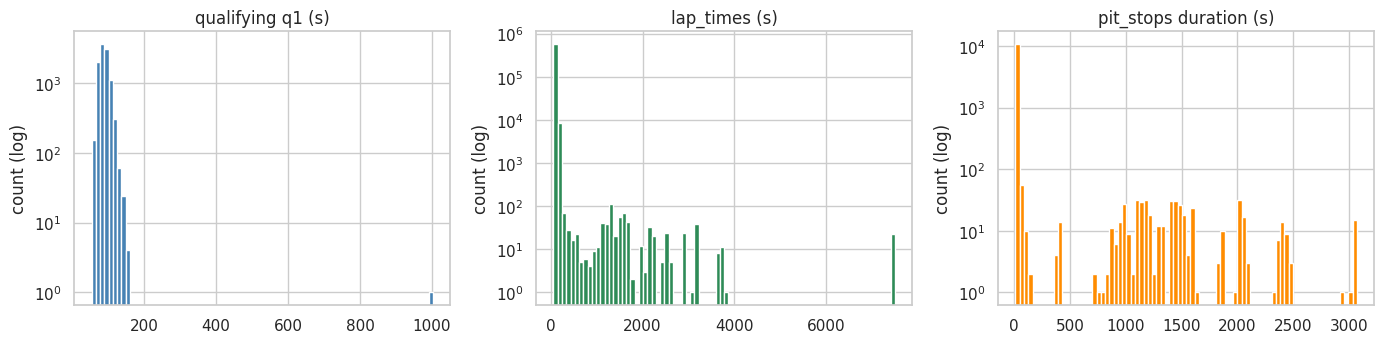

In [14]:
rc = clean["races"][["raceId", "year", "round", "name"]]
dr = clean["drivers"][["driverId", "surname"]]
ctx = lambda df: df.merge(rc, on="raceId", how="left").merge(dr, on="driverId", how="left")

# ---- 1) qualifying: absolute and relative outliers ----
q = ctx(clean["qualifying"])
q["q1_ratio"] = q["q1_sec"] / q.groupby("raceId")["q1_sec"].transform("median")
cols_q = ["raceId", "year", "name", "surname", "q1", "q2", "q3", "q1_ratio"]

print("qualifying rows with q1 > 200 s:", int((q.q1_sec > 200).sum()))
print("qualifying rows with q1 > 1.3 x race median:", int((q.q1_ratio > 1.3).sum()))
print("\nSlowest q1 relative to its own race:")
display(q.sort_values("q1_ratio", ascending=False).head(8)[cols_q])

print("\nFastest q1 / q3 laps overall (which circuit?):")
display(q.sort_values("q3_sec").head(3)[cols_q])

# ---- 2) lap_times ----
lt = ctx(clean["lap_times"])
lt["ratio"] = lt["time_sec"] / lt.groupby("raceId")["time_sec"].transform("median")
print("\nlap_times > 300 s:", int((lt.time_sec > 300).sum()), "of", len(lt))
display(lt.sort_values("time_sec", ascending=False).head(6)[["raceId", "year", "name", "surname", "lap", "time", "ratio"]])
print("Fastest laps:")
display(lt.sort_values("time_sec").head(3)[["raceId", "year", "name", "surname", "lap", "time"]])

# ---- 3) pit_stops ----
ps = ctx(clean["pit_stops"])
print("\npit_stops > 120 s:", int((ps.duration_sec > 120).sum()), "of", len(ps))
display(ps.sort_values("duration_sec", ascending=False).head(6)[["raceId", "year", "name", "surname", "stop", "lap", "duration"]])

# ---- 4) plot (log scale so the outliers are visible next to the bulk) ----
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(q["q1_sec"].dropna(), bins=80, color="steelblue"); ax[0].set_yscale("log")
ax[0].set_title("qualifying q1 (s)")
ax[1].hist(lt["time_sec"], bins=80, color="seagreen"); ax[1].set_yscale("log")
ax[1].set_title("lap_times (s)")
ax[2].hist(ps["duration_sec"], bins=80, color="darkorange"); ax[2].set_yscale("log")
ax[2].set_title("pit_stops duration (s)")
for a in ax: a.set_ylabel("count (log)")
plt.tight_layout(); plt.show()

## 8. Rebuilding the modelling base from typed tables

The base is rebuilt from the typed tables using exactly the rules above, then enriched with **pre-race** context only: circuit country, driver nationality and date of birth, and qualifying position and times (`validate="1:1"` merges, so any key problem would raise an error).

**Check:** the typed rebuild reproduces the earlier waterfall exactly: 24,724 rows, podium rate 0.1359. There are 0 rows with a missing circuit country or nationality.

In [15]:
# ---------- 1) outlier flags on the typed tables ----------
q = clean["qualifying"]
q["q1_suspect"] = q["q1"].map(to_seconds) > 200
q.loc[q["q1_suspect"], "q1_sec"] = np.nan          # raw q1 string kept for audit
print("q1 values set to NaN:", int(q["q1_suspect"].sum()))

lt = clean["lap_times"]
lt["lap_suspect"] = lt["time_sec"] > 300
ps = clean["pit_stops"]
ps["pit_duration_suspect"] = ps["duration_sec"] > 120
print("lap_times flagged:", int(lt.lap_suspect.sum()), "| pit_stops flagged:", int(ps.pit_duration_suspect.sum()))

# ---------- 2) rebuild the modelling base from typed tables ----------
R = clean["results"].copy()
R["status"] = R["statusId"].map(clean["status"].set_index("statusId")["status"])
rcs = clean["races"].set_index("raceId")
R["year"] = R["raceId"].map(rcs["year"]).astype(int)
R["grid"] = R["grid"].astype(int)
R["positionOrder"] = R["positionOrder"].astype(int)
R["laps"] = R["laps"].astype(int)
key = ["raceId", "driverId"]

best = R.groupby(key)["positionOrder"].min().rename("positionOrder_best").reset_index()
R["grid_pos"] = R["grid"].where(R["grid"] > 0)
start_row = R.sort_values(key + ["grid_pos", "resultId"]).drop_duplicates(key, keep="first")
n_raw = R.groupby(key).size().rename("n_rows_raw").reset_index()

B = (start_row.merge(best, on=key, validate="1:1").merge(n_raw, on=key, validate="1:1"))
B["was_duplicated"] = B["n_rows_raw"] > 1
B["podium"] = (B["positionOrder_best"] <= 3).astype(int)
B["grid_is_zero"] = (B["grid"] == 0).astype(int)
B["grid_clean"] = B["grid_pos"]
B["is_indy500"] = B["raceId"].isin(indy_ids.astype(int))
B["is_nonstarter"] = B["grid_pos"].isna() & (B["laps"] == 0)
B["is_pitlane_start"] = B["grid_pos"].isna() & (B["laps"] > 0)

# ---------- 3) attach race and qualifying context (pre-race only) ----------
B = B.merge(clean["races"][["raceId", "circuitId", "round", "date"]], on="raceId", how="left", validate="m:1")
B = B.merge(clean["circuits"][["circuitId", "country"]].rename(columns={"country": "circuit_country"}),
            on="circuitId", how="left", validate="m:1")
B = B.merge(clean["drivers"][["driverId", "nationality", "dob"]], on="driverId", how="left", validate="m:1")

qq = clean["qualifying"][["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec", "q1_suspect"]]
print("\nqualifying (raceId, driverId) unique:", not qq.duplicated(key).any())
qq = qq.rename(columns={"position": "quali_position"})
B = B.merge(qq, on=key, how="left", validate="1:1")
B["has_quali"] = B["quali_position"].notna()

# ---------- 4) final modelling base ----------
model_base = B[~B.is_indy500 & ~B.is_nonstarter].copy().reset_index(drop=True)

assert not model_base.duplicated(key).any()
assert model_base["podium"].isin([0, 1]).all()
print("\nRows:", len(model_base), "| podium rate:", round(model_base.podium.mean(), 4),
      "| expected 24724 rows, rate 0.1359")
print("Merge check - rows with no circuit country:", int(model_base.circuit_country.isna().sum()),
      "| no nationality:", int(model_base.nationality.isna().sum()))
print("Pit-lane starts:", int(model_base.is_pitlane_start.sum()))

# ---------- 5) qualifying vs grid: how often do they differ? ----------
mq = model_base[model_base.has_quali & model_base.grid_clean.notna()]
diff = (mq["quali_position"] != mq["grid_clean"])
print(f"\nRows with both quali_position and grid: {len(mq)} | differ: {int(diff.sum())} ({diff.mean():.1%})")
display(mq.assign(decade=(mq.year // 10) * 10).groupby("decade")
        .apply(lambda g: pd.Series({"rows": len(g), "pct_differ": (g.quali_position != g.grid_clean).mean()}))
        .round(3))

q1 values set to NaN: 1
lap_times flagged: 708 | pit_stops flagged: 481

qualifying (raceId, driverId) unique: True

Rows: 24724 | podium rate: 0.1359 | expected 24724 rows, rate 0.1359
Merge check - rows with no circuit country: 0 | no nationality: 0
Pit-lane starts: 72

Rows with both quali_position and grid: 10407 | differ: 2422 (23.3%)


,rows,pct_differ
decade,,
1990,1392.0,0.020
2000,2685.0,0.185
2010,4249.0,0.313
2020,2081.0,0.273


## Verification: the "after" EDA

The "before" EDA measured placeholders, `grid == 0` and key integrity on the raw tables. This section repeats those measurements on the cleaned data.

- **Placeholders:** 0 placeholder strings remain in any clean table, and in every column the NaN count after cleaning equals the placeholder count before (asserted). Each raw placeholder became exactly one NaN.
- **`grid`:** the raw column has a spike of 1,638 rows at 0, which `grid_clean` removes. Only the 72 pit-lane starts remain as NaN.
- **Podium rate by grid slot:** it falls from about 65% at pole to under 10% beyond P8. This is the evidence for keeping `grid_clean` as a feature. It shows association, not causation.
- **Keys:** all 14 primary keys remain unique and non-null, and all 23 foreign keys still reconcile on the typed tables.

Placeholder strings left in clean tables: 0
Columns where NaN count after != placeholders before: 0


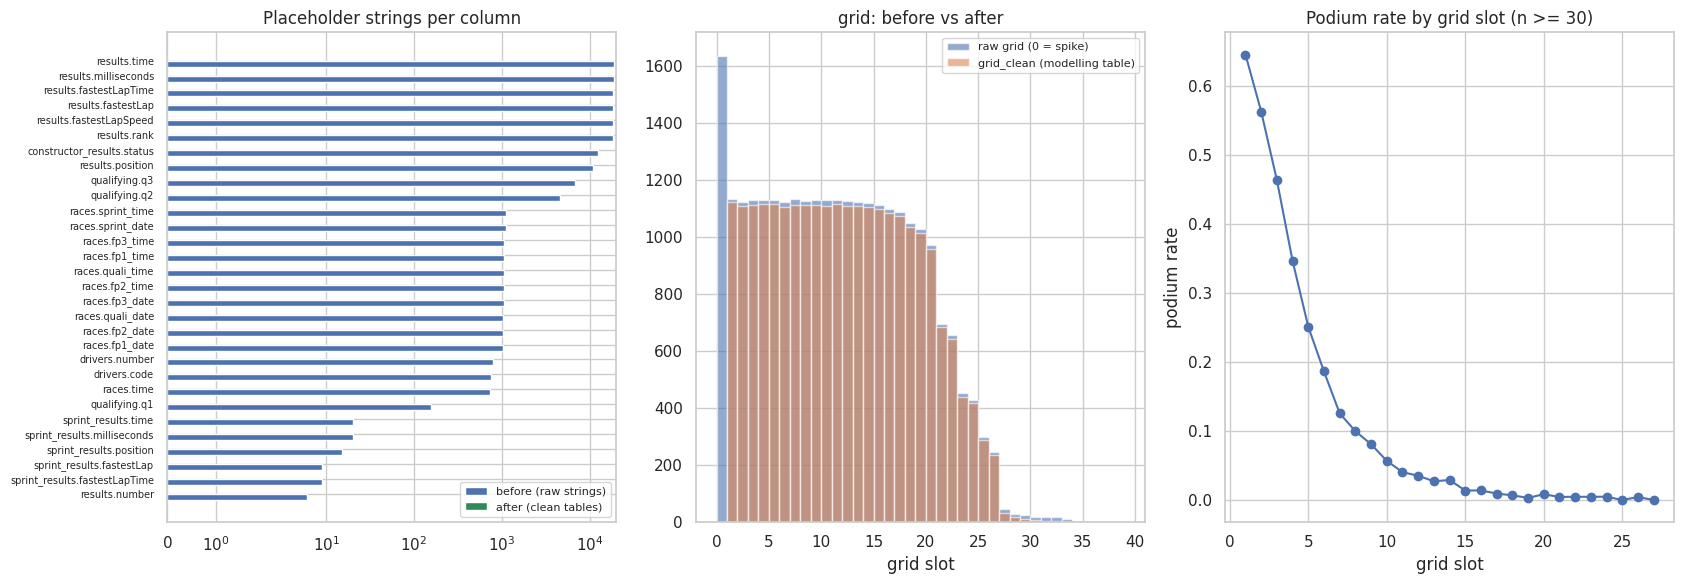


PK failures on clean tables: [] | FK failures on clean tables: []


In [16]:
# ---------- 1) placeholders: before vs after, measured ----------
rows = []
for t in TABLES:
    for c in raw[t].columns:
        before = int(raw[t][c].str.strip().isin(SENTINELS).sum())
        col = clean[t][c]
        after_str = int((col.notna() & col.astype(str).str.strip().isin(SENTINELS)).sum())
        rows.append({"table": t, "column": c, "placeholders_before": before,
                     "placeholder_strings_after": after_str, "NaN_after": int(col.isna().sum())})
chk = pd.DataFrame(rows)
chk["reconciles"] = chk.placeholders_before == chk.NaN_after
print("Placeholder strings left in clean tables:", int(chk.placeholder_strings_after.sum()))
print("Columns where NaN count after != placeholders before:", int((~chk.reconciles).sum()))
assert chk.placeholder_strings_after.sum() == 0 and chk.reconciles.all()

aff = chk[chk.placeholders_before > 0].copy()
aff["label"] = aff.table + "." + aff.column
aff = aff.sort_values("placeholders_before")
fig, ax = plt.subplots(1, 3, figsize=(17, 6))
y = np.arange(len(aff))
ax[0].barh(y - 0.2, aff.placeholders_before, 0.4, label="before (raw strings)")
ax[0].barh(y + 0.2, aff.placeholder_strings_after, 0.4, label="after (clean tables)", color="seagreen")
ax[0].set_yticks(y); ax[0].set_yticklabels(aff.label, fontsize=7)
ax[0].set_xscale("symlog"); ax[0].legend(fontsize=8); ax[0].set_title("Placeholder strings per column")

# ---------- 2) grid before vs after + podium rate by grid slot ----------
ax[1].hist(R["grid"], bins=range(0, 40), alpha=0.6, label="raw grid (0 = spike)")
ax[1].hist(model_base["grid_clean"].dropna(), bins=range(0, 40), alpha=0.6, label="grid_clean (modelling table)")
ax[1].set_title("grid: before vs after"); ax[1].set_xlabel("grid slot"); ax[1].legend(fontsize=8)

pr = model_base.dropna(subset=["grid_clean"]).groupby("grid_clean")["podium"].agg(["mean", "size"])
pr = pr[pr["size"] >= 30]
ax[2].plot(pr.index, pr["mean"], marker="o")
ax[2].set_title("Podium rate by grid slot (n >= 30)"); ax[2].set_xlabel("grid slot"); ax[2].set_ylabel("podium rate")
plt.tight_layout(); plt.show()

# ---------- 3) key audit repeated on the cleaned tables ----------
bad_pk = []
for t, cols in PK.items():
    df = clean[t]
    if df[cols].isna().any(axis=1).any() or df.duplicated(cols).any():
        bad_pk.append(t)
bad_fk = []
for child, ccol, parent, pcol in FK:
    c = clean[child][ccol].dropna()
    if not c.isin(set(clean[parent][pcol].dropna())).all():
        bad_fk.append((child, ccol))
print("\nPK failures on clean tables:", bad_pk, "| FK failures on clean tables:", bad_fk)
assert not bad_pk and not bad_fk

## 9. Qualifying coverage drift

**Coverage per season** (share of modelling rows with a qualifying record):
- 1950-1993: none. `qualifying.csv` starts in **1994** in our copy, not the "mid-1990s" guess.
- 1994-95 are about 94-100% covered, then coverage collapses: 1996-2002 is 6-59%. `race_cov` tracks row coverage almost exactly, so whole races are missing.
- From **2003** coverage is sustained at >= 95% of races in every later season.

**Q2 and Q3** are filled from 2005 (28%) and 2006 respectively. From 2006, 27% of rows have no Q2 time and 54% no Q3 time. That missingness is **structural**: a driver eliminated in Q1 or Q2 has no later time. If a driver has a Q3 time, his position is <= 10 in 99.9% of cases. Therefore NaN means "eliminated or no time set", and these must **never be mean-imputed**.

**Consequence for modelling:** qualifying features are reliable only from 2003. The training window must either start there or use missing-indicators for the earlier years.

## 10. Qualifying position is not grid position

Among 10,407 rows with both values, 23.3% differ. By decade: 2.0% (1990s), 18.5% (2000s), 31.3% (2010s), 27.3% (2020s).

- **Size of shifts:** median shift is 1 place, and 63% of differing rows shift by exactly 1. This is the knock-on effect of a single penalty moving everyone behind. 10.6% shift by 5 or more places.
- **Sprint weekends:** in 2021-22 the sprint result set the Sunday grid. Those weekends differ in 88% (2021) and 81% (2022) of rows against 26-29% on normal weekends. From 2023 the gap disappears (31% vs 23% in 2023, 24% vs 22% in 2024).
- **Early years:** I first suspected qualifying position was copied from grid before 2004. The race-level check does not support that: the 7 early races with differences show plausible one-place shifts (e.g. 1995 Japanese GP, where drivers 14-24 all shift by 1). Low early rates reflect rare grid penalties. Two **unexplained anomalies** are kept as a limitation: the exact 5 <-> 14 swap of Villeneuve and Trulli at the 1999 San Marino GP, and the Fontana 22 -> 14 move at the 1997 British GP.

**Working rule:** use 2003 onward as the primary window for Question 1's qualifying-vs-grid comparison.

First season with any qualifying rows: 1994
First season where >=95% of races have qualifying data: 1995

Row-level qualifying coverage by decade:


,row_cov
decade,
1950,0.000
1960,0.000
1970,0.000
1980,0.000
1990,0.358
2000,0.739
2010,0.995
2020,1.000


,rows,row_cov_quali,row_cov_q1,row_cov_q2,row_cov_q3,race_cov
year,,,,,,
1993,405,0.00,0.00,0.00,0.00,0.00
1994,415,0.94,0.94,0.00,0.00,0.94
1995,417,1.00,0.94,0.00,0.00,1.00
1996,338,0.44,0.43,0.00,0.00,0.44
1997,374,0.59,0.59,0.00,0.00,0.59
1998,347,0.44,0.44,0.00,0.00,0.44
1999,351,0.19,0.18,0.00,0.00,0.19
2000,371,0.24,0.24,0.00,0.00,0.24
2001,373,0.06,0.06,0.00,0.00,0.06



Rows with a qualifying row but no q1 time: 156 of 10478


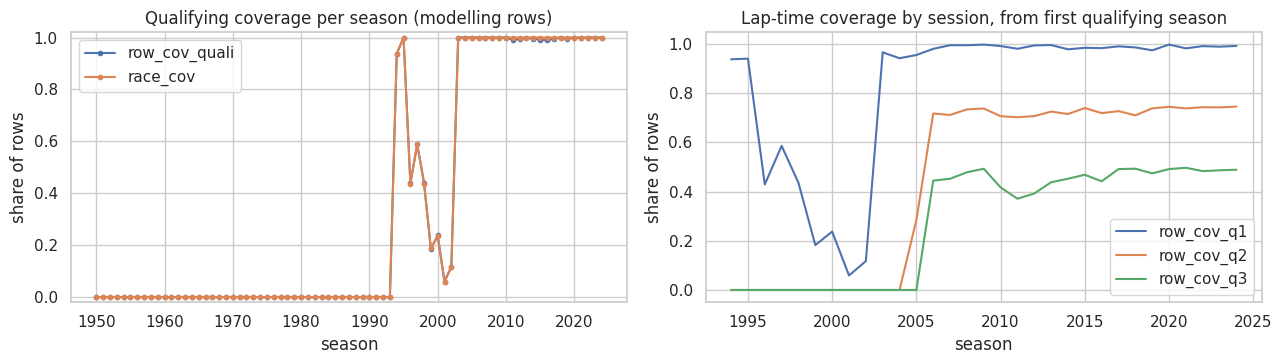


Among differing rows: median |shift| = 1 | shift == 1: 63.1% | shift >= 5: 10.6%

Sprint effect, 2021-2024:


rows  pct_differ  mean_abs_shift
year is_sprint                                  
2021 False       371       0.264           0.647
     True         56       0.875           2.161
2022 False       372       0.293           0.981
     True         57       0.807           3.175
2023 False       313       0.227           0.377
     True        109       0.312           0.486
2024 False       349       0.221           0.361
     True        119       0.235           0.496

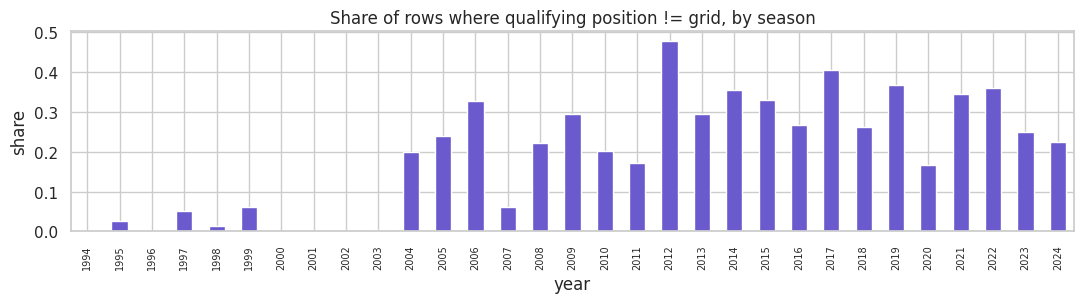

In [17]:
mb = model_base.copy()

# ---- 1) coverage per season ----
cov = mb.groupby("year").agg(
    rows=("podium", "size"),
    row_cov_quali=("has_quali", "mean"),
    row_cov_q1=("q1_sec", lambda s: s.notna().mean()),
    row_cov_q2=("q2_sec", lambda s: s.notna().mean()),
    row_cov_q3=("q3_sec", lambda s: s.notna().mean()),
)
cov["race_cov"] = mb.groupby(["year", "raceId"])["has_quali"].any().groupby("year").mean()

first_any = cov.index[cov.row_cov_quali > 0].min()
first_full = cov.index[cov.race_cov >= 0.95].min()
print("First season with any qualifying rows:", first_any)
print("First season where >=95% of races have qualifying data:", first_full)
print("\nRow-level qualifying coverage by decade:")
display(mb.assign(decade=(mb.year // 10) * 10).groupby("decade")["has_quali"].mean().round(3).to_frame("row_cov"))
display(cov.loc[first_any - 1: first_any + 12].round(2))

# among rows that do have a quali row, how many are missing q1 (no time set)?
hq = mb[mb.has_quali]
print(f"\nRows with a qualifying row but no q1 time: {int(hq.q1_sec.isna().sum())} of {len(hq)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
cov[["row_cov_quali", "race_cov"]].plot(ax=ax[0], marker=".")
ax[0].set_title("Qualifying coverage per season (modelling rows)"); ax[0].set_ylim(-0.02, 1.02)
cov[["row_cov_q1", "row_cov_q2", "row_cov_q3"]].loc[first_any:].plot(ax=ax[1])
ax[1].set_title("Lap-time coverage by session, from first qualifying season")
for a in ax: a.set_xlabel("season"); a.set_ylabel("share of rows")
plt.tight_layout(); plt.show()

# ---- 2) why do qualifying position and grid differ? ----
m = mb[mb.has_quali & mb.grid_clean.notna()].copy()
m["quali_position"] = m["quali_position"].astype(float)
m["differ"] = m.quali_position != m.grid_clean
m["abs_shift"] = (m.quali_position - m.grid_clean).abs()
sprint_ids = set(clean["sprint_results"]["raceId"].astype(int))
m["is_sprint"] = m.raceId.isin(sprint_ids)

d = m[m.differ]
print(f"\nAmong differing rows: median |shift| = {d.abs_shift.median():.0f} | "
      f"shift == 1: {(d.abs_shift == 1).mean():.1%} | shift >= 5: {(d.abs_shift >= 5).mean():.1%}")

print("\nSprint effect, 2021-2024:")
display(m[m.year >= 2021].groupby(["year", "is_sprint"]).agg(
    rows=("differ", "size"), pct_differ=("differ", "mean"), mean_abs_shift=("abs_shift", "mean")).round(3))

# differing rows per season (plot)
m.groupby("year")["differ"].mean().plot(kind="bar", figsize=(11, 3.2), color="slateblue")
plt.title("Share of rows where qualifying position != grid, by season")
plt.ylabel("share"); plt.xticks(fontsize=7); plt.tight_layout(); plt.show()

First season from which race coverage stays >= 95% in every later season: 2003
Seasons since 1994 with race coverage < 95%: [1994, 1996, 1997, 1998, 1999, 2000, 2001, 2002]


,rows,grid_clean,quali_position,q1_sec,q2_sec,q3_sec
era,,,,,,
1950-1993,12424,0.000,1.000,1.000,1.000,1.000
1994-2002,3344,0.000,0.538,0.548,1.000,1.000
2003-2005,1056,0.000,0.000,0.046,0.899,1.000
2006-2024,7900,0.009,0.003,0.012,0.274,0.541


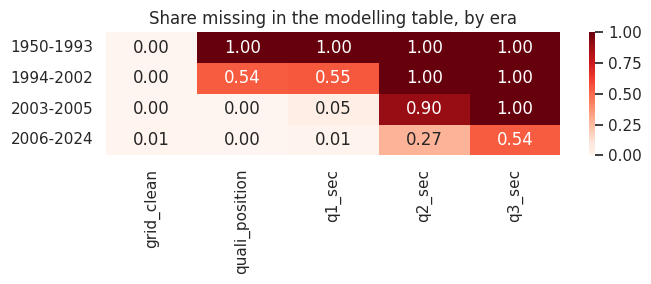


2006+: q3 present -> quali_position <= 10 : 0.999
2006+: quali_position <= 10 -> q3 present : 0.968

Races where qualifying position differs from grid for at least one driver:


year,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008
races_with_any_diff,0,1,0,2,1,2,0,0,0,1,10,12,11,3,10
races_compared,15,17,7,10,7,3,4,1,2,16,18,19,18,17,18


In [18]:
mb = model_base.copy()

# ---- 1) sustained coverage (replaces the misleading first_full from Cell 15) ----
ok = cov["race_cov"] >= 0.95
sustained = next(y for y in cov.index if ok.loc[y:].all())
low = [y for y in cov.index if y >= first_any and not ok.loc[y]]
print("First season from which race coverage stays >= 95% in every later season:", sustained)
print(f"Seasons since {first_any} with race coverage < 95%:", low)

# ---- 2) missingness of pre-race columns by era (the 'after' view of the modelling table) ----
def era(y):
    if y < 1994: return "1950-1993"
    if y < 2003: return "1994-2002"
    if y < 2006: return "2003-2005"
    return "2006-2024"

mb["era"] = mb["year"].map(era)
cols = ["grid_clean", "quali_position", "q1_sec", "q2_sec", "q3_sec"]
miss = mb.groupby("era")[cols].agg(lambda s: s.isna().mean()).round(3)
miss.insert(0, "rows", mb.groupby("era").size())
display(miss)

plt.figure(figsize=(7, 3))
sns.heatmap(miss[cols].astype(float), annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1)
plt.title("Share missing in the modelling table, by era"); plt.ylabel("")
plt.tight_layout(); plt.show()

# is Q2/Q3 missingness structural (= eliminated)?
m6 = mb[(mb.year >= 2006) & mb.has_quali]
print("\n2006+: q3 present -> quali_position <= 10 :",
      round((m6.loc[m6.q3_sec.notna(), "quali_position"] <= 10).mean(), 3))
print("2006+: quali_position <= 10 -> q3 present :",
      round(m6.loc[m6.quali_position <= 10, "q3_sec"].notna().mean(), 3))

# ---- 3) mirror test: per race, does quali position ever differ from grid? ----
chk_races = m.groupby(["year", "raceId"])["differ"].any().groupby("year").agg(["sum", "size"])
chk_races.columns = ["races_with_any_diff", "races_compared"]
print("\nRaces where qualifying position differs from grid for at least one driver:")
display(chk_races.loc[1994:2008].T)

## 11. Leakage control and hand-off

Every column of the modelling table is labelled as key, target, pre-race, audit-only, filter flag or post-race leak (`data_dictionary.csv`); the cell stops if any column is unclassified.

Two helper columns of mine are leaks and are excluded: `was_duplicated` and `n_rows_raw` (a shared drive is only known after the race). `is_nonstarter` and `is_pitlane_start` are built from `laps`, so they are filter flags only. The hand-off keeps the pit-lane information through `grid_is_zero`, which does not use `laps`.

**Hand-off file `model_base_prerace.csv`:** 24,724 rows x 19 columns (keys, target, pre-race features only); asserts check no banned column, unique grain, binary target and the expected row count and podium rate. `model_base_full_audit.csv` contains leakage columns and is for audit only.

In [19]:
# ---- 1) the early races where quali position != grid (1994-2003) ----
names = clean["races"].set_index("raceId")["name"]
surn = clean["drivers"].set_index("driverId")["surname"]
early = m[m.differ & (m.year <= 2003)].copy()
early["race"] = early["raceId"].map(names)
early["driver"] = early["driverId"].map(surn)
display(early.sort_values(["year", "raceId", "quali_position"])
        [["year", "race", "driver", "quali_position", "grid_clean", "abs_shift"]])

# top-10 qualifiers without a Q3 time (2006+), to see what they are
t10 = mb[(mb.year >= 2006) & mb.has_quali & (mb.quali_position <= 10) & mb.q3_sec.isna()]
print("\nTop-10 qualifiers with no Q3 time:", len(t10))
print(t10["year"].value_counts().sort_index().to_string())

# ---- 2) column roles: nothing in model_base may stay unclassified ----
ROLE = {
    # keys
    "raceId": "key", "driverId": "key", "resultId": "key (start row; audit only)",
    # target
    "podium": "TARGET",
    # pre-race features / context
    "grid_clean": "pre-race", "grid_is_zero": "pre-race", "constructorId": "pre-race",
    "quali_position": "pre-race", "q1_sec": "pre-race", "q2_sec": "pre-race", "q3_sec": "pre-race",
    "has_quali": "pre-race", "q1_suspect": "pre-race (audit flag)",
    "year": "pre-race", "round": "pre-race", "date": "pre-race", "circuitId": "pre-race",
    "circuit_country": "pre-race", "nationality": "pre-race", "dob": "pre-race",
    "number": "pre-race (low value, identity drifts)",
    # table-building flags, used for filtering only
    "is_indy500": "filter flag", "is_nonstarter": "filter flag (uses laps; post-race)",
    "is_pitlane_start": "filter flag (uses laps; post-race)", "grid": "audit only (raw grid, 0 = no slot)",
    "grid_pos": "audit only (same as grid_clean)",
    # post-race: leakage
    "was_duplicated": "POST-RACE LEAK (shared drive known after race)",
    "n_rows_raw": "POST-RACE LEAK (shared drive known after race)",
    "positionOrder_best": "POST-RACE LEAK (defines target)",
    "positionOrder": "POST-RACE LEAK", "position": "POST-RACE LEAK", "positionText": "POST-RACE LEAK",
    "points": "POST-RACE LEAK", "laps": "POST-RACE LEAK", "time": "POST-RACE LEAK",
    "milliseconds": "POST-RACE LEAK", "fastestLap": "POST-RACE LEAK", "rank": "POST-RACE LEAK",
    "fastestLapTime": "POST-RACE LEAK", "fastestLapSpeed": "POST-RACE LEAK",
    "fastestLapTime_sec": "POST-RACE LEAK", "statusId": "POST-RACE LEAK", "status": "POST-RACE LEAK",
}
unclassified = [c for c in model_base.columns if c not in ROLE]
extra = [c for c in ROLE if c not in model_base.columns]
print("\nUnclassified columns:", unclassified)
print("Roles listed but not in table:", extra)
assert not unclassified, "classify every column before exporting"

dictionary = (pd.DataFrame({"column": list(ROLE), "role": list(ROLE.values())})
              .assign(dtype=lambda d: d.column.map(model_base.dtypes.astype(str)),
                      pct_missing=lambda d: d.column.map(model_base.isna().mean().round(4)))
              .sort_values("role"))
display(dictionary)

# ---- 3) export for Member 2 ----
OUT = "/kaggle/working"
#leaks = [c for c, r in ROLE.items() if r.startswith("POST-RACE")]
#handoff = model_base.drop(columns=leaks)           # leakage columns removed from the hand-off file
#handoff.to_csv(f"{OUT}/model_base_prerace.csv", index=False)
#model_base.to_csv(f"{OUT}/model_base_full_audit.csv", index=False)
dictionary.to_csv(f"{OUT}/data_dictionary.csv", index=False)
dup_log.to_csv(f"{OUT}/duplicate_handling_log.csv", index=False)
#print("\nExported:", sorted(os.listdir(OUT)))
#print("Hand-off shape:", handoff.shape, "| columns:", list(handoff.columns))

,year,race,driver,quali_position,grid_clean,abs_shift
5429,1995,Japanese Grand Prix,Katayama,14.0,13.0,1.0
5430,1995,Japanese Grand Prix,Morbidelli,15.0,14.0,1.0
5436,1995,Japanese Grand Prix,Wendlinger,16.0,15.0,1.0
5431,1995,Japanese Grand Prix,Lamy,17.0,16.0,1.0
5426,1995,Japanese Grand Prix,Badoer,18.0,17.0,1.0
5434,1995,Japanese Grand Prix,Inoue,19.0,18.0,1.0
5432,1995,Japanese Grand Prix,Montermini,20.0,19.0,1.0
5424,1995,Japanese Grand Prix,Diniz,21.0,20.0,1.0
5435,1995,Japanese Grand Prix,Moreno,22.0,21.0,1.0
5437,1995,Japanese Grand Prix,Gachot,23.0,22.0,1.0



Top-10 qualifiers with no Q3 time: 121
year
2006     4
2007     3
2008     4
2009     2
2011    21
2012    13
2013     7
2014     6
2015    13
2016     6
2017     3
2018     3
2019    11
2020     3
2021     2
2022     8
2023     6
2024     6

Unclassified columns: []
Roles listed but not in table: []


,column,role,dtype,pct_missing
42,status,POST-RACE LEAK,object,0.0000
29,positionOrder,POST-RACE LEAK,int64,0.0000
30,position,POST-RACE LEAK,Int64,0.3714
31,positionText,POST-RACE LEAK,object,0.0000
32,points,POST-RACE LEAK,float64,0.0000
34,time,POST-RACE LEAK,object,0.6948
35,milliseconds,POST-RACE LEAK,Int64,0.6948
33,laps,POST-RACE LEAK,int64,0.0000
37,rank,POST-RACE LEAK,Int64,0.6563
38,fastestLapTime,POST-RACE LEAK,object,0.6662


In [20]:
# 1) q1_suspect as a real boolean (no qualifying row -> False)
model_base["q1_suspect"] = model_base["q1_suspect"].fillna(False).astype(bool)
print("q1_suspect:", model_base["q1_suspect"].dtype, "| True rows:", int(model_base["q1_suspect"].sum()))

# 2) hand-off = only key / target / pre-race columns; audit, filter and post-race columns excluded
handoff_cols = [c for c, r in ROLE.items()
                if r.startswith(("key", "TARGET", "pre-race")) and "audit" not in r]
handoff_cols = [c for c in handoff_cols if c != "resultId"]       # audit key, not needed for modelling
handoff = model_base[handoff_cols].copy()

# 3) safety checks
banned = {c for c, r in ROLE.items()
          if ("post-race" in r.lower()) or r.startswith(("filter", "audit"))}
assert banned.isdisjoint(handoff.columns), banned & set(handoff.columns)
assert not handoff.duplicated(["raceId", "driverId"]).any()
assert handoff["podium"].isin([0, 1]).all()
assert len(handoff) == 24724 and round(handoff.podium.mean(), 4) == 0.1359

# 4) export (overwrites the earlier files)
handoff.to_csv(f"{OUT}/model_base_prerace.csv", index=False)
model_base.to_csv(f"{OUT}/model_base_full_audit.csv", index=False)   # audit only, NOT for modelling

print("Hand-off shape:", handoff.shape)
print("Columns:", list(handoff.columns))
display(handoff.dtypes.astype(str).to_frame("dtype").join(handoff.isna().mean().round(4).to_frame("pct_missing")))

q1_suspect: bool | True rows: 1
Hand-off shape: (24724, 19)
Columns: ['raceId', 'driverId', 'podium', 'grid_clean', 'grid_is_zero', 'constructorId', 'quali_position', 'q1_sec', 'q2_sec', 'q3_sec', 'has_quali', 'year', 'round', 'date', 'circuitId', 'circuit_country', 'nationality', 'dob', 'number']


,dtype,pct_missing
raceId,Int64,0.0000
driverId,Int64,0.0000
podium,int64,0.0000
grid_clean,float64,0.0029
grid_is_zero,int64,0.0000
constructorId,Int64,0.0000
quali_position,Int64,0.5762
q1_sec,float64,0.5825
q2_sec,float64,0.7638
q3_sec,float64,0.8533


,metric,before cleaning,after cleaning
0,Tables loaded / primary keys passing,14 / 14,unchanged (audit only)
1,Foreign-key checks passing,23 of 23,unchanged (audit only)
2,Columns with \N / '' placeholders,30 of 120,0 placeholder strings left
3,Failed type conversions,n/a (all strings),0 of 94 typed columns
4,results rows,26759,24724
5,"Surplus duplicate rows on (raceId, driverId)",91,0
6,Races in table,1125,1114
7,Podium rows (target = 1),3397,3359
8,Podium rate per row,0.1269,0.1359
9,Rows with grid == 0 (hidden sentinel),1638,72


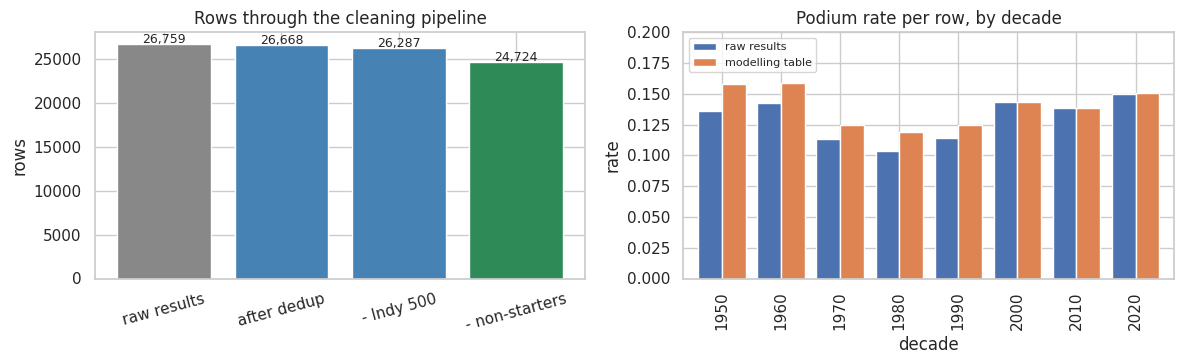

,topic,decision,evidence
0,Sentinels,\N and '' -> NaN in all tables; raw CSVs untouched,30 of 120 columns affected; 68 empty strings only in qualifying q2/q3
1,Typing,Int64 / float / datetime / seconds / timedelta,0 failed conversions; parsed seconds match milliseconds exactly
2,Keys,All PKs unique and non-null; all 23 FKs reconcile,Eagle (constructorId 88) has no results rows; unused
3,Duplicates: target,Best (lowest) positionOrder across a driver's rows in a race,"85 pairs, 91 surplus rows; matches official shared-drive credit"
4,Duplicates: features,"grid and constructor from the row with lowest positive grid, resultId tie-break",Avoids tying grid to the race outcome; 17 pairs have label and features from different rows
5,grid == 0,Treated as missing: grid_clean = NaN plus grid_is_zero flag,"1,638 rows; 72 are real pit-lane starts kept in the table"
6,Indianapolis 500 1950-60,Excluded (is_indy500 flag kept in audit file),"381 rows, 11 races, 36 podium rows; different grid structure, drivers rarely raced elsewhere"
7,Non-starters,Excluded: no positive grid AND laps == 0,"1,563 rows, 0 podiums; caveat: the laps == 0 test is post-race for 13 failure rows since 2010"
8,q1 outlier,"Blundell 1995 Japanese GP, 16:42.640 -> NaN, q1_suspect flag",9.9x race median; next worst is 1.43x; not guessed as 1:42.640
9,Lap and pit outliers,"Kept, flagged (lap_suspect, pit_duration_suspect)","Red-flag races (2011 Canada, 2022 Britain); post-race tables, never features"


Exported: ['before_after_summary.csv', 'cleaning_decisions.csv', 'data_dictionary.csv', 'duplicate_handling_log.csv', 'model_base_full_audit.csv', 'model_base_prerace.csv']


In [21]:
# ---------- 1) before / after summary ----------
n_raw_results = len(R)                       # raw results rows
n_after_dedup = len(B)                       # grain fixed
n_final       = len(model_base)

summary = pd.DataFrame([
    ("Tables loaded / primary keys passing", f"{len(TABLES)} / {int(pk_audit.PASS.sum())}", "unchanged (audit only)"),
    ("Foreign-key checks passing",           f"{int(fk_audit.PASS.sum())} of {len(fk_audit)}", "unchanged (audit only)"),
    ("Columns with \\N / '' placeholders",   f"{len(sent_nonzero)} of {len(sent)}", f"{int(chk.placeholder_strings_after.sum())} placeholder strings left"),
    ("Failed type conversions",              "n/a (all strings)", f"{int(conv_log.failed_conversion.sum())} of {len(conv_log)} typed columns"),
    ("results rows",                         n_raw_results, n_final),
    ("Surplus duplicate rows on (raceId, driverId)", int(R.duplicated(key).sum()), 0),
    ("Races in table",                       R.raceId.nunique(), model_base.raceId.nunique()),
    ("Podium rows (target = 1)",             int((R.positionOrder <= 3).sum()), int(model_base.podium.sum())),
    ("Podium rate per row",                  round((R.positionOrder <= 3).mean(), 4), round(model_base.podium.mean(), 4)),
    ("Rows with grid == 0 (hidden sentinel)", int((R.grid == 0).sum()), int(model_base.grid_is_zero.sum())),
    ("Suspect values flagged",               "-", "1 q1 time set to NaN (q1_suspect); 708 laps and 481 pit stops flagged"),
], columns=["metric", "before cleaning", "after cleaning"])
display(summary)

# ---------- 2) plots: row waterfall + podium rate by decade ----------
steps = ["raw results", "after dedup", "- Indy 500", "- non-starters"]
rows_ = [n_raw_results, n_after_dedup,
         int((~B.is_indy500).sum()), n_final]

dec = lambda df, y: (df[y] // 10) * 10
raw_dec = R.assign(decade=dec(R, "year"), podium_raw=(R.positionOrder <= 3).astype(int)) \
           .groupby("decade")["podium_raw"].mean()
fin_dec = model_base.assign(decade=dec(model_base, "year")).groupby("decade")["podium"].mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(steps, rows_, color=["#888", "steelblue", "steelblue", "seagreen"])
for i, v in enumerate(rows_): ax[0].text(i, v + 150, f"{v:,}", ha="center", fontsize=9)
ax[0].set_title("Rows through the cleaning pipeline"); ax[0].set_ylabel("rows")
ax[0].tick_params(axis="x", rotation=15)
pd.DataFrame({"raw results": raw_dec, "modelling table": fin_dec}).plot(kind="bar", ax=ax[1], width=0.8)
ax[1].set_ylim(0, 0.2)
ax[1].legend(loc="upper left", fontsize=8)
ax[1].set_title("Podium rate per row, by decade"); ax[1].set_ylabel("rate"); ax[1].set_xlabel("decade")
plt.tight_layout(); plt.show()

# ---------- 3) cleaning-decision log (for the report) ----------
decisions = pd.DataFrame([
 ("Sentinels", r"\N and '' -> NaN in all tables; raw CSVs untouched", "30 of 120 columns affected; 68 empty strings only in qualifying q2/q3"),
 ("Typing", "Int64 / float / datetime / seconds / timedelta", "0 failed conversions; parsed seconds match milliseconds exactly"),
 ("Keys", "All PKs unique and non-null; all 23 FKs reconcile", "Eagle (constructorId 88) has no results rows; unused"),
 ("Duplicates: target", "Best (lowest) positionOrder across a driver's rows in a race", "85 pairs, 91 surplus rows; matches official shared-drive credit"),
 ("Duplicates: features", "grid and constructor from the row with lowest positive grid, resultId tie-break", "Avoids tying grid to the race outcome; 17 pairs have label and features from different rows"),
 ("grid == 0", "Treated as missing: grid_clean = NaN plus grid_is_zero flag", "1,638 rows; 72 are real pit-lane starts kept in the table"),
 ("Indianapolis 500 1950-60", "Excluded (is_indy500 flag kept in audit file)", "381 rows, 11 races, 36 podium rows; different grid structure, drivers rarely raced elsewhere"),
 ("Non-starters", "Excluded: no positive grid AND laps == 0", "1,563 rows, 0 podiums; caveat: the laps == 0 test is post-race for 13 failure rows since 2010"),
 ("q1 outlier", "Blundell 1995 Japanese GP, 16:42.640 -> NaN, q1_suspect flag", "9.9x race median; next worst is 1.43x; not guessed as 1:42.640"),
 ("Lap and pit outliers", "Kept, flagged (lap_suspect, pit_duration_suspect)", "Red-flag races (2011 Canada, 2022 Britain); post-race tables, never features"),
 ("Qualifying coverage", "Starts 1994; sustained >= 95% of races only from 2003; Q2 from 2005, Q3 from 2006", "1996-2002 coverage 6-59%; do not mean-impute Q2/Q3 (NaN = eliminated)"),
 ("Qualifying vs grid", "Primary window 2003 onward; 2021-22 sprint weekends: grid = sprint result", "23.3% of rows differ overall; 63% of differences are a 1-place shift"),
 ("Suspect qualifying rows", "1999 San Marino GP: Villeneuve and Trulli swapped 5 <-> 14; 1995 Japanese GP qualifying flagged", "Probable recording errors, cause unverified; report as a limitation"),
 ("Leakage control", "Hand-off file has only key / target / pre-race columns", "19 columns; was_duplicated, n_rows_raw, laps-based flags excluded"),
], columns=["topic", "decision", "evidence"])
pd.set_option("display.max_colwidth", 120)
display(decisions)
decisions.to_csv(f"{OUT}/cleaning_decisions.csv", index=False)
summary.astype(str).to_csv(f"{OUT}/before_after_summary.csv", index=False)
print("Exported:", sorted(f for f in os.listdir(OUT) if f.endswith(".csv")))

# Part 2 — Data analysis and feature engineering (Member 2)

Everything below starts from Member 1's typed tables (`clean`) and the deduplicated, filtered modelling base (`model_base`, 24,724 rows, one per `(raceId, driverId)`). No raw CSV is re-read and nothing in `model_base` is modified in place.

Contents: **12** data-engineering questions (Q1–Q3) · **13** leakage-safe features · **14** feature evidence · **15** train/validation/test split · **16** encoding and preprocessing · **17** hand-off.

In [22]:
import re, json
from scipy import stats

M2_SEED = 42
key = ["raceId", "driverId"]

# shared lookup tables (all from Member 1's typed copies)
races_t   = clean["races"][["raceId", "year", "round", "circuitId", "name", "date"]].copy()
circ_t    = clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"})
constr_t  = clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"})
races_t["raceId"] = races_t["raceId"].astype(int)

# working copy of the modelling base with plain int keys and circuit names
mb2 = model_base.copy()
for c in ["raceId", "driverId", "constructorId", "circuitId"]:
    mb2[c] = mb2[c].astype(int)
mb2 = mb2.merge(circ_t[["circuitId", "circuit"]].astype({"circuitId": int}), on="circuitId", how="left", validate="m:1")
mb2["quali_position"] = mb2["quali_position"].astype("float")
assert not mb2.duplicated(key).any() and len(mb2) == len(model_base)

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n (better than the normal interval for small n)."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.where(n > 0, k / np.maximum(n, 1), np.nan)
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

print("mb2:", mb2.shape, "| seasons", mb2.year.min(), "-", mb2.year.max())

mb2: (24724, 44) | seasons 1950 - 2024


## 12. Data-engineering questions

### Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Joins:** `results` (via `model_base`) → `races` (year, circuitId) → `circuits` (name), and `qualifying` (qualifying position, already attached by Member 1 with a 1:1 merge).

**Grain:** one row per driver per race. A "front-row start" is a row with `grid_clean ∈ {1, 2}` (where the car actually started); a "front-row qualifier" is a row with `quali_position ∈ {1, 2}`. Each race contributes at most two of each.

**Window and missingness:** Member 1 showed qualifying coverage is sustained only from **2003**, so the comparison uses 2003–2024. Pre-hybrid = 2003–2013, hybrid and later = 2014–2024. A circuit needs **≥ 5 races (≥ 10 front-row starts) in a period** to be ranked; with fewer, a single retirement moves the rate by 10+ points.

**Cutoff:** grid and qualifying are both known before the race; only the label (`podium`) is post-race.

In [23]:
q1 = mb2[mb2.year >= 2003].copy()
q1["period"] = np.where(q1.year >= 2014, "2014-2024", "2003-2013")
q1["front_grid"]  = q1["grid_clean"].isin([1, 2])
q1["front_quali"] = q1["quali_position"].isin([1, 2])

# --- grid vs qualifying: how often does the front row by qualifying NOT start from the front row? ---
fq = q1[q1.front_quali]
moved = fq[~fq.front_grid]
print(f"Front-row qualifiers 2003-2024: {len(fq)} | started elsewhere (penalty / pit lane): {len(moved)} ({len(moved)/len(fq):.1%})")
print(f"Podium rate | front-row qualifier who kept the front row : {fq[fq.front_grid].podium.mean():.3f}")
print(f"Podium rate | front-row qualifier who started further back: {moved.podium.mean():.3f}  (n={len(moved)})")
promoted = q1[q1.front_grid & ~q1.front_quali]
print(f"Front-row starters who did NOT qualify there (promoted by others' penalties): {len(promoted)}")

overall = pd.DataFrame({
    "front_row_starts": q1[q1.front_grid].groupby("period").size(),
    "conv_by_grid":     q1[q1.front_grid].groupby("period")["podium"].mean(),
    "conv_by_quali":    q1[q1.front_quali].groupby("period")["podium"].mean()})
display(overall.round(3))

def conversion(df, flag):
    g = df[df[flag]].groupby(["circuit", "period"]).agg(
        races=("raceId", "nunique"), starts=("podium", "size"), podiums=("podium", "sum")).reset_index()
    g["rate"] = g.podiums / g.starts
    g["lo"], g["hi"] = wilson(g.podiums, g.starts)
    return g

conv_g = conversion(q1, "front_grid")
conv_q = conversion(q1, "front_quali")
MIN_RACES = 5
ranked = conv_g[conv_g.races >= MIN_RACES].copy()
ranked["rank"] = ranked.groupby("period")["rate"].rank(ascending=False, method="min")

for p in ["2003-2013", "2014-2024"]:
    t = ranked[ranked.period == p].sort_values(["rate", "starts"], ascending=[False, False])
    print(f"\nTop 8 circuits {p} (front-row start -> podium, >= {MIN_RACES} races):")
    display(t.head(8)[["circuit", "races", "starts", "podiums", "rate", "lo", "hi"]].round(3).reset_index(drop=True))
    print(f"Bottom 5 circuits {p}:")
    display(t.tail(5)[["circuit", "races", "starts", "podiums", "rate", "lo", "hi"]].round(3).reset_index(drop=True))

# --- does the ranking change? circuits ranked in both periods ---
wide = ranked.pivot(index="circuit", columns="period", values="rate").dropna()
rho, p_rho = stats.spearmanr(wide["2003-2013"], wide["2014-2024"])
print(f"\nCircuits ranked in both periods: {len(wide)} | Spearman rank correlation = {rho:.2f} (p = {p_rho:.3f})")
wide["change"] = wide["2014-2024"] - wide["2003-2013"]
display(wide.sort_values("change").round(3).iloc[np.r_[0:4, -4:0]])

# --- qualifying-defined vs grid-defined conversion per circuit (same window) ---
both_def = conv_g.merge(conv_q, on=["circuit", "period"], suffixes=("_grid", "_quali"))
both_def = both_def[both_def.races_grid >= MIN_RACES]
print("Circuit-periods where grid- and quali-defined rates differ:",
      int((both_def.rate_grid.round(6) != both_def.rate_quali.round(6)).sum()), "of", len(both_def),
      f"| mean |difference| = {(both_def.rate_grid - both_def.rate_quali).abs().mean():.3f}")

Front-row qualifiers 2003-2024: 854 | started elsewhere (penalty / pit lane): 36 (4.2%)
Podium rate | front-row qualifier who kept the front row : 0.726
Podium rate | front-row qualifier who started further back: 0.306  (n=36)
Front-row starters who did NOT qualify there (promoted by others' penalties): 36


,front_row_starts,conv_by_grid,conv_by_quali
period,,,
2003-2013,400,0.68,0.672
2014-2024,454,0.76,0.740



Top 8 circuits 2003-2013 (front-row start -> podium, >= 5 races):


,circuit,races,starts,podiums,rate,lo,hi
0,Circuit de Nevers Magny-Cours,6,12,11,0.917,0.646,0.985
1,Istanbul Park,7,14,11,0.786,0.524,0.924
2,Autodromo Nazionale di Monza,11,22,17,0.773,0.566,0.899
3,Circuit de Monaco,11,22,17,0.773,0.566,0.899
4,Silverstone Circuit,11,22,16,0.727,0.518,0.868
5,Circuit de Spa-Francorchamps,9,18,13,0.722,0.491,0.875
6,Suzuka Circuit,9,18,13,0.722,0.491,0.875
7,Hockenheimring,7,14,10,0.714,0.454,0.883


Bottom 5 circuits 2003-2013:


...

Bottom 5 circuits 2014-2024:


,circuit,races,starts,podiums,rate,lo,hi
0,Marina Bay Street Circuit,9,18,13,0.722,0.491,0.875
1,Bahrain International Circuit,12,24,16,0.667,0.467,0.820
2,Baku City Circuit,8,16,10,0.625,0.386,0.815
3,Autódromo Hermanos Rodríguez,9,18,11,0.611,0.386,0.797
4,Hungaroring,11,22,13,0.591,0.387,0.767



Circuits ranked in both periods: 14 | Spearman rank correlation = 0.30 (p = 0.292)


period,2003-2013,2014-2024,change
circuit,,,
Autodromo Nazionale di Monza,0.773,0.727,-0.045
Hungaroring,0.636,0.591,-0.045
Bahrain International Circuit,0.667,0.667,0.000
Silverstone Circuit,0.727,0.750,0.023
Suzuka Circuit,0.722,0.889,0.167
Circuit Gilles Villeneuve,0.600,0.778,0.178
Autódromo José Carlos Pace,0.591,0.789,0.199
Yas Marina Circuit,0.600,0.864,0.264


Circuit-periods where grid- and quali-defined rates differ: 13 of 40 | mean |difference| = 0.018


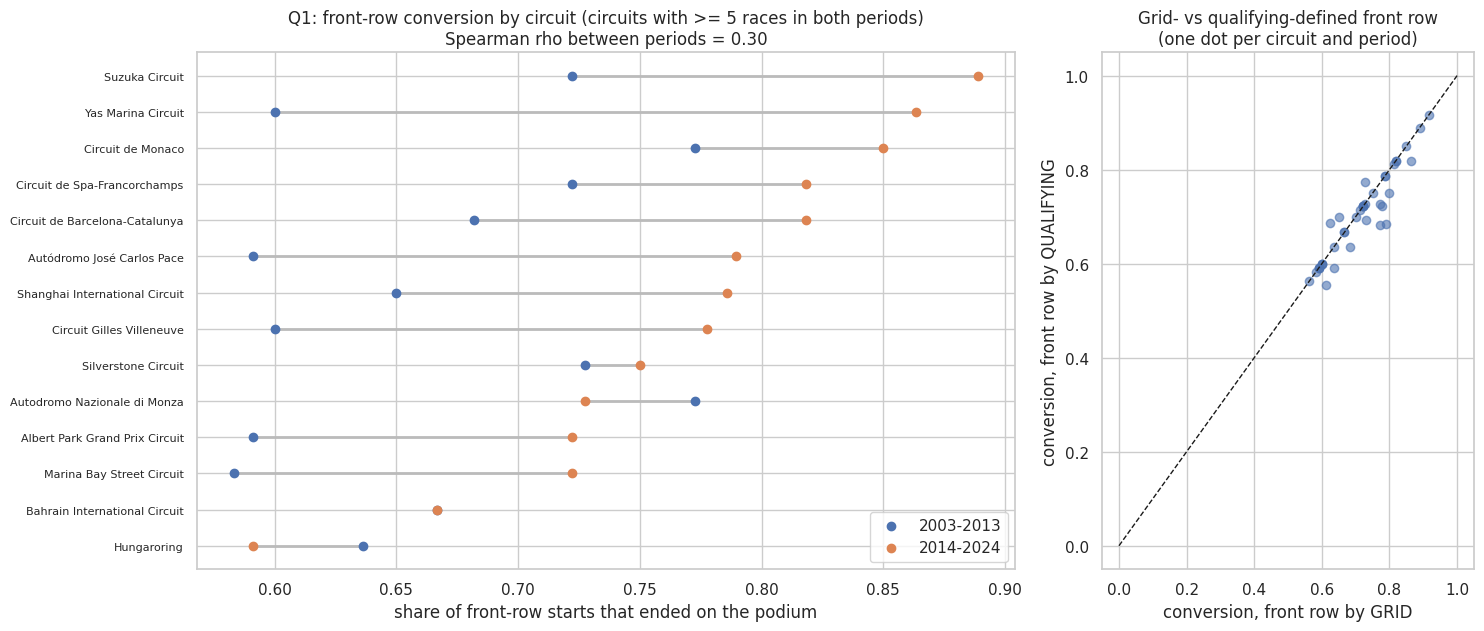

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(15, 0.32 * len(wide) + 2), gridspec_kw={"width_ratios": [2.2, 1]})
w = wide.sort_values("2014-2024")
y = np.arange(len(w))
ax[0].hlines(y, w["2003-2013"], w["2014-2024"], color="#bbb", lw=2)
ax[0].scatter(w["2003-2013"], y, color="#4C72B0", label="2003-2013", zorder=3)
ax[0].scatter(w["2014-2024"], y, color="#DD8452", label="2014-2024", zorder=3)
ax[0].set_yticks(y); ax[0].set_yticklabels(w.index, fontsize=8)
ax[0].set_xlabel("share of front-row starts that ended on the podium")
ax[0].set_title(f"Q1: front-row conversion by circuit (circuits with >= {MIN_RACES} races in both periods)\n"
                f"Spearman rho between periods = {rho:.2f}")
ax[0].legend(loc="lower right")
ax[1].scatter(both_def.rate_grid, both_def.rate_quali, alpha=0.6)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_xlabel("conversion, front row by GRID"); ax[1].set_ylabel("conversion, front row by QUALIFYING")
ax[1].set_title("Grid- vs qualifying-defined front row\n(one dot per circuit and period)")
plt.tight_layout(); plt.show()

**Answer, Q1.**
- **Which circuits convert best:** in **2014–2024**, the highest front-row → podium conversion is at **Suzuka (89%)**, **Yas Marina (86%)** and **Monaco (85%)**; the lowest is at the **Hungaroring (59%)**, **Mexico City (61%)** and **Baku (63%)**. In **2003–2013** the top three were **Magny-Cours (92%, only 6 races)**, **Istanbul (79%)**, and **Monza and Monaco (77%)**.
- **Does the ranking change after 2014? Largely, yes.** Across the 14 circuits ranked in both periods, the Spearman rank correlation is only **0.30 (p = 0.29)**, so the order is close to reshuffled. Conversion rose almost everywhere, from **68% to 76%** of front-row starts overall, consistent with fewer mechanical retirements in the hybrid era (Q3). Yas Marina (+26 pts), Interlagos (+20), Montreal (+18) and Suzuka (+17) rose most; Monza and the Hungaroring were flat or slightly down.
- **Qualifying vs grid:** 36 of 854 front-row qualifiers since 2003 (4.2%) did not start from the front row, mostly because of grid penalties. They reached the podium only **31%** of the time, against **73%** for those who kept the slot. Defining the front row by qualifying instead of grid changes the rate in 13 of 40 circuit-periods, by 1.8 points on average, without reordering the leaders. Grid is the variable that matters at the start.
- **Caveat:** each circuit-period has only 10–24 front-row starts, so the 95% intervals are ±15–25 points wide. Differences of a few points between circuits are not reliable.

### Q2. Do drivers podium more often at home, after controlling for starting position?

**Joins:** `results` → `drivers` (nationality) and `results` → `races` → `circuits` (country). The two columns use different vocabularies ("British" vs "UK"), so a documented **nationality → country** map is needed. Choices: "American" and "American-Italian" → USA (the data spells it both "USA" and "United States"; both are accepted); "Argentine-Italian" → Argentina; "East German" → Germany; "Rhodesian", "Liechtensteiner" and nationalities whose country never hosted a race have no home race.

**Control for grid:** home drivers could simply start further forward (or, in the 1950s–60s, home races attracted local one-off entrants who started at the back). So home and away rows are compared **within the same grid band** (P1, P2, P3, P4–6, P7–10, P11–15, P16+) and pooled with the **Cochran–Mantel–Haenszel** test and the Mantel–Haenszel common odds ratio.

**Missingness / grain:** all seasons 1950–2024 are used because grid exists everywhere. The 72 pit-lane starts (grid unknown) are excluded from this question. Rows are driver-races; the same driver appears many times, so the p-value treats rows as independent, which is optimistic (stated as a limitation).

In [25]:
NAT2COUNTRY = {
    "American": "USA", "American-Italian": "USA", "Argentine": "Argentina", "Argentinian": "Argentina",
    "Argentine-Italian": "Argentina", "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
    "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada", "Chinese": "China", "Dutch": "Netherlands",
    "East German": "Germany", "French": "France", "German": "Germany", "Hungarian": "Hungary", "Indian": "India",
    "Italian": "Italy", "Japanese": "Japan", "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "Portuguese": "Portugal", "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain",
    "Swedish": "Sweden", "Swiss": "Switzerland",
    # nationalities whose country never hosted a championship race in this data -> no home race
    "Chilean": None, "Colombian": None, "Czech": None, "Danish": None, "Finnish": None, "Indonesian": None,
    "Irish": None, "Liechtensteiner": None, "New Zealander": None, "Polish": None, "Rhodesian": None,
    "Thai": None, "Uruguayan": None, "Venezuelan": None,
}
COUNTRY_ALIASES = {"United States": "USA"}

unmapped = set(mb2.nationality.unique()) - set(NAT2COUNTRY)
assert not unmapped, f"add these nationalities to the map: {unmapped}"
host = set(circ_t.country.replace(COUNTRY_ALIASES))
bad = {v for v in NAT2COUNTRY.values() if v and v not in host}
assert not bad, bad

mb2["driver_country"] = mb2["nationality"].map(NAT2COUNTRY)
mb2 = mb2.merge(circ_t[["circuitId", "country"]].astype({"circuitId": int}), on="circuitId", how="left", validate="m:1")
mb2["circuit_country_norm"] = mb2["country"].replace(COUNTRY_ALIASES)
mb2["is_home"] = (mb2["driver_country"] == mb2["circuit_country_norm"]).astype(int)
mb2 = mb2.drop(columns="country")

q2 = mb2[mb2.grid_clean.notna()].copy()
BANDS = [0, 1, 2, 3, 6, 10, 15, 99]
LABELS = ["P1", "P2", "P3", "P4-6", "P7-10", "P11-15", "P16+"]
q2["grid_band"] = pd.cut(q2.grid_clean, BANDS, labels=LABELS)

print(f"Rows: {len(q2)} | home rows: {int(q2.is_home.sum())} ({q2.is_home.mean():.1%})")
print(f"Raw podium rate  home: {q2[q2.is_home==1].podium.mean():.3f} | away: {q2[q2.is_home==0].podium.mean():.3f}")
print(f"Mean grid slot   home: {q2[q2.is_home==1].grid_clean.mean():.1f} | away: {q2[q2.is_home==0].grid_clean.mean():.1f}")

def cmh(df, strata, exposure="is_home", outcome="podium"):
    """Cochran-Mantel-Haenszel test + Mantel-Haenszel OR with Robins-Breslow-Greenland 95% CI."""
    sR = sS = sPR = sPSQR = sQS = num = var = 0.0
    for _, g in df.groupby(strata, observed=True):
        a = ((g[exposure] == 1) & (g[outcome] == 1)).sum(); b = ((g[exposure] == 1) & (g[outcome] == 0)).sum()
        c = ((g[exposure] == 0) & (g[outcome] == 1)).sum(); d = ((g[exposure] == 0) & (g[outcome] == 0)).sum()
        n = a + b + c + d
        if n < 2 or (a + b) == 0 or (c + d) == 0:
            continue
        R, S = a * d / n, b * c / n
        P, Q = (a + d) / n, (b + c) / n
        sR += R; sS += S; sPR += P * R; sPSQR += P * S + Q * R; sQS += Q * S
        num += a - (a + b) * (a + c) / n
        var += (a + b) * (c + d) * (a + c) * (b + d) / (n**2 * (n - 1))
    OR = sR / sS
    se = np.sqrt(sPR / (2 * sR**2) + sPSQR / (2 * sR * sS) + sQS / (2 * sS**2))
    chi2 = (abs(num) - 0.5) ** 2 / var
    return {"MH_odds_ratio": OR, "ci_low": OR * np.exp(-1.96 * se), "ci_high": OR * np.exp(1.96 * se),
            "CMH_chi2": chi2, "p_value": stats.chi2.sf(chi2, 1)}

band_tbl = (q2.groupby(["grid_band", "is_home"], observed=True)["podium"].agg(["mean", "size"]).unstack())
band_tbl.columns = ["away_rate", "home_rate", "away_n", "home_n"]
band_tbl["diff_pts"] = 100 * (band_tbl.home_rate - band_tbl.away_rate)
display(band_tbl[["home_n", "home_rate", "away_n", "away_rate", "diff_pts"]].round(3))

q2["decade"] = (q2.year // 10) * 10
q2["era"] = np.where(q2.year >= 2003, "2003-2024", "1950-2002")
res_q2 = pd.DataFrame({
    "all years, strata = grid band":           cmh(q2, "grid_band"),
    "all years, strata = grid band x decade":  cmh(q2, ["grid_band", "decade"]),
    "1950-2002, strata = grid band":           cmh(q2[q2.era == "1950-2002"], "grid_band"),
    "2003-2024, strata = grid band":           cmh(q2[q2.era == "2003-2024"], "grid_band"),
    "all years, strata = exact grid slot":     cmh(q2.assign(g=q2.grid_clean.clip(upper=20)), "g"),
}).T
display(res_q2.round(4))

Rows: 24652 | home rows: 1943 (7.9%)
Raw podium rate  home: 0.118 | away: 0.138
Mean grid slot   home: 12.7 | away: 11.7


,home_n,home_rate,away_n,away_rate,diff_pts
grid_band,,,,,
P1,84,0.619,1040,0.647,-2.807
P2,77,0.571,1034,0.562,0.953
P3,70,0.529,1044,0.459,6.976
P4-6,227,0.269,3114,0.261,0.796
P7-10,336,0.071,4117,0.092,-2.087
P11-15,415,0.024,5124,0.029,-0.537
P16+,734,0.003,7236,0.007,-0.460


,MH_odds_ratio,ci_low,ci_high,CMH_chi2,p_value
"all years, strata = grid band",0.9487,0.7983,1.1274,0.3015,0.5829
"all years, strata = grid band x decade",0.9205,0.7736,1.0953,0.7753,0.3786
"1950-2002, strata = grid band",0.9809,0.8096,1.1884,0.0212,0.8842
"2003-2024, strata = grid band",0.7482,0.5042,1.1103,1.8460,0.1743
"all years, strata = exact grid slot",0.9564,0.8038,1.1380,0.2054,0.6504


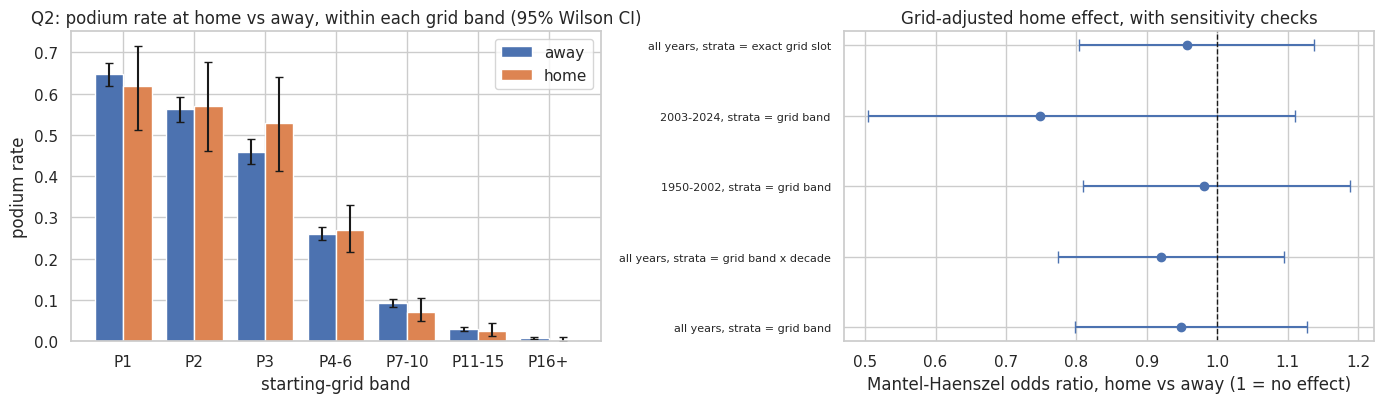

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
bt = band_tbl.reset_index()
x = np.arange(len(bt))
for off, col, ncol, lab, colr in [(-0.2, "away_rate", "away_n", "away", "#4C72B0"), (0.2, "home_rate", "home_n", "home", "#DD8452")]:
    lo, hi = wilson(bt[col] * bt[ncol], bt[ncol])
    ax[0].bar(x + off, bt[col], 0.4, label=lab, color=colr,
              yerr=[bt[col] - lo, hi - bt[col]], capsize=3)
ax[0].set_xticks(x); ax[0].set_xticklabels(bt.grid_band)
ax[0].set_ylabel("podium rate"); ax[0].set_xlabel("starting-grid band")
ax[0].set_title("Q2: podium rate at home vs away, within each grid band (95% Wilson CI)")
ax[0].legend()
r2 = res_q2.reset_index()
ax[1].errorbar(r2.MH_odds_ratio, np.arange(len(r2)),
               xerr=[r2.MH_odds_ratio - r2.ci_low, r2.ci_high - r2.MH_odds_ratio], fmt="o", capsize=4)
ax[1].axvline(1, color="k", ls="--", lw=1)
ax[1].set_yticks(np.arange(len(r2))); ax[1].set_yticklabels(r2["index"], fontsize=8)
ax[1].set_xlabel("Mantel-Haenszel odds ratio, home vs away (1 = no effect)")
ax[1].set_title("Grid-adjusted home effect, with sensitivity checks")
plt.tight_layout(); plt.show()

**Answer, Q2. No: after controlling for starting position there is no home advantage.**
- **Raw rates:** home drivers podium *less* often (**11.8%** vs **13.8%**), because they start further back on average (P12.7 vs P11.7). One reason is that local one-off entrants used to appear at their home race.
- **Within the same grid band**, home and away rates are close in every band (differences of −3 to +7 points, all inside the confidence intervals).
- **Pooled result:** the grid-adjusted Mantel–Haenszel odds ratio is **0.95 (95% CI 0.80–1.13, p = 0.58)**, i.e. no detectable effect.
- **Robustness:** stratifying by exact grid slot, by grid band × decade, or splitting the data at 2003 gives the same conclusion. In the modern era the point estimate is 0.75 (CI 0.50–1.11, p = 0.17).
- **Consequence for modelling:** `is_home` is a weak candidate feature (§15 confirms it adds nothing beyond grid).
- **Limitations:** rows of the same driver are not independent, so the true intervals are wider still. The nationality → country map is a modelling choice (documented above).

### Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Joins:** `results` → `status` (why the race ended) → `races` (year) → `constructors` (name).

**Denominator = race starts.** A row in `model_base` already has a grid slot or a genuine pit-lane start. Rows whose status shows the car never took the start are removed: `Withdrew`, `Did not start`, and `Illness`/`Injury` with 0 laps.

**Numerator = mechanical retirements.** The status table has 100+ free-text reasons, so every status that occurs in 2014–2024 is mapped by hand into one of five groups (the cell stops if any status is unmapped):
- **finished**: `Finished`, `+n Lap(s)`
- **mechanical**: a component of the car failed (engine, power unit, ERS, gearbox, brakes, hydraulics, suspension, cooling, fuel system, electrics, ...)
- **accident / driver**: `Collision`, `Accident`, `Collision damage`, `Spun off`
- **regulatory / other**: `Disqualified`, `Excluded`, `Illness`, `Withdrew`
- **ambiguous**: could be a component failure *or* caused by contact, debris or a pit-stop error: `Retired` (no reason given), `Wheel`, `Wheel nut`, `Tyre`, `Puncture`, `Front wing`, `Rear wing`, `Undertray`, `Damage`, `Debris`, `Seat`, `Out of fuel`

The headline rate uses **mechanical only**; a sensitivity check adds the ambiguous group. A constructor needs **≥ 30 starts** in a period to be ranked. `constructorId` is used as the brief requires, so renamed teams (e.g. Force India → Racing Point → Aston Martin) appear separately.

**Cutoff:** status is post-race. It is used here only to *answer* the question and is never a feature.

In [27]:
MECHANICAL = {
    "Engine", "Power Unit", "Gearbox", "Brakes", "Suspension", "Hydraulics", "Electrical", "Power loss",
    "Oil leak", "Overheating", "Mechanical", "Water pressure", "Turbo", "ERS", "Exhaust", "Fuel pressure",
    "Water leak", "Electronics", "Battery", "Transmission", "Radiator", "Oil pressure", "Technical", "Clutch",
    "Throttle", "Vibrations", "Driveshaft", "Steering", "Fuel leak", "Drivetrain", "Brake duct", "Spark plugs",
    "Water pump", "Cooling system", "Fuel pump", "Differential", "Fuel system", "Oil line", "Pneumatics",
    "Engine misfire", "Halfshaft", "Fuel", "Wheel bearing", "Engine fire", "Alternator",
}
ACCIDENT = {"Collision", "Accident", "Collision damage", "Spun off", "Fatal accident"}
REGULATORY = {"Disqualified", "Excluded", "Illness", "Withdrew", "Injury", "Did not start", "Safety concerns"}
AMBIGUOUS = {"Retired", "Wheel", "Wheel nut", "Tyre", "Puncture", "Front wing", "Rear wing", "Undertray",
             "Damage", "Debris", "Seat", "Out of fuel"}

def status_group(s):
    if s == "Finished" or re.fullmatch(r"\+\d+ Laps?", s): return "finished"
    if s in MECHANICAL: return "mechanical"
    if s in ACCIDENT:   return "accident/driver"
    if s in REGULATORY: return "regulatory/other"
    if s in AMBIGUOUS:  return "ambiguous"
    return None

q3 = mb2[mb2.year >= 2014].copy()
q3["status_group"] = q3["status"].map(status_group)
unmapped = sorted(q3.loc[q3.status_group.isna(), "status"].unique())
assert not unmapped, f"map these statuses first: {unmapped}"

non_start = q3.status.isin(["Withdrew", "Did not start"]) | (q3.status.isin(["Illness", "Injury"]) & (q3.laps == 0))
print("Rows 2014-2024:", len(q3), "| removed as non-starts:", int(non_start.sum()))
q3 = q3[~non_start].copy()
q3["period"] = np.where(q3.year >= 2022, "2022-2024", "2014-2021")

mapping_tbl = (q3.groupby(["status_group", "status"]).size().rename("rows").reset_index()
                 .sort_values(["status_group", "rows"], ascending=[True, False]))
print("\nStatus mapping actually used (2014-2024 starts):")
display(mapping_tbl.groupby("status_group").agg(n_statuses=("status", "size"), rows=("rows", "sum"),
                                                 examples=("status", lambda s: ", ".join(s[:6]))))

q3 = q3.merge(constr_t.astype({"constructorId": int}), on="constructorId", how="left", validate="m:1")
q3["mech"] = (q3.status_group == "mechanical").astype(int)
q3["mech_or_amb"] = q3.status_group.isin(["mechanical", "ambiguous"]).astype(int)

by_period = q3.groupby("period").agg(starts=("mech", "size"), mech_rate=("mech", "mean"),
                                     mech_or_amb_rate=("mech_or_amb", "mean"))
display(by_period.round(4))

MIN_STARTS = 30
tc = (q3.groupby(["period", "constructor"])
        .agg(starts=("mech", "size"), mech_dnf=("mech", "sum"), mech_or_amb=("mech_or_amb", "sum"))
        .reset_index())
tc["mech_rate"] = tc.mech_dnf / tc.starts
tc["lo"], tc["hi"] = wilson(tc.mech_dnf, tc.starts)
tc["mech_or_amb_rate"] = tc.mech_or_amb / tc.starts
tc = tc[tc.starts >= MIN_STARTS]
tc["rank"] = tc.groupby("period")["mech_rate"].rank(ascending=False, method="min")
tc["rank_incl_ambiguous"] = tc.groupby("period")["mech_or_amb_rate"].rank(ascending=False, method="min")
for p in ["2014-2021", "2022-2024"]:
    print(f"\n{p}: constructors with >= {MIN_STARTS} starts, highest mechanical-retirement rate first")
    display(tc[tc.period == p].sort_values("mech_rate", ascending=False)
            [["constructor", "starts", "mech_dnf", "mech_rate", "lo", "hi", "rank", "mech_or_amb_rate", "rank_incl_ambiguous"]]
            .round(3).reset_index(drop=True))

both = tc.pivot(index="constructor", columns="period", values="mech_rate").dropna()
rho3, p3 = stats.spearmanr(both["2014-2021"], both["2022-2024"])
print(f"Constructors ranked in both periods: {len(both)} | Spearman rho = {rho3:.2f} (p = {p3:.2f})")

Rows 2014-2024: 4619 | removed as non-starts: 12

Status mapping actually used (2014-2024 starts):


,n_statuses,rows,examples
status_group,,,
accident/driver,4,305,"Collision, Accident, Collision damage, Spun off"
ambiguous,12,90,"Retired, Wheel, Puncture, Tyre, Undertray, Front wing"
finished,9,3825,"Finished, +1 Lap, +2 Laps, +3 Laps, +4 Laps, +6 Laps"
mechanical,36,373,"Engine, Brakes, Gearbox, Power Unit, Suspension, Hydraulics"
regulatory/other,3,14,"Disqualified, Illness, Excluded"


,starts,mech_rate,mech_or_amb_rate
period,,,
2014-2021,3254,0.0913,0.1134
2022-2024,1353,0.0562,0.0695



2014-2021: constructors with >= 30 starts, highest mechanical-retirement rate first


,constructor,starts,mech_dnf,mech_rate,lo,hi,rank,mech_or_amb_rate,rank_incl_ambiguous
0,Caterham,34,8,0.235,0.124,0.400,1.0,0.324,1.0
1,Lotus F1,75,13,0.173,0.104,0.274,2.0,0.240,2.0
2,Toro Rosso,242,39,0.161,0.120,0.213,3.0,0.182,3.0
3,McLaren,318,44,0.138,0.105,0.181,4.0,0.160,5.0
4,Renault,200,27,0.135,0.094,0.189,5.0,0.165,4.0
5,Sauber,200,22,0.110,0.074,0.161,6.0,0.135,6.0
6,Red Bull,319,34,0.107,0.077,0.145,7.0,0.119,8.0
7,Marussia,31,3,0.097,0.033,0.249,8.0,0.097,12.0
8,Racing Point,76,7,0.092,0.045,0.178,9.0,0.105,9.0
9,AlphaTauri,77,7,0.091,0.045,0.176,10.0,0.104,10.0



2022-2024: constructors with >= 30 starts, highest mechanical-retirement rate first


,constructor,starts,mech_dnf,mech_rate,lo,hi,rank,mech_or_amb_rate,rank_incl_ambiguous
0,Alfa Romeo,88,11,0.125,0.071,0.210,1.0,0.125,1.0
1,Alpine F1 Team,136,15,0.110,0.068,0.174,2.0,0.110,2.0
2,AlphaTauri,88,6,0.068,0.032,0.141,3.0,0.080,5.0
3,Williams,134,7,0.052,0.026,0.104,4.0,0.082,4.0
4,Ferrari,135,7,0.052,0.025,0.103,5.0,0.074,6.0
5,Haas F1 Team,135,6,0.044,0.021,0.094,6.0,0.052,9.0
6,Mercedes,136,6,0.044,0.020,0.093,7.0,0.044,10.0
7,RB F1 Team,48,2,0.042,0.012,0.140,8.0,0.104,3.0
8,Aston Martin,133,5,0.038,0.016,0.085,9.0,0.060,8.0
9,McLaren,136,5,0.037,0.016,0.083,10.0,0.037,12.0


Constructors ranked in both periods: 11 | Spearman rho = -0.50 (p = 0.12)


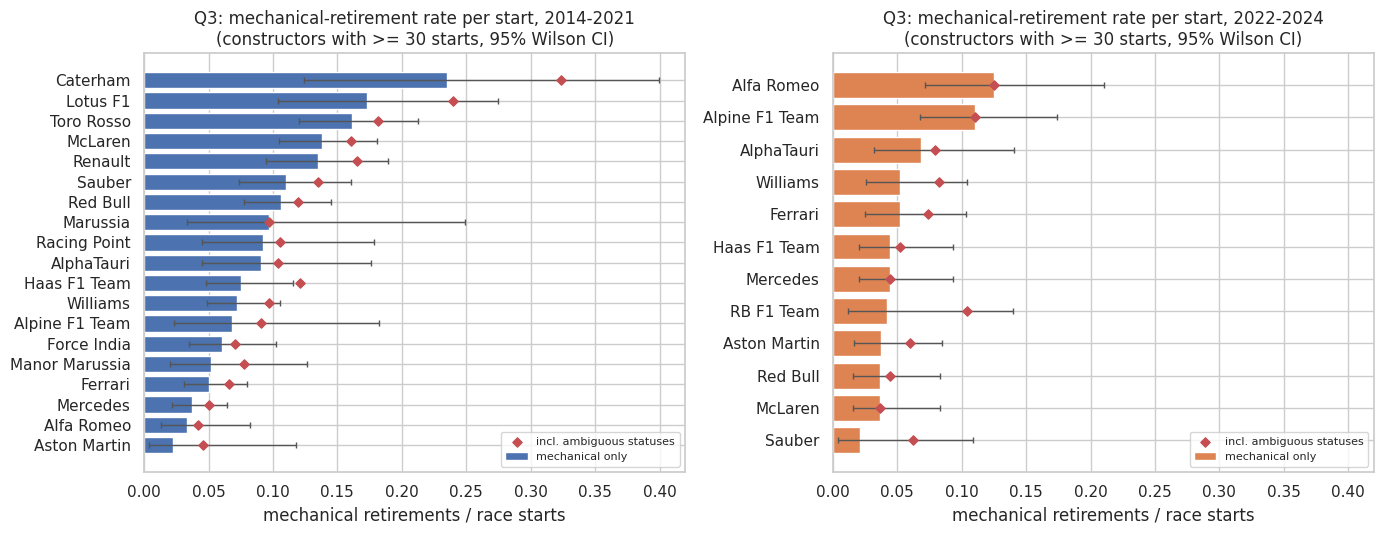

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)
for a, p, colr in [(ax[0], "2014-2021", "#4C72B0"), (ax[1], "2022-2024", "#DD8452")]:
    t = tc[tc.period == p].sort_values("mech_rate")
    a.barh(t.constructor, t.mech_rate, color=colr, xerr=[t.mech_rate - t.lo, t.hi - t.mech_rate], capsize=2,
           error_kw={"ecolor": "#555", "lw": 1}, label="mechanical only")
    a.scatter(t.mech_or_amb_rate, t.constructor, marker="D", color="#C44E52", s=22, label="incl. ambiguous statuses", zorder=3)
    a.set_title(f"Q3: mechanical-retirement rate per start, {p}\n(constructors with >= {MIN_STARTS} starts, 95% Wilson CI)")
    a.set_xlabel("mechanical retirements / race starts")
    a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Answer, Q3.**
- **Overall:** mechanical retirements fell from **9.1%** of starts in 2014–2021 to **5.6%** in 2022–2024 (11.3% → 7.0% including the ambiguous statuses).
- **2014–2021, highest rates:** **Caterham 23.5%** (34 starts), **Lotus F1 17.3%**, **Toro Rosso 16.1%**, **McLaren 13.8%** (the period includes its 2015–17 Honda power-unit years) and **Renault 13.5%**. The lowest are **Mercedes 3.8%**, Alfa Romeo 3.3% (2019–21 only under that name) and Aston Martin 2.3% (2021 only).
- **2022–2024, highest rates:** **Alfa Romeo 12.5%** and **Alpine 11.0%**, then AlphaTauri 6.8%. Every other team is between 2.1% and 5.2%, with **Sauber** (2024 only, 48 starts) lowest.
- **The ranking does not carry over:** for the 11 constructorIds ranked in both periods the Spearman correlation is **−0.50 (p = 0.12)**. McLaren went from 4th highest to among the most reliable, and Alfa Romeo and Alpine went the other way.
- **Sensitivity:** adding the ambiguous statuses keeps the top two in each period unchanged. RB moves from 8th to 3rd in 2022–24 because of non-specific "Retired" entries.
- **Caveats:** 2022–24 rates rest on 48–136 starts per team, so ±5 points is within noise. Results follow `constructorId`, which resets at renames.

## 13. Leakage-safe feature engineering

**Rule:** every feature for a driver in race *r* may use only (a) what is fixed before the lights go out in *r* (grid, qualifying, who is entered, the calendar) or (b) results of races that finished **before** *r*. Concretely:
- **History features** are computed on the time-ordered table (sorted by race date, then raceId) with `shift(1)` *before* any rolling or expanding window, so the current race never enters its own feature.
- **Championship standings** in `driver_standings` / `constructor_standings` are stored *after* each race. They are re-keyed to the **previous round of the same season**, so the feature is "standings going into this race". At round 1 nobody has points.
- The history pool is the modelling base itself (starts only, Indy 500 excluded), so a DNQ never counts as a "race" in someone's form.
- **Sprint races (`sprint_results`) are not used as features.** A sprint runs before the Sunday race, so it is technically pre-race information. However, it exists for only 18 races (2021–2024), all in validation and test, so a model trained up to 2019 could never learn from it. In 2021–22 the sprint result *set* the Sunday grid, so its effect already reaches the model through `grid_pct`. Sprint points enter the standings features from the next round onwards.

| Group | Feature | Definition |
|---|---|---|
| grid | `grid_clean`, `grid_is_zero` | starting slot (NaN + flag for pit-lane start), from Member 1 |
| grid | `field_size`, `grid_pct` | starters in this race; grid slot ranked within the race and scaled to 0 (pole) … 1 (last), so 20- and 30-car fields share one scale |
| qualifying | `quali_position`, `quali_gap_pct` | qualifying rank; driver's best Q1/Q2/Q3 lap vs the fastest lap of the session, in %, capped at 7 % (the 107 % rule) |
| qualifying | `grid_penalty` | `grid_clean − quali_position` (> 0 = sent back by a penalty) |
| driver form | `drv_starts_before`, `drv_podium_rate_last5`, `drv_finish_pct_last5`, `drv_dnf_rate_last10`, `drv_career_podium_rate` | past races only |
| constructor form | `con_podiums_per_race_last5`, `con_best_finish_pct_last5`, `con_dnf_rate_last10` | team-level, past races only |
| standings | `drv_points_share_before`, `drv_rank_before`, `drv_wins_before`, `con_points_share_before`, `con_rank_before` | standings after the previous round; points as a share of the leader's (points systems changed 10+ times) |
| context | `is_home`, `driver_age`, `season_progress` | home race (Q2 mapping), age on race day, `(round-1)/(rounds in season-1)` |

In [29]:
H = mb2.copy()
H["date"] = pd.to_datetime(H["date"])
H = H.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)

# outcome helpers (POST-RACE: used only through shift(1) below, never as features themselves)
H["field_size"]   = H.groupby("raceId")["driverId"].transform("size")
H["finish_rank"]  = H.groupby("raceId")["positionOrder_best"].rank(method="min")
H["finish_pct"]   = (H.finish_rank - 1) / (H.field_size - 1)          # 0 = winner, 1 = last
H["finished"]     = H["status"].map(lambda s: s == "Finished" or bool(re.fullmatch(r"\+\d+ Laps?", s))).astype(int)
H["dnf"]          = 1 - H["finished"]

def past(group_col, col, window=None, how="mean"):
    """value of `col` over the PREVIOUS `window` rows of the same group (current row excluded)."""
    g = H.groupby(group_col)[col]
    if window is None:   # expanding career value
        return g.transform(lambda s: s.shift(1).expanding().mean())
    return g.transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())

# ---- pre-race (known once the grid is fixed) ----
# grid slot numbers skip values in older races, so rank the slot within the race before scaling
grid_rank = H.groupby("raceId")["grid_clean"].rank(method="min")
n_grid = H.groupby("raceId")["grid_clean"].transform("count")
H["grid_pct"]      = (grid_rank - 1) / (n_grid - 1)                   # 0 = pole, 1 = last starter
best_q = H[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
# gap to the fastest lap of the session, capped at 7 %: the 107 % rule treats anything slower as off the pace
H["quali_gap_pct"] = (100 * (best_q / best_q.groupby(H.raceId).transform("min") - 1)).clip(upper=7)
H["grid_penalty"]  = H.grid_clean - H.quali_position
H["driver_age"]    = (H.date - pd.to_datetime(H.dob)).dt.days / 365.25
n_rounds = races_t.groupby("year")["round"].transform("max")
races_t["season_progress"] = (races_t["round"] - 1) / (n_rounds - 1).clip(lower=1)
H = H.merge(races_t[["raceId", "season_progress"]], on="raceId", how="left", validate="m:1")

# ---- driver form (past races only) ----
H["drv_starts_before"]      = H.groupby("driverId").cumcount()
H["drv_podium_rate_last5"]  = past("driverId", "podium", 5)
H["drv_finish_pct_last5"]   = past("driverId", "finish_pct", 5)
H["drv_dnf_rate_last10"]    = past("driverId", "dnf", 10)
H["drv_career_podium_rate"] = past("driverId", "podium", None)

# ---- constructor form (team-level per race, past races only) ----
CR = (H.groupby(["constructorId", "raceId"])
        .agg(date=("date", "first"), team_podiums=("podium", "sum"),
             team_best_finish_pct=("finish_pct", "min"), team_dnf=("dnf", "mean"))
        .reset_index().sort_values(["date", "raceId"]))
gc = CR.groupby("constructorId")
CR["con_podiums_per_race_last5"] = gc["team_podiums"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
CR["con_best_finish_pct_last5"]  = gc["team_best_finish_pct"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
CR["con_dnf_rate_last10"]        = gc["team_dnf"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
H = H.merge(CR[["constructorId", "raceId", "con_podiums_per_race_last5", "con_best_finish_pct_last5", "con_dnf_rate_last10"]],
            on=["constructorId", "raceId"], how="left", validate="m:1")

# ---- standings going INTO the race = standings after the previous round of the same season ----
rr = races_t.sort_values(["year", "round"]).copy()
rr["prev_raceId"] = rr.groupby("year")["raceId"].shift(1)
H = H.merge(rr[["raceId", "prev_raceId"]], on="raceId", how="left", validate="m:1")

ds = clean["driver_standings"][["raceId", "driverId", "points", "position", "wins"]].astype(
        {"raceId": int, "driverId": int, "points": float, "position": float, "wins": float})
ds["leader"] = ds.groupby("raceId")["points"].transform("max")
ds["n_in_standings"] = ds.groupby("raceId")["driverId"].transform("size")
ds = ds.rename(columns={"raceId": "prev_raceId", "points": "drv_points_before",
                        "position": "drv_rank_before", "wins": "drv_wins_before"})
H = H.merge(ds, on=["prev_raceId", "driverId"], how="left", validate="m:1")
# drivers absent from the previous standings (new this season / mid-season debut): 0 points, ranked last
lead_prev = ds.groupby("prev_raceId")[["leader", "n_in_standings"]].first()
miss = H.prev_raceId.notna() & H.drv_points_before.isna()
H.loc[miss, "drv_points_before"] = 0.0
H.loc[miss, "drv_wins_before"] = 0.0
H.loc[miss, "drv_rank_before"] = H.loc[miss, "prev_raceId"].map(lead_prev["n_in_standings"]) + 1
H["leader"] = H["prev_raceId"].map(lead_prev["leader"])
H["drv_points_share_before"] = np.where(H.leader > 0, H.drv_points_before / H.leader, 0.0)
opener = H.prev_raceId.isna()                      # round 1: nobody has points yet
H.loc[opener, ["drv_points_share_before", "drv_wins_before"]] = 0.0
H.loc[opener, "drv_rank_before"] = np.nan

cs = clean["constructor_standings"][["raceId", "constructorId", "points", "position"]].astype(
        {"raceId": int, "constructorId": int, "points": float, "position": float})
cs["c_leader"] = cs.groupby("raceId")["points"].transform("max")
cs["c_n"] = cs.groupby("raceId")["constructorId"].transform("size")
cs = cs.rename(columns={"raceId": "prev_raceId", "points": "con_points_before", "position": "con_rank_before"})
H = H.merge(cs, on=["prev_raceId", "constructorId"], how="left", validate="m:1")
has_cs = H.prev_raceId.isin(cs.prev_raceId)        # constructor standings exist only from 1958
cmiss = has_cs & H.con_points_before.isna()
H.loc[cmiss, "con_points_before"] = 0.0
H.loc[cmiss, "con_rank_before"] = H.loc[cmiss, "prev_raceId"].map(cs.groupby("prev_raceId")["c_n"].first()) + 1
H["c_leader"] = H["prev_raceId"].map(cs.groupby("prev_raceId")["c_leader"].first())
H["con_points_share_before"] = np.where(H.c_leader > 0, H.con_points_before / H.c_leader, np.nan)
H.loc[opener & (H.year >= 1958), "con_points_share_before"] = 0.0
H.loc[opener, "con_rank_before"] = np.nan

FEATURE_GROUPS = {
    "grid":             ["grid_clean", "grid_is_zero", "grid_pct", "field_size"],
    "qualifying":       ["quali_position", "quali_gap_pct", "grid_penalty"],
    "driver_form":      ["drv_starts_before", "drv_podium_rate_last5", "drv_finish_pct_last5",
                         "drv_dnf_rate_last10", "drv_career_podium_rate"],
    "constructor_form": ["con_podiums_per_race_last5", "con_best_finish_pct_last5", "con_dnf_rate_last10"],
    "standings":        ["drv_points_share_before", "drv_rank_before", "drv_wins_before",
                         "con_points_share_before", "con_rank_before"],
    "context":          ["is_home", "driver_age", "season_progress"],
}
CANDIDATES = [f for g in FEATURE_GROUPS.values() for f in g]
assert not H.duplicated(key).any() and len(H) == len(model_base)
print("Candidate features:", len(CANDIDATES))
display(H[CANDIDATES].describe().T[["count", "mean", "min", "50%", "max"]].round(3))

Candidate features: 23


,count,mean,min,50%,max
grid_clean,24652.0,11.782249,1.0,12.0,34.0
grid_is_zero,24724.0,0.002912,0.0,0.0,1.0
grid_pct,24652.0,0.499796,0.0,0.5,1.0
field_size,24724.0,22.60783,10.0,22.0,34.0
quali_position,10478.0,11.187249,1.0,11.0,26.0
quali_gap_pct,10322.0,2.238905,0.0,1.83992,7.0
grid_penalty,10407.0,-0.021236,-9.0,0.0,23.0
drv_starts_before,24724.0,68.197096,0.0,45.0,403.0
drv_podium_rate_last5,24035.0,0.138468,0.0,0.0,1.0
drv_finish_pct_last5,24035.0,0.495374,0.0,0.511174,1.0


### 13.1 Leakage test: recompute features from scratch using only earlier races

The vectorised code above is checked against a slow, obviously correct version. For 300 random rows, every history and standings feature is recomputed **from a table filtered to races strictly before that row's date** (the current race and anything later are physically removed). Any mismatch means a feature saw the current or a future race.

In [30]:
rng = np.random.default_rng(M2_SEED)
sample = H.iloc[rng.choice(len(H), 300, replace=False)]
ds_raw = clean["driver_standings"].astype({"raceId": int, "driverId": int})
mism = []
for _, row in sample.iterrows():
    hist = H[H.date < row.date]                       # strictly earlier races only
    d = hist[hist.driverId == row.driverId]
    exp = {
        "drv_starts_before": len(d),
        "drv_podium_rate_last5": d.podium.tail(5).mean() if len(d) else np.nan,
        "drv_dnf_rate_last10": d.dnf.tail(10).mean() if len(d) else np.nan,
        "drv_career_podium_rate": d.podium.mean() if len(d) else np.nan,
    }
    t = hist[hist.constructorId == row.constructorId].groupby("raceId", sort=False).agg(p=("podium", "sum"), dt=("date", "first"))
    exp["con_podiums_per_race_last5"] = t.sort_values("dt").p.tail(5).mean() if len(t) else np.nan
    # standings: latest earlier race in the SAME season
    same = rr[(rr.year == row.year) & (rr["round"] < row["round"])]
    if len(same):
        prev = same.sort_values("round").raceId.iloc[-1]
        sd = ds_raw[(ds_raw.raceId == prev)]
        me = sd[sd.driverId == row.driverId]
        exp["drv_wins_before"] = float(me.wins.iloc[0]) if len(me) else 0.0
    else:
        exp["drv_wins_before"] = 0.0
    for k, v in exp.items():
        got = row[k]
        if not ((pd.isna(v) and pd.isna(got)) or np.isclose(float(v), float(got))):
            mism.append((row.raceId, row.driverId, k, v, got))
print("rows checked:", len(sample), "| features checked per row:", len(exp), "| mismatches:", len(mism))
assert not mism, mism[:5]

# a second, independent check: no feature may change if the CURRENT race's outcome is scrambled
H_scr = H.copy()
rid = sample.raceId.iloc[0]
H_scr.loc[H_scr.raceId == rid, "podium"] = 1 - H_scr.loc[H_scr.raceId == rid, "podium"]
recomputed = H_scr.groupby("driverId")["podium"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
same_race = H_scr.raceId == rid
print("feature values in the scrambled race unchanged:",
      bool(np.allclose(recomputed[same_race].fillna(-1), H.loc[same_race, "drv_podium_rate_last5"].fillna(-1))))

rows checked: 300 | features checked per row: 6 | mismatches: 0
feature values in the scrambled race unchanged: True


## 14. Train / validation / test split

**Split by season, not at random:** train = 1950–2019, validation = 2020–2021, test = 2022–2024 (the boundaries agreed in the project glossary).

Why a time-based split:
- **It matches how the model would be used:** we always predict a future race from past ones. A random split puts 2023 races in training and 2010 races in test, so the model could learn team strength from the future.
- **The form features need it:** a driver's `drv_podium_rate_last5` in a 2019 race and the target of his 2018 race are the same numbers. With a random split, those neighbouring races would sit on both sides of the split.
- **Whole races stay together:** the three podium slots in a race depend on each other. Splitting by season never splits a race.
- **The test set is a regulation change:** 2022 starts the ground-effect era, so the test score shows how well the model survives a rule reset, an honest and difficult check.

The *start* of the training window is chosen empirically in §16.2.

,seasons,races,rows,podiums,podium_rate
split,,,,,
train,1950-2019,1007,22589,3038,0.1345
val,2020-2021,39,779,117,0.1502
test,2022-2024,68,1356,204,0.1504


val: rows whose constructorId never appears in train: 121 (16%) -> ['AlphaTauri', 'Alpine F1 Team']
test: rows whose constructorId never appears in train: 272 (20%) -> ['AlphaTauri', 'Alpine F1 Team', 'RB F1 Team']


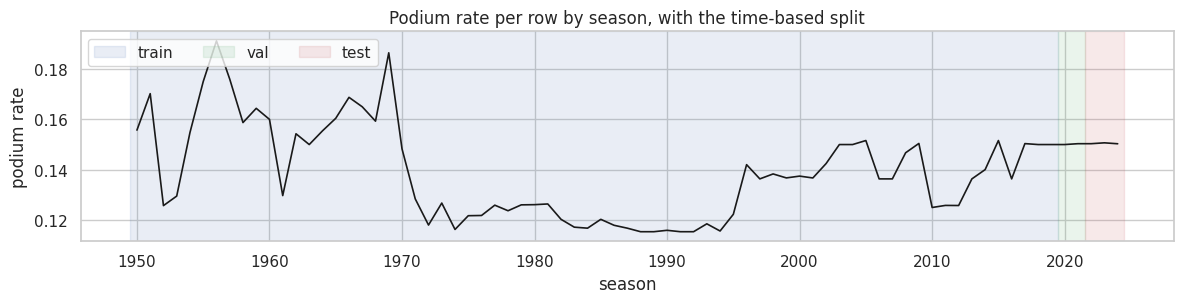

In [31]:
H["split"] = np.select([H.year <= 2019, H.year <= 2021], ["train", "val"], "test")
split_tbl = H.groupby("split").agg(seasons=("year", lambda s: f"{s.min()}-{s.max()}"), races=("raceId", "nunique"),
                                   rows=("podium", "size"), podiums=("podium", "sum"), podium_rate=("podium", "mean"))
display(split_tbl.loc[["train", "val", "test"]].round(4))

# no race is split, and the splits are strictly ordered in time
assert H.groupby("raceId")["split"].nunique().max() == 1
assert H[H.split == "train"].date.max() < H[H.split == "val"].date.min() <= H[H.split == "val"].date.max() < H[H.split == "test"].date.min()

train_teams = set(H.loc[H.split == "train", "constructorId"])
for sp in ["val", "test"]:
    unseen = H.loc[(H.split == sp) & ~H.constructorId.isin(train_teams)]
    print(f"{sp}: rows whose constructorId never appears in train: {len(unseen)} ({len(unseen)/(H.split == sp).sum():.0%})",
          "->", sorted(unseen.constructorId.map(constr_t.set_index("constructorId")["constructor"]).unique()))

fig, ax = plt.subplots(figsize=(12, 3.2))
yr = H.groupby("year").podium.mean()
colors = {"train": "#4C72B0", "val": "#55A868", "test": "#C44E52"}
for sp, (a, b) in {"train": (1950, 2019), "val": (2020, 2021), "test": (2022, 2024)}.items():
    ax.axvspan(a - 0.5, b + 0.5, color=colors[sp], alpha=0.12, label=sp)
ax.plot(yr.index, yr.values, color="k", lw=1.2)
ax.set_title("Podium rate per row by season, with the time-based split"); ax.set_ylabel("podium rate"); ax.set_xlabel("season")
ax.legend(loc="upper left", ncol=3); plt.tight_layout(); plt.show()

## 15. Feature evidence (training rows only)

All evidence below is computed on **train rows (≤ 2019)** so that the choice of features is not tuned to validation or test.
- **Univariate ROC-AUC:** how well each feature alone ranks podium rows above non-podium rows (0.5 = useless). It is direction-free (we report max(AUC, 1−AUC) and the sign), and it is computed on the rows where the feature exists, with coverage reported next to it.
- **Added value beyond grid:** grid is by far the strongest single signal, so a feature only earns its place if it adds information *on top of* grid. For each feature, a logistic regression on `grid_pct` + that feature is trained on 2003–2019 and scored on validation (PR-AUC), compared with `grid_pct` alone.
- **Redundancy:** Spearman correlation between features. A near-duplicate (|ρ| > 0.9) of a stronger feature is dropped.

In [32]:
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

tr = H[H.split == "train"]
ev = []
for f in CANDIDATES:
    m = tr[f].notna()
    auc = roc_auc_score(tr.loc[m, "podium"], tr.loc[m, f]) if tr.loc[m, f].nunique() > 1 else 0.5
    ev.append({"feature": f, "group": next(g for g, fs in FEATURE_GROUPS.items() if f in fs),
               "coverage_train": m.mean(), "coverage_2003_2019": tr.loc[tr.year >= 2003, f].notna().mean(),
               "AUC": max(auc, 1 - auc), "direction": "+" if auc >= 0.5 else "-",
               "spearman_with_target": stats.spearmanr(tr.loc[m, f], tr.loc[m, "podium"])[0]})
ev = pd.DataFrame(ev)

# added value beyond grid: LR(grid_pct + f) vs LR(grid_pct), trained 2003-2019, scored on validation
tr03, va = H[(H.split == "train") & (H.year >= 2003)], H[H.split == "val"]
def lr_pr_auc(cols):
    pipe = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(max_iter=2000))
    pipe.fit(tr03[cols], tr03.podium)
    return average_precision_score(va.podium, pipe.predict_proba(va[cols])[:, 1])
base_pr = lr_pr_auc(["grid_pct"])
ev["val_PR_AUC_grid_plus_f"] = [lr_pr_auc(["grid_pct"] if f == "grid_pct" else ["grid_pct", f]) for f in ev.feature]
ev["gain_over_grid"] = ev.val_PR_AUC_grid_plus_f - base_pr
print(f"Validation PR-AUC of grid_pct alone: {base_pr:.3f}  (podium base rate {va.podium.mean():.3f})")
display(ev.sort_values("AUC", ascending=False).round(3).reset_index(drop=True))

Validation PR-AUC of grid_pct alone: 0.645  (podium base rate 0.150)


,feature,group,coverage_train,coverage_2003_2019,AUC,direction,spearman_with_target,val_PR_AUC_grid_plus_f,gain_over_grid
0,quali_position,qualifying,0.369,0.997,0.906,-,-0.487,0.668,0.023
1,quali_gap_pct,qualifying,0.363,0.982,0.887,-,-0.466,0.661,0.016
2,grid_clean,grid,0.999,0.997,0.884,-,-0.454,0.645,0.000
3,grid_pct,grid,0.999,0.997,0.880,-,-0.450,0.645,0.000
4,drv_rank_before,standings,0.933,0.948,0.836,-,-0.397,0.701,0.056
5,con_rank_before,standings,0.888,0.948,0.830,-,-0.390,0.686,0.041
6,con_podiums_per_race_last5,constructor_form,0.988,0.995,0.821,+,0.414,0.668,0.023
7,con_best_finish_pct_last5,constructor_form,0.988,0.995,0.818,-,-0.377,0.658,0.013
8,drv_podium_rate_last5,driver_form,0.970,0.989,0.812,+,0.445,0.705,0.061
9,drv_career_podium_rate,driver_form,0.970,0.989,0.808,+,0.377,0.737,0.092


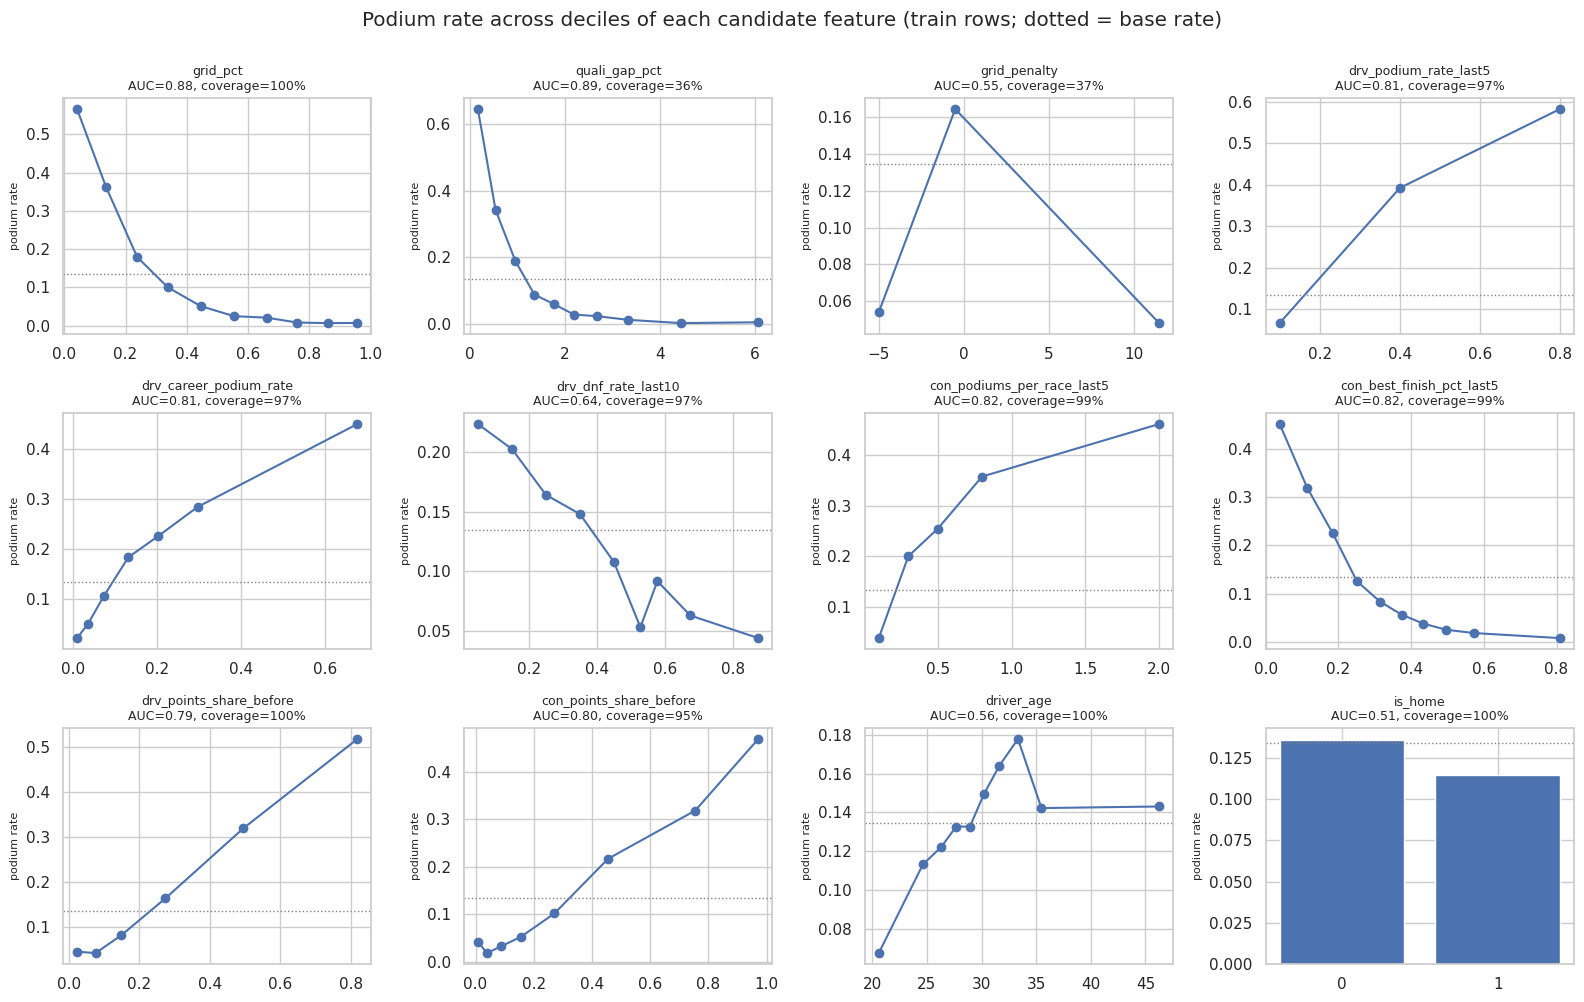

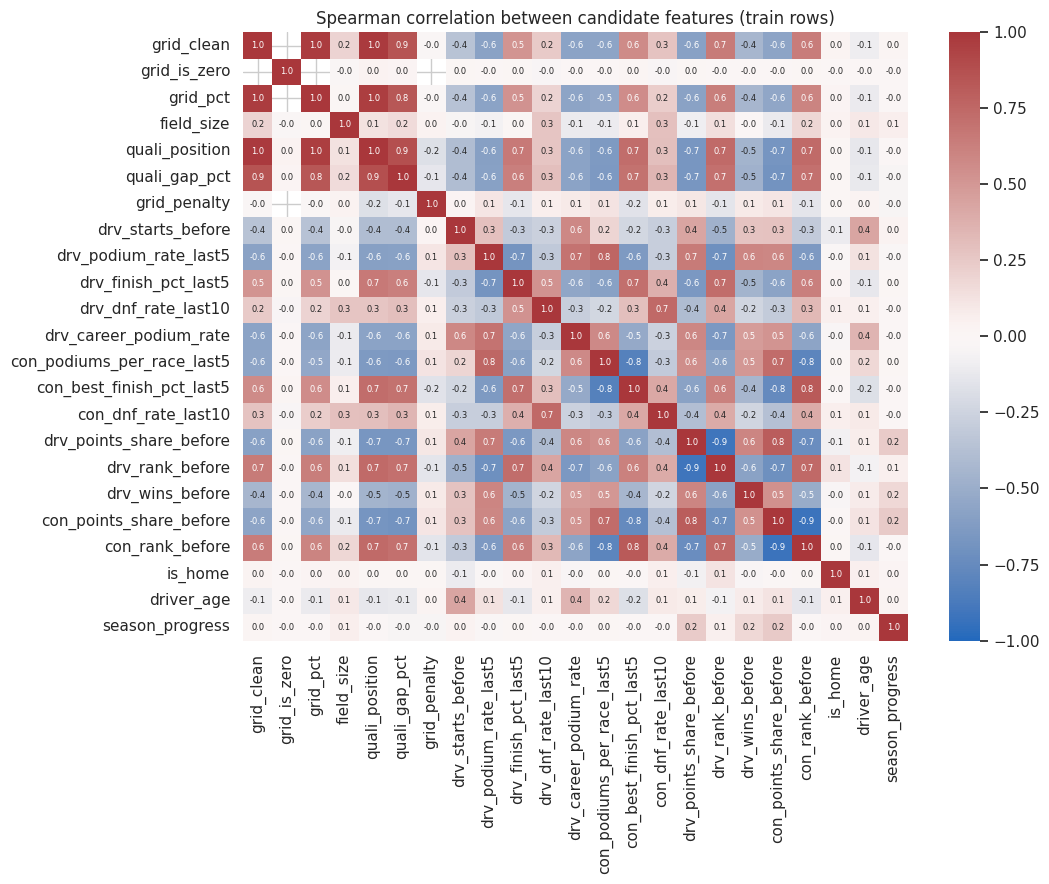

Pairs with |rho| > 0.9: [('grid_clean', 'grid_pct', np.float64(0.97)), ('grid_clean', 'quali_position', np.float64(0.98)), ('grid_pct', 'quali_position', np.float64(0.96)), ('drv_points_share_before', 'drv_rank_before', np.float64(-0.91)), ('con_points_share_before', 'con_rank_before', np.float64(-0.92))]


In [33]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
show_feats = ["grid_pct", "quali_gap_pct", "grid_penalty", "drv_podium_rate_last5", "drv_career_podium_rate",
              "drv_dnf_rate_last10", "con_podiums_per_race_last5", "con_best_finish_pct_last5",
              "drv_points_share_before", "con_points_share_before", "driver_age", "is_home"]
for a, f in zip(axes.ravel(), show_feats):
    d = tr[[f, "podium"]].dropna()
    if d[f].nunique() <= 4:
        b = d.groupby(f)["podium"].agg(["mean", "size"])
        a.bar(b.index.astype(str), b["mean"], color="#4C72B0")
    else:
        q = pd.qcut(d[f], 10, duplicates="drop")
        b = d.groupby(q, observed=True)["podium"].agg(["mean", "size"])
        mids = [iv.mid for iv in b.index]
        a.plot(mids, b["mean"], marker="o")
    a.set_title(f"{f}\nAUC={ev.set_index('feature').loc[f, 'AUC']:.2f}, coverage={d.shape[0]/len(tr):.0%}", fontsize=9)
    a.set_ylabel("podium rate", fontsize=8); a.axhline(tr.podium.mean(), color="grey", ls=":", lw=1)
fig.suptitle("Podium rate across deciles of each candidate feature (train rows; dotted = base rate)", y=1.0)
plt.tight_layout(); plt.show()

corr = tr[CANDIDATES].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 6})
plt.title("Spearman correlation between candidate features (train rows)")
plt.tight_layout(); plt.show()

high = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(CANDIDATES) for b in CANDIDATES[i + 1:] if abs(corr.loc[a, b]) > 0.9]
print("Pairs with |rho| > 0.9:", high)

**What the evidence shows (train rows):**
- **Starting position dominates:** `quali_position`, `quali_gap_pct`, `grid_clean` and `grid_pct` all have AUC 0.88–0.91, and the podium rate falls from ~57% in the front grid decile to < 2% beyond the midfield.
- **Grid and qualifying position are near-duplicates** (ρ = 0.96–0.98). Qualifying *pace* (`quali_gap_pct`) and the *penalty* (`grid_penalty`) still add information beyond grid, so those two are kept instead of the raw rank.
- **Form and standings:** the podium, finish and standings features reach AUC 0.79–0.84; the reliability (`*_dnf_rate_*`), experience and wins features 0.64–0.70.
- **Gain beyond grid:** driver form and standings add the most, +0.02 to +0.09 validation PR-AUC (largest: `drv_career_podium_rate`, +0.09). Constructor form adds less (+0.01 to +0.02), because grid already reflects car pace. Across their deciles the podium rate rises steadily, with no sign of a leak-like jump to 100%.
- **Points share and rank** carry the same information (|ρ| > 0.9), so only one of each pair is kept.
- **Weak candidates:** `is_home` (AUC 0.51, consistent with Q2), `field_size` (0.54) and `grid_is_zero` add nothing beyond grid. The pit-lane case is still covered by the missing-indicator for `grid_pct`.
- **`driver_age`** has a weak univariate signal (0.56) but a +0.055 gain on validation, plausibly because experienced drivers sit in the top cars. It passes the rule, but this is the least certain feature.

### 15.1 Selection rule, applied to the evidence above

1. `grid_pct` is the **anchor**: it is the strongest valid signal, and all "gain" numbers are measured on top of it.
2. Keep a candidate if **univariate AUC ≥ 0.60** *or* it **adds ≥ 0.01 validation PR-AUC on top of grid**.
3. For each near-duplicate pair (|ρ| > 0.9), keep the member with the larger gain over grid. The anchor always stays.

Caveat: the validation set is small (39 races, 117 podiums), so a gain of about ±0.01 is within noise. The rule therefore only removes features that fail **both** tests; the feature-group ablation (Member 3/4) measures each group's contribution after training.

In [34]:
anchor = "grid_pct"
e = ev.set_index("feature")
keep = [f for f in CANDIDATES if f == anchor or e.loc[f, "AUC"] >= 0.60 or e.loc[f, "gain_over_grid"] >= 0.01]
dropped_weak = [f for f in CANDIDATES if f not in keep]
dropped_dup = []
for a, b, r in high:
    if a in keep and b in keep:
        loser = b if a == anchor else a if b == anchor else (a if e.loc[a, "gain_over_grid"] < e.loc[b, "gain_over_grid"] else b)
        keep.remove(loser); dropped_dup.append((loser, f"near-duplicate of {b if loser == a else a} (rho={r})"))
FEATURES = keep
print("Dropped as weak (AUC < 0.60 and gain < 0.01):", dropped_weak)
print("Dropped as redundant:", dropped_dup)
print(f"\nSELECTED FEATURES ({len(FEATURES)}):")
SEL_GROUPS = {g: [f for f in fs if f in FEATURES] for g, fs in FEATURE_GROUPS.items()}
for g, fs in SEL_GROUPS.items():
    print(f"  {g:17s} {fs}")

Dropped as weak (AUC < 0.60 and gain < 0.01): ['grid_is_zero', 'field_size', 'is_home']
Dropped as redundant: [('grid_clean', 'near-duplicate of grid_pct (rho=0.97)'), ('quali_position', 'near-duplicate of grid_pct (rho=0.96)'), ('drv_rank_before', 'near-duplicate of drv_points_share_before (rho=-0.91)'), ('con_points_share_before', 'near-duplicate of con_rank_before (rho=-0.92)')]

SELECTED FEATURES (16):
  grid              ['grid_pct']
  qualifying        ['quali_gap_pct', 'grid_penalty']
  driver_form       ['drv_starts_before', 'drv_podium_rate_last5', 'drv_finish_pct_last5', 'drv_dnf_rate_last10', 'drv_career_podium_rate']
  constructor_form  ['con_podiums_per_race_last5', 'con_best_finish_pct_last5', 'con_dnf_rate_last10']
  standings         ['drv_points_share_before', 'drv_wins_before', 'con_rank_before']
  context           ['driver_age', 'season_progress']


## 16. Encoding and preprocessing

**Encoding**
- Every selected feature is **numeric or binary**, so no one-hot encoding is needed.
- **Identity columns are not used as features:** `constructorId`, `driverId`, `circuitId`, `number` and `nationality` are left out. One-hot `constructorId` would teach the model "Mercedes = strong", which is wrong outside 2014–2020. §14 also shows 16–20% of validation/test rows belong to constructorIds that never appear in training (AlphaTauri, Alpine, RB). Team and driver strength enter through the **form and standings features**, which follow whoever is fast *now*.
- **No target encoding:** encoding a category by its mean podium rate would be a leak unless rebuilt out-of-fold and in time order. It is unnecessary once form features exist.

**Missing values** are informative, not random. `quali_*` is missing before 2003 because the data has no qualifying. `drv_*` is missing on a driver's debut, `con_rank_before` before 1958 and at season openers, and `grid` for pit-lane starts. So the pipeline uses **median imputation plus a missing-indicator column** for each feature with gaps, letting the model learn "no qualifying record" or "debut" separately.

**Scaling:** `StandardScaler` puts every feature on mean 0 / sd 1, which logistic regression and the neural network need. Tree models are unaffected.

**Order:** impute → scale. Both are **fit on training rows only**, inside an sklearn `Pipeline`, so validation and test never influence the medians, means or standard deviations. §16.3 tests these choices.

,count,mean,std,min,max,count_after,mean_after,std_after,min_after,max_after
grid_pct,22570.0,0.499779,0.301866,0.0,1.0,22589.0,0.0,1.0,-1.66,1.66
quali_gap_pct,8209.0,2.356133,1.835137,0.0,7.0,22589.0,-0.0,1.0,-1.88,4.36
grid_penalty,8326.0,-0.009849,1.370526,-9.0,23.0,22589.0,-0.0,1.0,-10.81,27.65
drv_starts_before,22589.0,61.689451,61.909199,0.0,324.0,22589.0,-0.0,1.0,-1.00,4.24
drv_podium_rate_last5,21914.0,0.13723,0.234752,0.0,1.0,22589.0,-0.0,1.0,-0.57,3.73
drv_finish_pct_last5,21914.0,0.49515,0.193418,0.0,1.0,22589.0,0.0,1.0,-2.60,2.65
drv_dnf_rate_last10,21914.0,0.420378,0.249718,0.0,1.0,22589.0,0.0,1.0,-1.71,2.36
drv_career_podium_rate,21914.0,0.121983,0.157791,0.0,1.0,22589.0,0.0,1.0,-0.77,5.65
con_podiums_per_race_last5,22329.0,0.317882,0.472119,0.0,3.0,22589.0,-0.0,1.0,-0.67,5.71
con_best_finish_pct_last5,22329.0,0.347971,0.200762,0.0,1.0,22589.0,-0.0,1.0,-1.74,3.27


Missing-indicator columns added: ['missingindicator_grid_pct', 'missingindicator_quali_gap_pct', 'missingindicator_grid_penalty', 'missingindicator_drv_podium_rate_last5', 'missingindicator_drv_finish_pct_last5', 'missingindicator_drv_dnf_rate_last10', 'missingindicator_drv_career_podium_rate', 'missingindicator_con_podiums_per_race_last5', 'missingindicator_con_best_finish_pct_last5', 'missingindicator_con_dnf_rate_last10', 'missingindicator_con_rank_before']


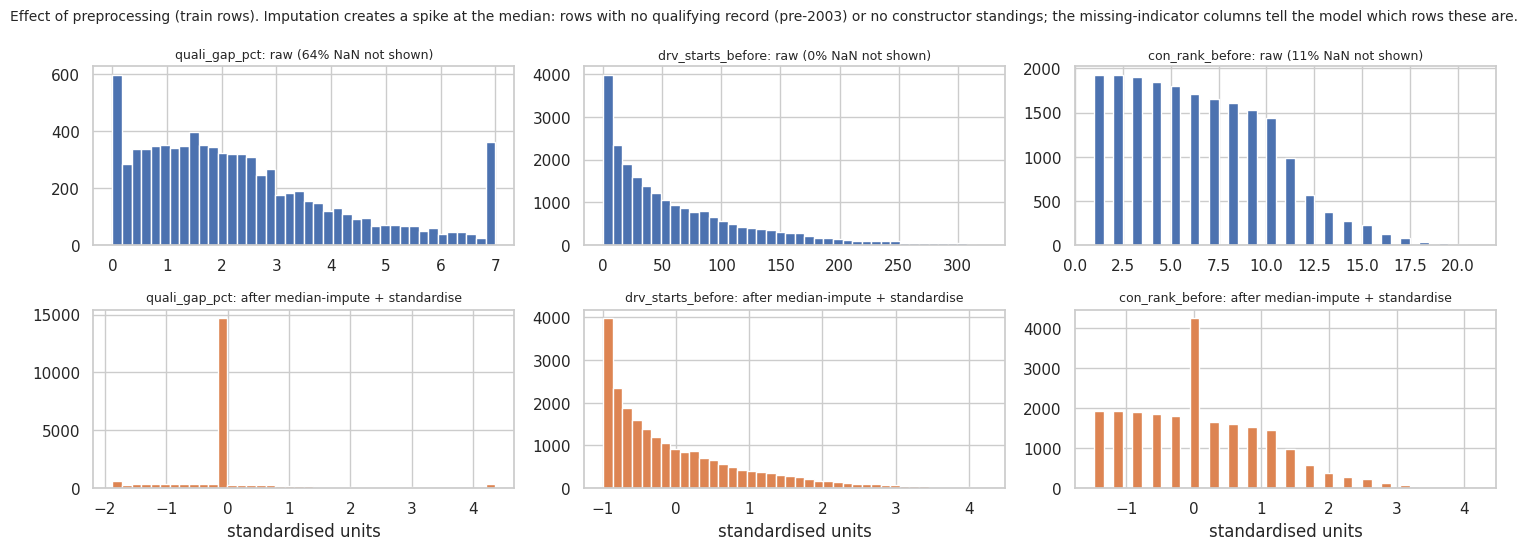

In [35]:
def make_preprocessor(features, add_indicator=True, scale=True):
    """impute (median, + missing flags) -> scale. Fit it on TRAIN rows only (inside a Pipeline)."""
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=add_indicator))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return ColumnTransformer([("num", Pipeline(steps), features)], remainder="drop", verbose_feature_names_out=False)

def evaluate(pipe, Xtr, ytr, Xev, yev):
    """ROC-AUC, PR-AUC and F1. The F1 threshold is chosen on TRAIN predictions (never on the scored set)."""
    pipe.fit(Xtr, ytr)
    p_tr, p_ev = pipe.predict_proba(Xtr)[:, 1], pipe.predict_proba(Xev)[:, 1]
    pr, rc, th = precision_recall_curve(ytr, p_tr)
    f1s = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    thr = th[np.argmax(f1s[:-1])]
    return {"ROC_AUC": roc_auc_score(yev, p_ev), "PR_AUC": average_precision_score(yev, p_ev),
            "F1": f1_score(yev, (p_ev >= thr).astype(int)), "threshold": thr}

def lr_pipe(features, **kw):
    return Pipeline([("prep", make_preprocessor(features, **kw)),
                     ("clf", LogisticRegression(max_iter=3000))])

# effect of preprocessing on the data (fit on train, applied to train)
prep = make_preprocessor(FEATURES).fit(H[H.split == "train"][FEATURES])
Xt = pd.DataFrame(prep.transform(H[H.split == "train"][FEATURES]), columns=prep.get_feature_names_out())
before = H[H.split == "train"][FEATURES].describe().T[["count", "mean", "std", "min", "max"]]
after = Xt[FEATURES].describe().T[["count", "mean", "std", "min", "max"]]
display(before.join(after, rsuffix="_after").round(2))
print("Missing-indicator columns added:", [c for c in Xt.columns if c.startswith("missingindicator")])

trX = H[H.split == "train"]
fig, ax = plt.subplots(2, 3, figsize=(15, 5.6))
for j, f in enumerate(["quali_gap_pct", "drv_starts_before", "con_rank_before"]):
    raw_v = trX[f]
    ax[0, j].hist(raw_v.dropna(), bins=40, color="#4C72B0")
    ax[0, j].set_title(f"{f}: raw ({raw_v.isna().mean():.0%} NaN not shown)", fontsize=9)
    ax[1, j].hist(Xt[f], bins=40, color="#DD8452")
    ax[1, j].set_title(f"{f}: after median-impute + standardise", fontsize=9)
    ax[1, j].set_xlabel("standardised units")
fig.suptitle("Effect of preprocessing (train rows). Imputation creates a spike at the median: rows with no qualifying record "
             "(pre-2003) or no constructor standings; the missing-indicator columns tell the model which rows these are.", fontsize=10)
plt.tight_layout(); plt.show()

### 16.2 Training window (empirical)

Older seasons add rows, but they come from a different sport: no qualifying data, 30-car fields and low reliability. The baseline logistic regression is trained on train rows from different start years and scored on **validation** (test is not touched).

,train_from,train_rows,ROC_AUC,PR_AUC,F1,threshold
0,1950,22589,0.9329,0.7353,0.6885,0.2882
1,1970,19204,0.9335,0.7383,0.6829,0.2708
2,1981,15415,0.9336,0.7384,0.6942,0.3139
3,1994,10165,0.9336,0.7377,0.6914,0.2969
4,2003,6821,0.9344,0.7426,0.6975,0.3241
5,2010,4288,0.9327,0.7353,0.6805,0.3050
6,2014,2484,0.9293,0.7293,0.6751,0.3375


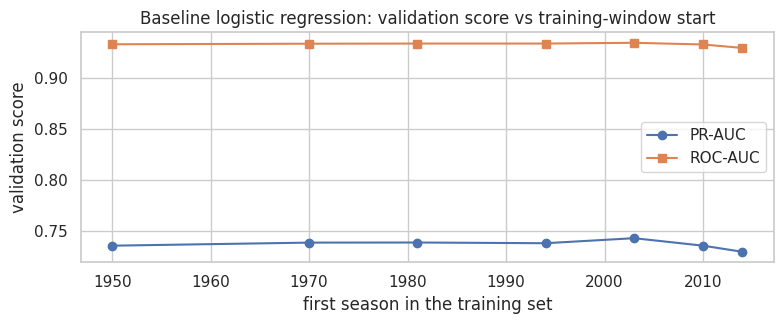

In [36]:
va = H[H.split == "val"]
win = []
for start in [1950, 1970, 1981, 1994, 2003, 2010, 2014]:
    t = H[(H.split == "train") & (H.year >= start)]
    r = evaluate(lr_pipe(FEATURES), t[FEATURES], t.podium, va[FEATURES], va.podium)
    win.append({"train_from": start, "train_rows": len(t), **r})
win = pd.DataFrame(win)
display(win.round(4))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(win.train_from, win.PR_AUC, marker="o", label="PR-AUC")
ax.plot(win.train_from, win.ROC_AUC, marker="s", label="ROC-AUC")
ax.set_xlabel("first season in the training set"); ax.set_ylabel("validation score")
ax.set_title("Baseline logistic regression: validation score vs training-window start"); ax.legend()
plt.tight_layout(); plt.show()

**Result:** all start years from 1950 to 2010 score within 0.01 PR-AUC of each other. **2003** is best (PR-AUC 0.743, ROC-AUC 0.934), and training only on 2014+ is worst (too few rows). This agrees with the hypothesis from Member 1's EDA: from 2003 onwards qualifying data is complete, so the model trains on rows that look like the 2020–24 rows it predicts. **Training window: 2003–2019** (6,821 rows). Because the differences are small, the full 1950–2019 table remains a valid alternative for the ablation.

### 16.3 Preprocessing-order experiments

Same model (baseline logistic regression), same features and rows (training window from 16.2), and one change per experiment. All scores are on validation:
- **E1, order:** impute → scale (ours) vs scale → impute.
- **E2, where the preprocessing is fit:** on train only (ours) vs on train + validation + test (a leak: test medians and means seep into training).
- **E3, missing indicators:** median imputation with vs without indicator columns.

Training window chosen on validation PR-AUC: train_from = 2003 | rows: 6821


,ROC_AUC,PR_AUC,F1,threshold
E1a impute -> scale (ours),0.9344,0.7426,0.6975,0.3241
E1b scale -> impute,0.9330,0.7401,0.6975,0.3419
E2a fit on train only (ours),0.9344,0.7426,0.6975,0.3241
E2b fit on train+val+test (leaky),0.9344,0.7426,0.6917,0.3095
E3a median + missing indicators (ours),0.9344,0.7426,0.6975,0.3241
"E3b median, no indicators",0.9299,0.7326,0.6857,0.2862


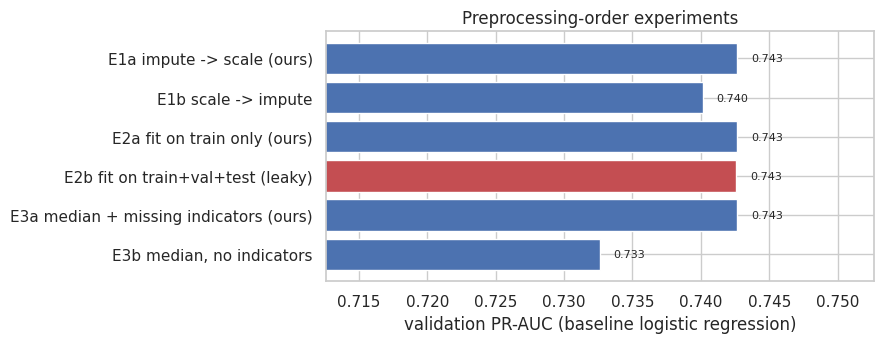

In [37]:
TRAIN_FROM = int(win.loc[win.PR_AUC.idxmax(), "train_from"])
trw = H[(H.split == "train") & (H.year >= TRAIN_FROM)]
Xtr, ytr, Xva, yva = trw[FEATURES], trw.podium, va[FEATURES], va.podium
print("Training window chosen on validation PR-AUC: train_from =", TRAIN_FROM, "| rows:", len(trw))

exp = {}
exp["E1a impute -> scale (ours)"] = evaluate(lr_pipe(FEATURES), Xtr, ytr, Xva, yva)
scale_first = Pipeline([("prep", ColumnTransformer([("num", Pipeline([
                    ("scale", StandardScaler()), ("impute", SimpleImputer(strategy="median", add_indicator=True))]), FEATURES)])),
                    ("clf", LogisticRegression(max_iter=3000))])
exp["E1b scale -> impute"] = evaluate(scale_first, Xtr, ytr, Xva, yva)

# E2: preprocessing fit on ALL rows (leaky) -> then the classifier is trained on train rows only
leaky_prep = make_preprocessor(FEATURES).fit(H[H.year >= TRAIN_FROM][FEATURES])
clf = LogisticRegression(max_iter=3000).fit(leaky_prep.transform(Xtr), ytr)
p = clf.predict_proba(leaky_prep.transform(Xva))[:, 1]
p_tr = clf.predict_proba(leaky_prep.transform(Xtr))[:, 1]
pr, rc, th = precision_recall_curve(ytr, p_tr); thr = th[np.argmax((2 * pr * rc / np.maximum(pr + rc, 1e-12))[:-1])]
exp["E2a fit on train only (ours)"] = exp["E1a impute -> scale (ours)"]
exp["E2b fit on train+val+test (leaky)"] = {"ROC_AUC": roc_auc_score(yva, p), "PR_AUC": average_precision_score(yva, p),
                                             "F1": f1_score(yva, (p >= thr).astype(int)), "threshold": thr}
exp["E3a median + missing indicators (ours)"] = exp["E1a impute -> scale (ours)"]
exp["E3b median, no indicators"] = evaluate(lr_pipe(FEATURES, add_indicator=False), Xtr, ytr, Xva, yva)
exp = pd.DataFrame(exp).T
display(exp.round(4))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(exp.index[::-1], exp.PR_AUC[::-1], color=["#C44E52" if "leaky" in i else "#4C72B0" for i in exp.index[::-1]])
ax.set_xlim(exp.PR_AUC.min() - 0.02, exp.PR_AUC.max() + 0.01)
for i, v in enumerate(exp.PR_AUC[::-1]): ax.text(v + 0.001, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("validation PR-AUC (baseline logistic regression)"); ax.set_title("Preprocessing-order experiments")
plt.tight_layout(); plt.show()

**Results:**
- **E1, order:** impute → scale is slightly better than scale → impute (0.743 vs 0.740 PR-AUC). The two differ only in where the imputed value sits relative to the scaled distribution, so the gap is small. We keep impute → scale because the median is then computed on raw units, where it has a meaning.
- **E2, leaky fit:** fitting the imputer and scaler on all rows changes nothing measurable here (PR-AUC identical, F1 0.692 vs 0.698). Logistic regression is unaffected by an affine rescaling, and training medians barely move when 2020–24 rows are added. **It is still a leak and is not used:** the result shows this particular leak is small for this model, not that it is safe. A model sensitive to feature ranges, such as the neural network, or a stronger shift in later data could be affected.
- **E3, missing indicators:** the clearest effect. Removing the indicators costs **0.010 PR-AUC** (0.743 → 0.733) and 0.012 F1. Missingness here is structural (debut, no constructor standings, pit-lane start), so the model benefits from knowing a value was imputed.

## 17. Hand-off: the leakage-safe modelling table

`modeling_table` (and `modeling_table.csv`) holds one row per `(raceId, driverId)`: keys, `year`, `split`, the target `podium`, and all candidate features. For modelling, Member 3/4 use:
- `FEATURES`: the selected list; `SEL_GROUPS`: the same features by group, for the ablation
- `TRAIN_FROM`: the first training season; `make_preprocessor(FEATURES)` inside a `Pipeline`, fit on training rows only
- `evaluate(...)`: ROC-AUC, PR-AUC and F1, with the threshold set on training predictions

The final asserts guard the grain, the target and the absence of every post-race column.

In [38]:
ID_COLS = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "split"]
modeling_table = H[ID_COLS + ["podium"] + CANDIDATES].copy()

POST_RACE = {c for c, r in ROLE.items() if "POST-RACE" in r} | {"finish_rank", "finish_pct", "finished", "dnf",
             "status", "status_group", "laps", "points", "leader", "c_leader", "drv_points_before", "con_points_before"}
assert POST_RACE.isdisjoint(modeling_table.columns), POST_RACE & set(modeling_table.columns)
assert not modeling_table.duplicated(key).any()
assert len(modeling_table) == len(model_base) == 24724
assert modeling_table.podium.isin([0, 1]).all()
assert set(FEATURES) <= set(CANDIDATES)

modeling_table.to_csv(f"{OUT}/modeling_table.csv", index=False)
json.dump({"FEATURES": FEATURES, "SEL_GROUPS": SEL_GROUPS, "FEATURE_GROUPS": FEATURE_GROUPS, "TRAIN_FROM": TRAIN_FROM,
           "split": {"train": "<=2019", "val": "2020-2021", "test": ">=2022"}},
          open(f"{OUT}/feature_spec.json", "w"), indent=2)
print("modeling_table:", modeling_table.shape)
display(modeling_table.groupby("split").agg(rows=("podium", "size"), podium_rate=("podium", "mean"))
        .join(modeling_table[modeling_table.year >= TRAIN_FROM].groupby("split").size().rename(f"rows_from_{TRAIN_FROM}")))
print("Exported:", sorted(f for f in os.listdir(OUT) if f.endswith((".csv", ".json"))))

modeling_table: (24724, 32)


,rows,podium_rate,rows_from_2003
split,,,
test,1356,0.150442,1356
train,22589,0.134490,6821
val,779,0.150193,779


Exported: ['before_after_summary.csv', 'cleaning_decisions.csv', 'data_dictionary.csv', 'duplicate_handling_log.csv', 'feature_spec.json', 'model_base_full_audit.csv', 'model_base_prerace.csv', 'modeling_table.csv']


# Part 3 — Predictive modelling: train and evaluate

This part trains and evaluates the three models required by the brief (Section 4) on Member 2's modelling table: **logistic regression** and a **random forest** (the two statistical models) and a **shallow neural network** (one or two hidden layers). All three use exactly the same rows (`TRAIN_FROM`–2019 for training), the same 16 features (`FEATURES`) and the same preprocessing (`make_preprocessor`: median imputation + missing-value indicators, then standard scaling, fitted on training rows only), so their scores are directly comparable.

Contents: **18** evaluation set-up · **19** reference points · **20** logistic regression (baseline) · **21** random forest · **22** shallow neural network · **23** final comparison on validation and test · **24** model limitations.

## 18. Evaluation set-up

### 18.1 Metrics, and which one decides
Every model is scored with **ROC-AUC, PR-AUC, F1, precision and recall**, on the training rows, on validation (2020–21) and on the unseen test set (2022–24). We add one domain metric: the **top-3 hit rate**, the share of real podium places filled by the three drivers the model rates highest in each race.

- **Primary metric: PR-AUC.** Only about 14–15% of rows are podiums. PR-AUC measures how well podium finishers are ranked above everyone else and ignores the many easy negatives at the back of the grid, which inflate ROC-AUC (a model that only learns "backmarkers do not podium" already scores a high ROC-AUC).
- **Secondary metric: F1** at a fixed threshold. PR-AUC judges the ranking; F1 judges the actual yes/no decision the model would make, balancing missed podiums (recall) against false alarms (precision).
- ROC-AUC, precision, recall and the top-3 hit rate are reported for completeness.

### 18.2 How settings and thresholds are chosen without touching validation or test
The validation set holds only 39 races (117 podiums), so one race can move PR-AUC by about 0.01. Choosing hyperparameters on it alone would partly fit noise. Instead we use **rolling season cross-validation inside the training window**: for each season *s* from 2014 to 2019, the model is trained on `TRAIN_FROM`…*s*−1 and predicts season *s*. This mimics real use (always predict a later season from earlier ones) and gives six scores per setting instead of one.

- **Hyperparameters:** the setting with the best mean PR-AUC over the six folds.
- **Decision threshold:** the probability cut-off that maximises F1 on the six folds' out-of-fold predictions (2014–2019). It is then frozen and applied unchanged to validation and test.
- We do **not** take the threshold from in-sample training predictions (as `evaluate()` in §16 does). A random forest predicts its own training rows almost perfectly, so a threshold picked there would be far too high for new races.
- Validation is used only to report and compare; test is touched once, in §23.

In [39]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import precision_score, recall_score, roc_curve
from sklearn.exceptions import ConvergenceWarning
import itertools, time
warnings.filterwarnings("ignore", category=ConvergenceWarning)

MT   = modeling_table.copy()
win  = MT[(MT.split == "train") & (MT.year >= TRAIN_FROM)].reset_index(drop=True)
val  = MT[MT.split == "val"].reset_index(drop=True)
test = MT[MT.split == "test"].reset_index(drop=True)
X_tr, y_tr = win[FEATURES], win["podium"].values
X_va, y_va = val[FEATURES], val["podium"].values
X_te, y_te = test[FEATURES], test["podium"].values

# rolling season folds inside the training window: train on TRAIN_FROM..s-1, predict season s
CV_SEASONS = list(range(2014, 2020))
folds = [(np.where(win.year.values < s)[0], np.where(win.year.values == s)[0]) for s in CV_SEASONS]
OOF_MASK = win.year.isin(CV_SEASONS).values

def make_pipe(clf):
    """Member 2's preprocessing (impute + missing flags -> scale, fit on the rows it is trained on) + a classifier."""
    return Pipeline([("prep", make_preprocessor(FEATURES)), ("clf", clf)])

def season_cv(clf):
    """Out-of-fold probabilities for 2014-2019 and the PR-AUC of each fold."""
    oof, fold_pr = np.full(len(win), np.nan), []
    for tr_idx, te_idx in folds:
        pipe = make_pipe(clone(clf)).fit(X_tr.iloc[tr_idx], y_tr[tr_idx])
        oof[te_idx] = pipe.predict_proba(X_tr.iloc[te_idx])[:, 1]
        fold_pr.append(average_precision_score(y_tr[te_idx], oof[te_idx]))
    return oof, np.array(fold_pr)

def f1_threshold(y, p):
    """Probability cut-off that maximises F1 on (y, p)."""
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    return float(th[np.argmax(f1[:-1])])

def top3_hit(df, p):
    """Share of real podium places filled by the model's three highest-scored drivers in each race."""
    d = df[["raceId", "podium"]].assign(p=p)
    d["rk"] = d.groupby("raceId")["p"].rank(ascending=False, method="first")
    return d.loc[d.rk <= 3, "podium"].sum() / d["podium"].sum()

def scores(df, p, thr):
    y, yhat = df["podium"].values, (p >= thr).astype(int)
    return {"ROC_AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p), "F1": f1_score(y, yhat),
            "precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat),
            "top3_hit": top3_hit(df, p)}

def tune(make_clf, grid):
    """Season-CV every setting in `grid`; also record the in-sample training PR-AUC to expose overfitting."""
    rows, oofs = [], {}
    for i, params in enumerate(grid):
        t0 = time.time()
        oof, fold_pr = season_cv(make_clf(**params))
        fit_all = make_pipe(make_clf(**params)).fit(X_tr, y_tr)
        rows.append({**params, "cv_PR_AUC": fold_pr.mean(), "cv_sd": fold_pr.std(),
                     "train_PR_AUC": average_precision_score(y_tr, fit_all.predict_proba(X_tr)[:, 1]),
                     "sec": round(time.time() - t0, 1)})
        oofs[i] = oof
    res = pd.DataFrame(rows)
    best = int(res["cv_PR_AUC"].idxmax())
    return res, grid[best], oofs[best]

MODELS = {}   # name -> {"pipe", "thr", "params"}

def finalise(name, clf, oof, params):
    """Fit on the whole training window, freeze the CV-chosen threshold, report train and validation scores."""
    pipe = make_pipe(clf).fit(X_tr, y_tr)
    thr = f1_threshold(y_tr[OOF_MASK], oof[OOF_MASK])
    MODELS[name] = {"pipe": pipe, "thr": thr, "params": params}
    out = pd.DataFrame({"train": scores(win, pipe.predict_proba(X_tr)[:, 1], thr),
                        "validation": scores(val, pipe.predict_proba(X_va)[:, 1], thr)}).T
    print(f"{name}: params = {params} | threshold (from season CV) = {thr:.3f}")
    display(out.round(3))
    return pipe

fold_tbl = pd.DataFrame([{"predict season": s, "train seasons": f"{TRAIN_FROM}-{s-1}", "train rows": len(a),
                          "predict rows": len(b), "podiums": int(y_tr[b].sum())} for s, (a, b) in zip(CV_SEASONS, folds)])
print(f"training window {TRAIN_FROM}-2019: {len(win)} rows | validation: {len(val)} | test: {len(test)} | features: {len(FEATURES)}")
display(fold_tbl)

training window 2003-2019: 6821 rows | validation: 779 | test: 1356 | features: 16


,predict season,train seasons,train rows,predict rows,podiums
0,2014,2003-2013,4337,407,57
1,2015,2003-2014,4744,376,57
2,2016,2003-2015,5120,462,63
3,2017,2003-2016,5582,399,60
4,2018,2003-2017,5981,420,63
5,2019,2003-2018,6401,420,63


## 19. Reference points: the grid rule and the log-odds check

### 19.1 A rule with no model
The obvious prediction is "the three drivers starting P1–P3 finish on the podium". It is not one of the three required models (the brief requires the baseline itself to be a statistical model or a shallow network), but it is the bar every model has to clear: a model that cannot beat the starting grid is not worth its complexity. We also score the same rule with qualifying position. For ROC-AUC and PR-AUC the rule's "score" is the negative grid slot (a better slot means a higher score); pit-lane starts and drivers without a qualifying record are placed at the back.

### 19.2 Why logistic regression should be a strong baseline
Logistic regression assumes each feature moves the **log-odds** of a podium, log(p / (1 − p)), by a fixed amount per unit. The plot below checks that assumption for the strongest feature: podium log-odds by grid slot on the training seasons. If the points fall close to a straight line, the baseline's main assumption holds and the more flexible models have little extra shape to find.

ROC_AUC  PR_AUC     F1  precision  recall  top3_hit
Rule: grid P1-P3       train         0.909   0.626  0.646      0.647   0.646     0.647
                       validation    0.909   0.639  0.692      0.692   0.692     0.692
Rule: qualifying P1-P3 train         0.910   0.619  0.637      0.637   0.637     0.638
                       validation    0.919   0.654  0.692      0.692   0.692     0.692

Weighted straight-line fit: log-odds = 0.57 -0.313 x grid slot


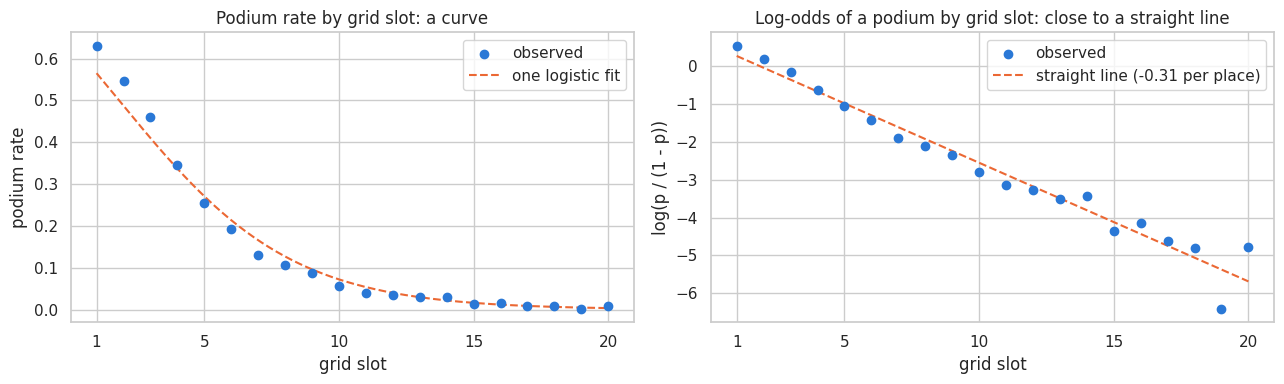

In [40]:
def rule_scores(df, col):
    s = -df[col].fillna(99).values                  # unknown slot -> back of the grid
    return scores(df, s, thr=-3)                    # predicted podium <=> slot <= 3

RULES = {"Rule: grid P1-P3": "grid_clean", "Rule: qualifying P1-P3": "quali_position"}
rule_tbl = pd.concat({name: pd.DataFrame({"train": rule_scores(win, col), "validation": rule_scores(val, col)}).T
                      for name, col in RULES.items()})
display(rule_tbl.round(3))

# ---- log-odds of a podium by grid slot (all training seasons, slots with >= 30 rows) ----
trg = MT[(MT.split == "train") & MT.grid_clean.notna()]
g = trg.groupby("grid_clean")["podium"].agg(["sum", "size"])
g = g[(g["size"] >= 30) & (g.index <= 20)]
p_hat = (g["sum"] + 0.5) / (g["size"] + 1)              # +0.5 / +1 avoids log(0) for slots with no podium
g["log_odds"] = np.log(p_hat / (1 - p_hat))
slope, icpt = np.polyfit(g.index, g["log_odds"], 1, w=np.sqrt(g["size"]))
print(f"Weighted straight-line fit: log-odds = {icpt:.2f} {slope:+.3f} x grid slot")

xs = np.linspace(1, 20, 200)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(g.index, g["sum"] / g["size"], color="#2a78d6", zorder=3, label="observed")
ax[0].plot(xs, 1 / (1 + np.exp(-(icpt + slope * xs))), "--", color="#eb6834", label="one logistic fit")
ax[0].set_title("Podium rate by grid slot: a curve"); ax[0].set_ylabel("podium rate")
ax[1].scatter(g.index, g["log_odds"], color="#2a78d6", zorder=3, label="observed")
ax[1].plot(xs, icpt + slope * xs, "--", color="#eb6834", label=f"straight line ({slope:+.2f} per place)")
ax[1].set_title("Log-odds of a podium by grid slot: close to a straight line"); ax[1].set_ylabel("log(p / (1 - p))")
for a in ax: a.set_xlabel("grid slot"); a.set_xticks([1, 5, 10, 15, 20]); a.legend()
plt.tight_layout(); plt.show()

## 20. Model 1 — logistic regression (baseline)

**How it works.** Logistic regression computes a weighted sum of the (scaled) features plus an intercept, and passes it through the logistic function 1 / (1 + e^−z) to get a probability between 0 and 1. Each weight says how much one standard deviation of that feature shifts the log-odds of a podium. Training finds the weights that maximise the likelihood of the observed podiums. `C` controls regularisation: a smaller `C` shrinks the weights towards zero, which guards against overfitting.

**Why it is the baseline.** It is the simplest standard model for a yes/no outcome, it is fast and fully transparent, and §19.2 shows its key assumption roughly holds for the dominant feature. The two other models must beat it to justify their extra complexity.

**Tuning:** `C` ∈ {0.01, 0.1, 1, 10}, chosen by mean season-CV PR-AUC.

In [41]:
lr_grid = [{"C": c} for c in [0.01, 0.1, 1, 10]]
lr_res, lr_best, lr_oof = tune(lambda **k: LogisticRegression(max_iter=3000, **k), lr_grid)
display(lr_res.round(4))
lr_pipe = finalise("Logistic regression", LogisticRegression(max_iter=3000, **lr_best), lr_oof, lr_best)

,C,cv_PR_AUC,cv_sd,train_PR_AUC,sec
0,0.01,0.7163,0.0505,0.6748,0.5
1,0.10,0.7285,0.0483,0.6887,0.4
2,1.00,0.7318,0.0503,0.6901,0.4
3,10.00,0.7314,0.0502,0.6902,0.4


Logistic regression: params = {'C': 1} | threshold (from season CV) = 0.390


,ROC_AUC,PR_AUC,F1,precision,recall,top3_hit
train,0.932,0.690,0.669,0.640,0.700,0.648
validation,0.934,0.743,0.692,0.692,0.692,0.701


**Result — logistic regression.**
- `C = 1` gives the best season-CV PR-AUC (**0.732**). `C` barely matters between 0.1 and 10; only the strongest penalty (0.01) loses ground (0.716), because it shrinks real effects such as grid position.
- The CV-chosen threshold is **0.39**: a driver is predicted to podium when the model gives at least a 39% chance.
- **No overfitting:** the training PR-AUC (0.690) is *lower* than validation (0.743). A plausible reason: in 2020–21 two teams (Mercedes and Red Bull) took most of the podiums, which is easier to predict than the average 2003–19 season.
- Against the grid rule on validation it gains **+0.10 PR-AUC** (0.743 vs 0.639) and catches one more podium in its top three per race (70.1% vs 69.2%).

## 21. Model 2 — random forest

**How it works.** A random forest grows many decision trees. Each tree is trained on a bootstrap sample of the rows (drawn with replacement), and at every split it may only choose among a random subset of the features (`max_features`). Each tree splits the data into regions such as "grid ≤ 3 and team podiums in the last 5 races ≥ 1"; the forest's probability is the average over all trees. Averaging many different, noisy trees reduces variance.

**Why we include it.** Unlike logistic regression, a forest can capture curves, thresholds (for example the 107% qualifying rule) and interactions (for example grid slot × team form) without being told about them. If it beats the baseline, those shapes matter; if it does not, the relationships are close to additive in log-odds.

**Attempt A — default settings.** Trees grown until every leaf is pure. We expect overfitting: near-perfect scores on the training rows, worse on new seasons.

**Attempt B — tuned.** We limit how detailed each tree may become: `min_samples_leaf` (a leaf must hold at least this many driver-races), `max_depth` and `max_features`. 18 settings, each scored by season CV.

Attempt A (default settings):


,cv_PR_AUC,cv_sd,train_PR_AUC,sec
0,0.7464,0.0393,1.0,11.5



Attempt B (18 settings), best first:


,min_samples_leaf,max_depth,max_features,cv_PR_AUC,cv_sd,train_PR_AUC,sec
0,5,NaN,sqrt,0.7543,0.0394,0.9214,10.5
1,5,6.0,0.5,0.7511,0.0390,0.8079,13.2
2,5,10.0,sqrt,0.7509,0.0434,0.8867,10.2
3,5,10.0,0.5,0.7492,0.0443,0.9191,16.6
4,50,6.0,0.5,0.7484,0.0407,0.7413,12.3
5,20,6.0,0.5,0.7479,0.0314,0.7740,12.9
6,20,6.0,sqrt,0.7474,0.0356,0.7563,8.5
7,50,10.0,0.5,0.7473,0.0362,0.7447,13.4
8,50,NaN,0.5,0.7468,0.0358,0.7443,13.2
9,20,NaN,0.5,0.7468,0.0318,0.8059,14.9


Random forest: params = {'min_samples_leaf': 5, 'max_depth': None, 'max_features': 'sqrt'} | threshold (from season CV) = 0.286


,ROC_AUC,PR_AUC,F1,precision,recall,top3_hit
train,0.985,0.921,0.794,0.694,0.928,0.840
validation,0.927,0.725,0.694,0.664,0.726,0.701


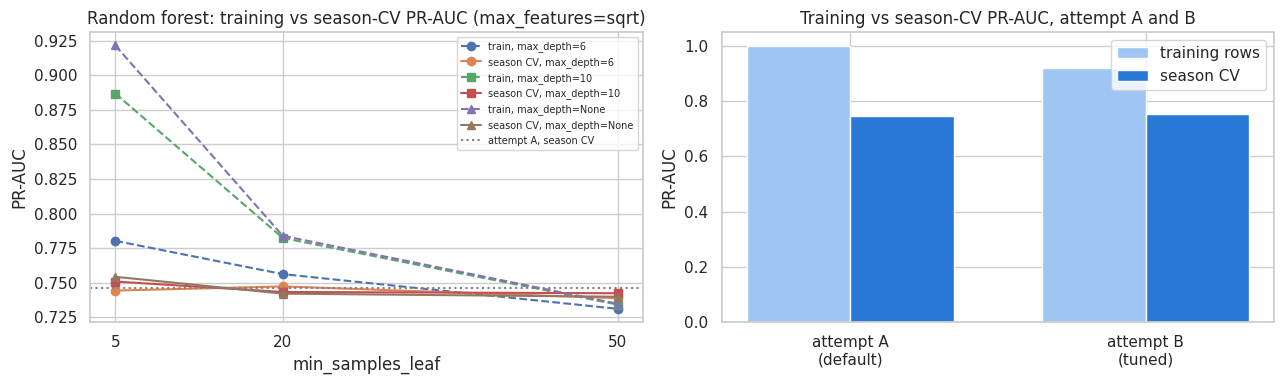

In [42]:
RF_FIXED = dict(n_estimators=300, n_jobs=-1, random_state=M2_SEED)

# ---- attempt A: default trees ----
rfA_res, _, rfA_oof = tune(lambda **k: RandomForestClassifier(**RF_FIXED, **k), [{}])
print("Attempt A (default settings):")
display(rfA_res.round(4))

# ---- attempt B: tuned ----
rf_grid = [dict(min_samples_leaf=l, max_depth=d, max_features=f)
           for l, d, f in itertools.product([5, 20, 50], [6, 10, None], ["sqrt", 0.5])]
rf_res, rf_best, rf_oof = tune(lambda **k: RandomForestClassifier(**RF_FIXED, **k), rf_grid)
print("\nAttempt B (18 settings), best first:")
display(rf_res.sort_values("cv_PR_AUC", ascending=False).round(4).reset_index(drop=True))
rf_pipe = finalise("Random forest", RandomForestClassifier(**RF_FIXED, **rf_best), rf_oof, rf_best)

# ---- training vs season-CV score as trees are allowed more detail ----
best_f = rf_best["max_features"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
depth_lab = rf_res.max_depth.map(lambda v: "None" if pd.isna(v) else str(int(v)))
for d, mk in zip([6, 10, None], ["o", "s", "^"]):
    r = rf_res[(depth_lab == str(d)) & (rf_res.max_features.astype(str) == str(best_f))]
    ax[0].plot(r.min_samples_leaf, r.train_PR_AUC, marker=mk, ls="--", label=f"train, max_depth={d}")
    ax[0].plot(r.min_samples_leaf, r.cv_PR_AUC, marker=mk, label=f"season CV, max_depth={d}")
ax[0].axhline(rfA_res.cv_PR_AUC[0], color="grey", ls=":", label="attempt A, season CV")
ax[0].set_xlabel("min_samples_leaf"); ax[0].set_ylabel("PR-AUC"); ax[0].set_xticks([5, 20, 50])
ax[0].set_title(f"Random forest: training vs season-CV PR-AUC (max_features={best_f})"); ax[0].legend(fontsize=7)
ax[1].bar(["attempt A\n(default)", "attempt B\n(tuned)"], [rfA_res.train_PR_AUC[0], rf_res.loc[rf_res.cv_PR_AUC.idxmax(), "train_PR_AUC"]],
          width=0.35, label="training rows", color="#9ec5f4")
ax[1].bar(np.arange(2) + 0.35, [rfA_res.cv_PR_AUC[0], rf_res.cv_PR_AUC.max()], width=0.35, label="season CV", color="#2a78d6")
ax[1].set_xticks(np.arange(2) + 0.175); ax[1].set_xticklabels(["attempt A\n(default)", "attempt B\n(tuned)"])
ax[1].set_ylabel("PR-AUC"); ax[1].set_title("Training vs season-CV PR-AUC, attempt A and B"); ax[1].legend()
plt.tight_layout(); plt.show()

**Result — random forest.**
- **Attempt A** memorises the training rows (training PR-AUC 1.00) yet still scores **0.746** in season CV, already above logistic regression (0.732). Averaging 300 different trees cancels much of each tree's noise, so the huge training/CV gap does not translate into poor predictions here.
- **Attempt B:** the best setting is `min_samples_leaf=5`, no depth limit, `max_features="sqrt"` with season-CV PR-AUC **0.754**, only +0.008 over the defaults and well inside the fold-to-fold spread (sd ≈ 0.04). Forcing simpler trees (`min_samples_leaf=50` or `max_depth=6`) closes the gap to the training score but lowers the CV score slightly (left plot), so for this data the gap is not what limits the forest.
- **On validation** the tuned forest scores **0.725**, below logistic regression (0.743), even though it led in season CV. Its CV-chosen threshold is lower (0.29) because averaged trees give less extreme probabilities on new seasons.
- In plain words: the forest learns the training seasons by heart, but what it carries over to new seasons is about as good as the baseline, not clearly better.

## 22. Model 3 — shallow neural network

**How it works.** A feed-forward network (scikit-learn's `MLPClassifier`) passes the 16 scaled features (plus the missing-value flags) through one or two hidden layers of neurons. Each neuron computes a weighted sum of its inputs and applies the ReLU function max(0, z); the output neuron applies the logistic function to give a probability. The weights are learned by back-propagation with the Adam optimiser, minimising log-loss. `alpha` is an L2 penalty on the weights (like a small `C` in logistic regression, it keeps the network from memorising noise). With one hidden layer of 16 neurons the network already has about 450 weights, against roughly 960 podiums in the training window, so regularisation matters. "Shallow" here means one or two hidden layers, as the brief asks; the scaled inputs from `make_preprocessor` are what a network needs to train well.

**Why we include it.** Required by the brief. It can also model smooth non-linear patterns, unlike the step-like splits of a forest.

**Attempt A — library defaults with built-in early stopping** (two layers of 32 and 16 neurons). Early stopping in scikit-learn holds out a *random* 10% of the training rows and stops when their score stops improving. With few podiums this held-out sample is noisy and training can stop too soon.

**Attempt B — tuned.** No built-in early stopping; a fixed 300 passes over the data instead, and we search layer sizes {(8), (16), (32), (32, 16)} × `alpha` {0.001, 0.01, 0.1, 1} by season CV. A network's result also depends on its random starting weights, so we finally retrain the chosen setting with five different seeds to see how stable it is.

Attempt A (built-in early stopping):


,cv_PR_AUC,cv_sd,train_PR_AUC,sec
0,0.7186,0.0505,0.5624,3.2



Attempt B (16 settings), best first:


,hidden_layer_sizes,alpha,cv_PR_AUC,cv_sd,train_PR_AUC,sec
0,"(8,)",0.010,0.7469,0.0500,0.7231,16.1
1,"(8,)",0.100,0.7430,0.0499,0.7206,13.4
2,"(32,)",0.010,0.7381,0.0430,0.7734,26.6
3,"(32,)",0.001,0.7374,0.0378,0.7734,26.5
4,"(8,)",0.001,0.7358,0.0498,0.7202,16.1
5,"(32,)",0.100,0.7343,0.0378,0.7528,18.9
6,"(32, 16)",1.000,0.7319,0.0559,0.7061,14.8
7,"(16,)",1.000,0.7314,0.0524,0.7006,11.8
8,"(32,)",1.000,0.7299,0.0544,0.7012,11.7
9,"(16,)",0.100,0.7295,0.0516,0.7303,17.1


Shallow neural network: params = {'hidden_layer_sizes': (8,), 'alpha': 0.01} | threshold (from season CV) = 0.355


,ROC_AUC,PR_AUC,F1,precision,recall,top3_hit
train,0.941,0.723,0.681,0.634,0.736,0.681
validation,0.932,0.717,0.695,0.680,0.709,0.692


Validation PR-AUC over 5 seeds: mean 0.725, min 0.704, max 0.746


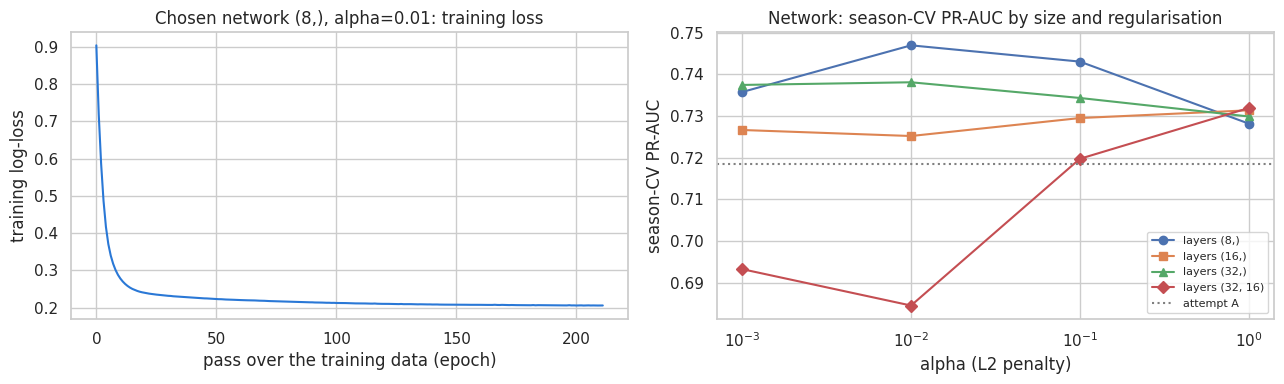

In [43]:
# ---- attempt A: defaults + built-in early stopping ----
mlpA_res, _, _ = tune(lambda **k: MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=500,
                                                random_state=M2_SEED, **k), [{}])
print("Attempt A (built-in early stopping):")
display(mlpA_res.round(4))

# ---- attempt B: tuned ----
MLP_FIXED = dict(max_iter=300, random_state=M2_SEED)
mlp_grid = [dict(hidden_layer_sizes=h, alpha=a) for h, a in itertools.product([(8,), (16,), (32,), (32, 16)], [0.001, 0.01, 0.1, 1.0])]
mlp_res, mlp_best, mlp_oof = tune(lambda **k: MLPClassifier(**MLP_FIXED, **k), mlp_grid)
print("\nAttempt B (16 settings), best first:")
display(mlp_res.sort_values("cv_PR_AUC", ascending=False).round(4).reset_index(drop=True))
mlp_pipe = finalise("Shallow neural network", MLPClassifier(**MLP_FIXED, **mlp_best), mlp_oof, mlp_best)

# ---- stability across random starting weights ----
seed_rows = []
for s in range(5):
    p = make_pipe(MLPClassifier(max_iter=300, random_state=s, **mlp_best)).fit(X_tr, y_tr)
    seed_rows.append({"seed": s, "val_PR_AUC": average_precision_score(y_va, p.predict_proba(X_va)[:, 1])})
seed_df = pd.DataFrame(seed_rows)
print(f"Validation PR-AUC over 5 seeds: mean {seed_df.val_PR_AUC.mean():.3f}, "
      f"min {seed_df.val_PR_AUC.min():.3f}, max {seed_df.val_PR_AUC.max():.3f}")

# ---- training curve and the effect of alpha ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(mlp_pipe.named_steps["clf"].loss_curve_, color="#2a78d6")
ax[0].set_xlabel("pass over the training data (epoch)"); ax[0].set_ylabel("training log-loss")
ax[0].set_title(f"Chosen network {mlp_best['hidden_layer_sizes']}, alpha={mlp_best['alpha']}: training loss")
for h, mk in zip([(8,), (16,), (32,), (32, 16)], ["o", "s", "^", "D"]):
    r = mlp_res[mlp_res.hidden_layer_sizes.astype(str) == str(h)]
    ax[1].plot(r.alpha, r.cv_PR_AUC, marker=mk, label=f"layers {h}")
ax[1].axhline(mlpA_res.cv_PR_AUC[0], color="grey", ls=":", label="attempt A")
ax[1].set_xscale("log"); ax[1].set_xlabel("alpha (L2 penalty)"); ax[1].set_ylabel("season-CV PR-AUC")
ax[1].set_title("Network: season-CV PR-AUC by size and regularisation"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Result — shallow neural network.**
- **Attempt A underfits:** its training PR-AUC (0.56) is even lower than its CV score (0.72). Built-in early stopping, judged on a random 10% of training rows, ended training before the network had learned the main patterns.
- **Attempt B:** the best network is the smallest, **one hidden layer of 8 neurons with `alpha = 0.01`**, at season-CV PR-AUC **0.747** (+0.028 over attempt A). The training loss levels off after about 50 passes (left plot), so 300 passes are enough.
- **Bigger is worse here:** two layers (32, 16) with a weak penalty overfit (training 0.84, CV 0.68–0.69). Only a strong penalty (`alpha = 1`) brings them back to 0.73. With about 960 podiums to learn from, a small network generalises best.
- **On validation** it scores **0.717**. Over five random seeds the same setting ranges from **0.704 to 0.746**, so the starting weights alone move the score as much as the whole gap between the three models.

## 23. Final comparison on validation and the unseen test set

All three final models were fitted once on `TRAIN_FROM`–2019 with the settings and thresholds chosen in §20–22. Nothing below changes them: the validation and test rows are only scored. This is the first and only time the test set (2022–24) is used.

**Decision rule, fixed before looking at test:** the recommended model is the one with the best **validation PR-AUC**; if models are within noise of each other, the simpler one is preferred. The test scores then show how well that choice holds up on unseen seasons.

ROC_AUC  PR_AUC     F1  precision  recall  top3_hit
split      model                                                                      
train      Rule: grid P1-P3          0.909   0.626  0.646      0.647   0.646     0.647
           Rule: qualifying P1-P3    0.910   0.619  0.637      0.637   0.637     0.638
           Logistic regression       0.932   0.690  0.669      0.640   0.700     0.648
           Random forest             0.985   0.921  0.794      0.694   0.928     0.840
           Shallow neural network    0.941   0.723  0.681      0.634   0.736     0.681
validation Rule: grid P1-P3          0.909   0.639  0.692      0.692   0.692     0.692
           Rule: qualifying P1-P3    0.919   0.654  0.692      0.692   0.692     0.692
           Logistic regression       0.934   0.743  0.692      0.692   0.692     0.701
           Random forest             0.927   0.725  0.694      0.664   0.726     0.701
           Shallow neural network    0.932   0.717  0.695      0.680   0.709     0.692
test       Rule: grid P1-P3          0.914   0.647  0.649      0.650   0.647     0.652
           Rule: qualifying P1-P3    0.915   0.628  0.629      0.631   0.627     0.632
           Logistic regression       0.935   0.709  0.675      0.664   0.686     0.647
           Random forest             0.937   0.690  0.698      0.623   0.794     0.662
           Shallow neural network    0.935   0.703  0.676      0.625   0.735     0.637

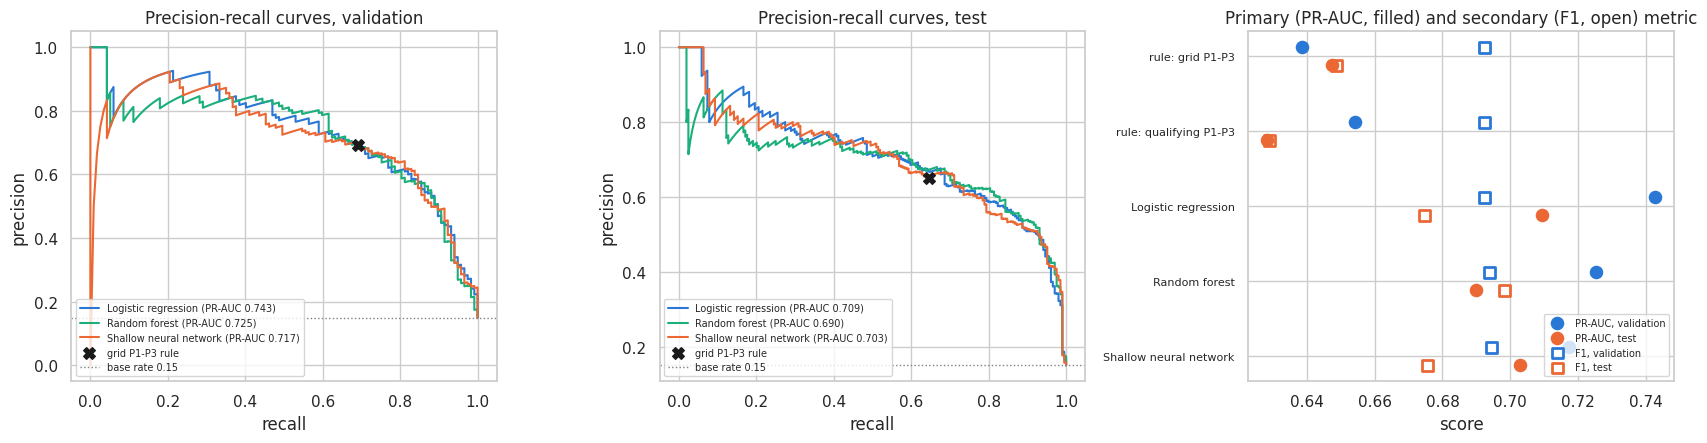

In [44]:
rows = []
for name, col in RULES.items():
    for split, df in [("train", win), ("validation", val), ("test", test)]:
        rows.append({"model": name, "split": split, **rule_scores(df, col)})
for name, m in MODELS.items():
    for split, df in [("train", win), ("validation", val), ("test", test)]:
        rows.append({"model": name, "split": split, **scores(df, m["pipe"].predict_proba(df[FEATURES])[:, 1], m["thr"])})
comparison = pd.DataFrame(rows)
order = list(RULES) + list(MODELS)
comparison["model"] = pd.Categorical(comparison["model"], order, ordered=True)
comparison["split"] = pd.Categorical(comparison["split"], ["train", "validation", "test"], ordered=True)
comparison = comparison.sort_values(["split", "model"]).reset_index(drop=True)
display(comparison.set_index(["split", "model"]).round(3))
comparison.to_csv(f"{OUT}/model_comparison.csv", index=False)

# ---- plots: PR curves on validation and test, and the two decision metrics side by side ----
cols = {"Logistic regression": "#2a78d6", "Random forest": "#1baf7a", "Shallow neural network": "#eb6834"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, (split, df) in zip(ax[:2], [("validation", val), ("test", test)]):
    for name, m in MODELS.items():
        p = m["pipe"].predict_proba(df[FEATURES])[:, 1]
        pr, rc, _ = precision_recall_curve(df.podium, p)
        a.plot(rc, pr, color=cols[name], label=f"{name} (PR-AUC {average_precision_score(df.podium, p):.3f})")
    r = comparison[(comparison.split == split) & (comparison.model == "Rule: grid P1-P3")].iloc[0]
    a.scatter(r.recall, r.precision, color="k", marker="X", s=70, zorder=4, label="grid P1-P3 rule")
    a.axhline(df.podium.mean(), color="grey", ls=":", lw=1, label=f"base rate {df.podium.mean():.2f}")
    a.set_xlabel("recall"); a.set_ylabel("precision"); a.set_title(f"Precision-recall curves, {split}")
    a.legend(fontsize=7, loc="lower left")
m2 = comparison[comparison.split.isin(["validation", "test"])]
y = np.arange(len(order))[::-1]
for split, met, mk, off in [("validation", "PR_AUC", "o", 0.12), ("test", "PR_AUC", "o", -0.12), ("validation", "F1", "s", 0.12), ("test", "F1", "s", -0.12)]:
    v = m2[m2.split == split].set_index("model").loc[order, met]
    c = "#2a78d6" if split == "validation" else "#eb6834"
    ax[2].scatter(v, y + off, marker=mk, s=60, color=c if met == "PR_AUC" else "none", edgecolor=c, linewidth=2,
                  label=f"{met.replace('_', '-')}, {split}", zorder=3)
ax[2].set_yticks(y); ax[2].set_yticklabels([o.replace("Rule: ", "rule: ") for o in order], fontsize=8)
ax[2].set_xlabel("score"); ax[2].set_title("Primary (PR-AUC, filled) and secondary (F1, open) metric")
ax[2].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

### 23.1 What the comparison shows

**Primary metric (PR-AUC).**
- **Every model beats the grid rule:** on test **0.69–0.71** against **0.65** (validation 0.72–0.74 against 0.64). The models rank podium candidates better than "the front three start where they finish", for example by rating a P2 in a dominant car above a P2 in a weak one.
- **Logistic regression is best on validation (0.743) and on test (0.709).** Season CV had ranked the forest (0.754) and the network (0.747) above it (0.732), but that order did not survive on new seasons.
- **The differences are small.** Between the three models they are ≤ 0.02 on both validation and test, smaller than the fold-to-fold spread in season CV (sd 0.03–0.05) and smaller than the network's own seed-to-seed range (0.704–0.746). None of the more complex models reliably beats the baseline. This matches §19.2: the main relationship is close to linear in log-odds, so there is little extra shape for a forest or a network to find.

**Secondary metric (F1, at the threshold chosen by season CV).**
- On validation all three models score 0.69, the same as the grid rule. On test the forest is highest (**0.698** against 0.675–0.676) because its lower threshold catches more podiums (recall 0.79) at the cost of more false alarms (precision 0.62).

**Top-3 hit rate.** When each model simply names three drivers per race, it does no better than the grid: on test 64–66% of podium places against 65% for the rule. The models' advantage is in the probabilities and the ranking of all drivers, not in picking the three names.

**Training vs validation vs test.**
- Logistic regression and the network score about the same on training and validation (no overfitting). The forest scores 0.92 on training against 0.73 on validation, so its training score says little about new data.
- All three models lose about 0.02–0.04 PR-AUC from validation to test, while the grid rule does not. The 2022 regulation reset changed the pecking order, and 20% of test rows come from teams that never appear in training (§14). The form and standings features that give the models their edge carry less information right after a rule change.

**Recommended model: logistic regression.** It has the best validation PR-AUC (the decision rule fixed before test), it is confirmed on test, it is the simplest and most transparent of the three, and it does not depend on a random seed. The random forest is the alternative if catching more podiums (recall) matters more than precision.

## 24. Model limitations

**Logistic regression**
- Assumes every feature shifts the log-odds by a fixed amount and that effects add up. It cannot learn the mild extra curvature at the front of the grid (§19.2) or interactions (for example grid × team form) unless they are built as features.
- Strongly correlated features (for example the driver-form features) make individual weights unstable, although the predictions themselves are not affected.

**Random forest**
- Memorises the training rows (training PR-AUC 0.92), so its training score is no guide to its real accuracy.
- Predicts in steps and cannot extrapolate beyond the value ranges seen in training, which matters when a new team or a new rule set produces unusual form values.
- Its probabilities are less extreme on new data than on training data, so the decision threshold must come from out-of-sample predictions (here 0.29, not 0.5). It is also slower and harder to read than the baseline.

**Shallow neural network**
- Results depend on the random starting weights: the same setting ranges from 0.704 to 0.746 validation PR-AUC across five seeds.
- Needs scaled inputs and careful regularisation; with about 960 training podiums, anything larger than a small network overfits.
- The least transparent of the three.

**All models**
- **Small evaluation sets:** validation has 39 races and test 68, so differences of about 0.01–0.02 between models are within noise.
- **Each driver is scored independently:** the models do not know that a race has exactly three podium places, so the probabilities in one race need not add up to three.
- **Era sensitivity:** trained on 2003–2019, the models lose accuracy after the 2022 regulation change and on teams they have never seen.
- **Missing information:** nothing about weather, reliability updates during a weekend or strategy, all of which decide some podiums.
- **Trained on the training window only:** for the test evaluation the models were not refitted on 2003–2021. Refitting on the longer window before predicting the next season would likely help a little.

## Part 4 — Experiments and Explainable AI (Member 4)

This section uses the existing leakage-safe feature groups, training window, validation split, and selected logistic-regression model. The validation set is used for interpretation and comparisons; the held-out 2022–2024 test set is not used to choose features or explain model choices.


### 25. Feature-group ablation

Ablation measures how much each feature group contributes by removing one group at a time, retraining the same model on the same training rows, and scoring it on validation. A lower PR-AUC after removal suggests that the group contributes useful predictive information. Results are associations, not proof of causation.

,experiment,n_features,PR_AUC,ROC_AUC,PR_AUC_change_vs_all
0,All selected features,16,0.7426,0.9344,0.0000
6,Remove context,14,0.7425,0.9338,-0.0001
4,Remove constructor_form,13,0.7401,0.9338,-0.0026
3,Remove driver_form,11,0.7352,0.9322,-0.0074
5,Remove standings,13,0.7341,0.9335,-0.0085
2,Remove qualifying,14,0.7276,0.9274,-0.0151
1,Remove grid,15,0.7117,0.9205,-0.0309


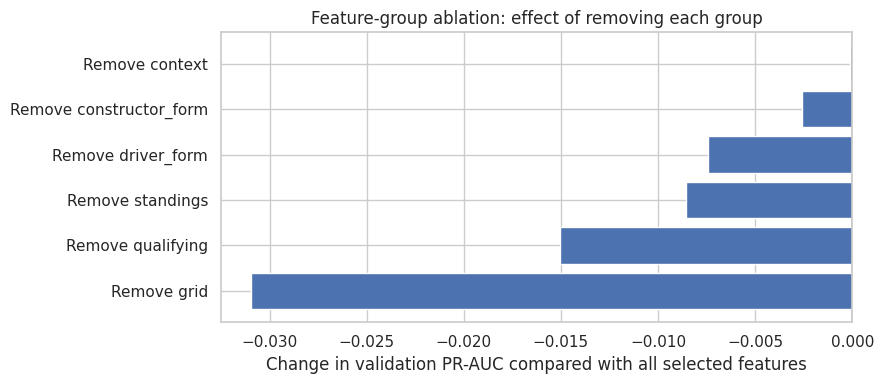

Interpretation guide: negative values mean removing that group reduced PR-AUC; values near zero mean little measured change; positive values mean the reduced model scored better on this validation set. Small differences may be noise.


In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, roc_auc_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the same selected training window and validation set as Member 3.
X_ab_train = X_tr[FEATURES].copy()
y_ab_train = np.asarray(y_tr)
X_ab_val = val[FEATURES].copy()
y_ab_val = val['podium'].to_numpy()

def fit_and_score_feature_set(feature_list, label):
    pipe = Pipeline([('prep', make_preprocessor(feature_list)),
                    ('clf', LogisticRegression(max_iter=3000, C=MODELS['Logistic regression']['params'].get('C', 1.0)))])
    pipe.fit(X_ab_train[feature_list], y_ab_train)
    prob = pipe.predict_proba(X_ab_val[feature_list])[:, 1]
    return {'experiment': label,
            'n_features': len(feature_list),
            'PR_AUC': average_precision_score(y_ab_val, prob),
            'ROC_AUC': roc_auc_score(y_ab_val, prob)}

ablation_rows = [fit_and_score_feature_set(FEATURES, 'All selected features')]
for group_name, group_features in SEL_GROUPS.items():
    group_features = [f for f in group_features if f in FEATURES]
    remaining = [f for f in FEATURES if f not in group_features]
    if group_features and remaining:
        ablation_rows.append(fit_and_score_feature_set(remaining, f'Remove {group_name}'))

ablation_results = pd.DataFrame(ablation_rows)
baseline_pr = ablation_results.loc[ablation_results.experiment == 'All selected features', 'PR_AUC'].iloc[0]
ablation_results['PR_AUC_change_vs_all'] = ablation_results['PR_AUC'] - baseline_pr
display(ablation_results.sort_values('PR_AUC', ascending=False).round(4))

plot_data = ablation_results[ablation_results.experiment != 'All selected features'].sort_values('PR_AUC_change_vs_all')
fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(plot_data))))
ax.barh(plot_data['experiment'], plot_data['PR_AUC_change_vs_all'])
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Change in validation PR-AUC compared with all selected features')
ax.set_title('Feature-group ablation: effect of removing each group')
plt.tight_layout(); plt.show()

print('Interpretation guide: negative values mean removing that group reduced PR-AUC; values near zero mean little measured change; positive values mean the reduced model scored better on this validation set. Small differences may be noise.')

**Result:** Removing **grid** costs the most (PR-AUC 0.743 → 0.712, −0.031), then **qualifying** (−0.015). Standings (−0.009), driver form (−0.007) and constructor form (−0.003) cost little, and **context** costs nothing (−0.0001).

- Starting position carries most of the signal. Only the grid and qualifying drops are clearly above the validation noise (about ±0.01 with 117 podiums).
- The grid drop is smaller than it looks because the qualifying features still carry related starting-position information. Without grid the model still scores 0.712, above the grid rule (0.639).
- Groups overlap, so these drops understate each group on its own and do not add up.
  

### 26. Permutation importance

Permutation importance starts with the fitted logistic-regression pipeline and shuffles one validation feature at a time. If PR-AUC drops, the feature contains information the fitted model uses. Because several F1 features are correlated, importance can be shared across related features; a low individual score does not necessarily mean the whole feature group is unhelpful.

,feature,importance_mean,importance_std
0,grid_pct,0.2819,0.0252
3,drv_starts_before,0.0462,0.0212
1,quali_gap_pct,0.0366,0.0169
9,con_best_finish_pct_last5,0.0265,0.0174
2,grid_penalty,0.0178,0.0110
7,drv_career_podium_rate,0.0135,0.0098
14,driver_age,0.0125,0.0147
13,con_rank_before,0.0102,0.0103
12,drv_wins_before,0.0075,0.0062
10,con_dnf_rate_last10,0.0035,0.0029


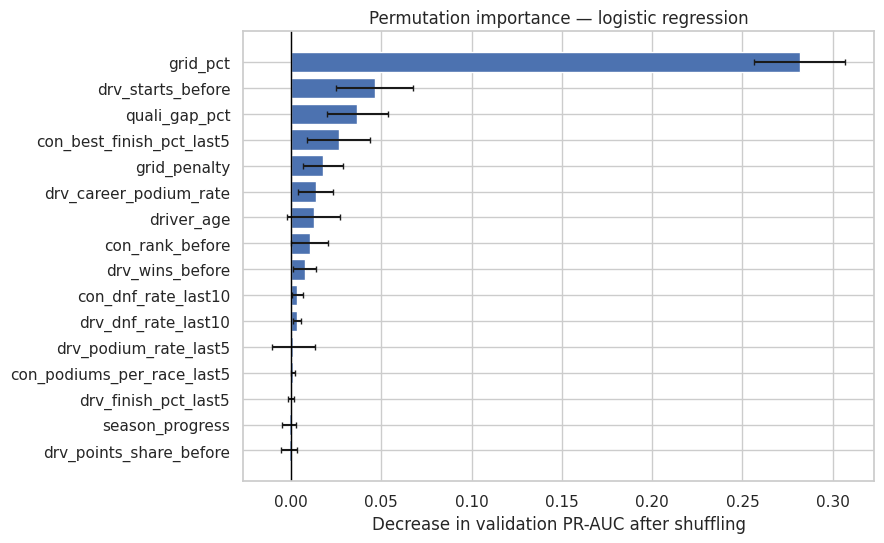

In [46]:
from sklearn.inspection import permutation_importance

final_lr = MODELS['Logistic regression']['pipe']
perm = permutation_importance(
    final_lr, val[FEATURES], val['podium'],
    scoring='average_precision', n_repeats=10, random_state=42, n_jobs=-1
)
perm_results = pd.DataFrame({
    'feature': FEATURES,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=True)
display(perm_results.sort_values('importance_mean', ascending=False).round(4))

fig, ax = plt.subplots(figsize=(9, max(5, 0.35 * len(perm_results))))
ax.barh(perm_results['feature'], perm_results['importance_mean'], xerr=perm_results['importance_std'], capsize=2)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Decrease in validation PR-AUC after shuffling')
ax.set_title('Permutation importance — logistic regression')
plt.tight_layout(); plt.show()


**Result:** Shuffling **grid_pct** costs 0.282 PR-AUC, six times the next feature (drv_starts_before, 0.046). Then come quali_gap_pct (0.037), con_best_finish_pct_last5 (0.027) and grid_penalty (0.018).

- The ranking below the top four is not reliable: for driver_age, drv_podium_rate_last5 and con_rank_before the sd is as large as the mean.
- Features near zero (season_progress, drv_points_share_before, drv_finish_pct_last5) are not necessarily useless. The form and standings features are correlated, so the others cover for a shuffled one.
- Permutation costs far more than ablation for grid (0.282 vs 0.031) because the model is not retrained, so it cannot lean on the qualifying features instead.

### 27. Global and local SHAP explanations

For logistic regression, SHAP values can be calculated in the transformed feature space. The explanation is on the model's raw score (log-odds), not directly on probability. The preprocessing step is fitted on the training rows only, consistent with the modeling pipeline.

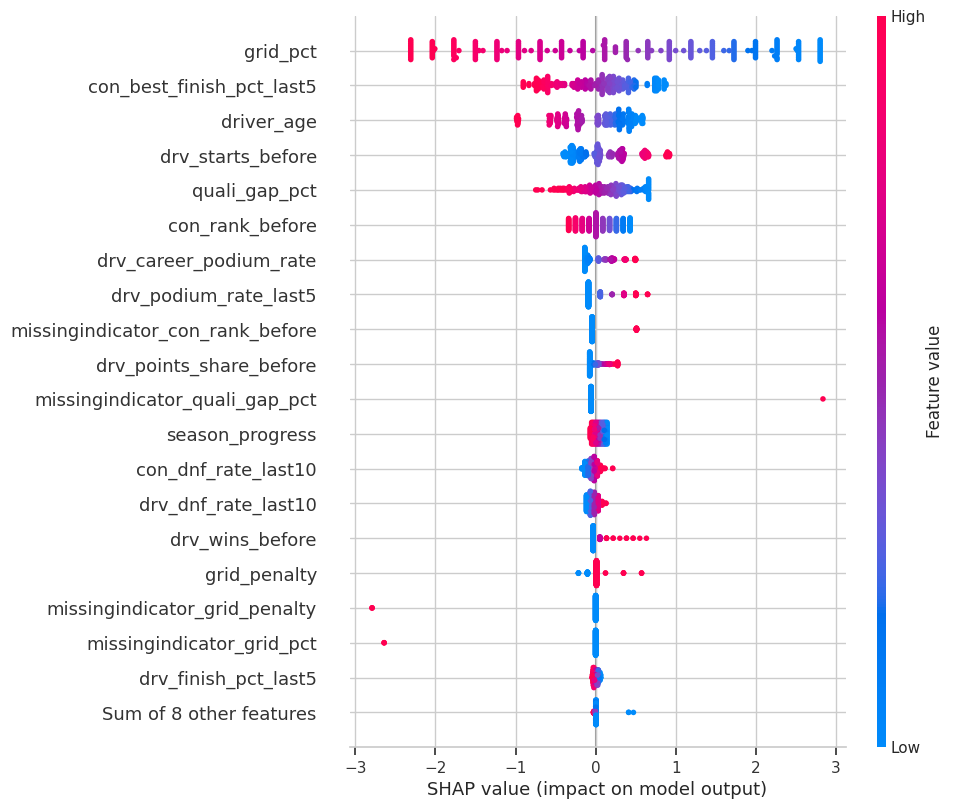

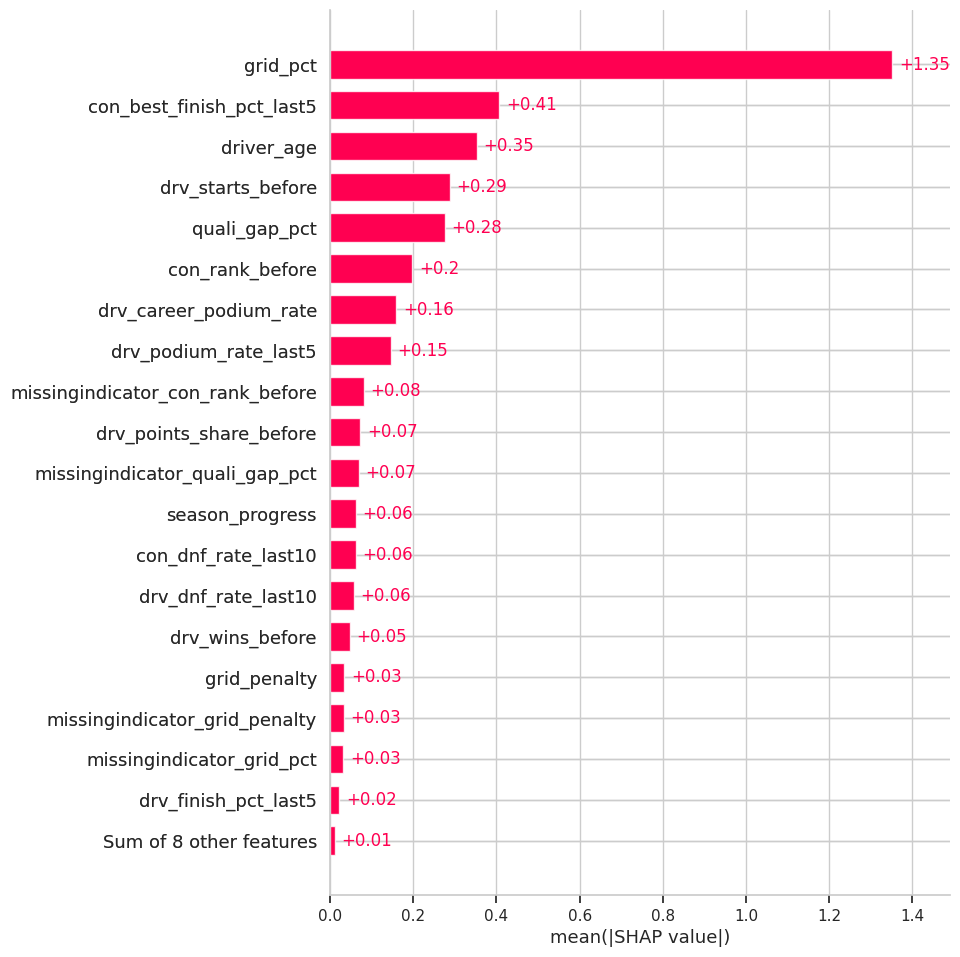

In [47]:
# SHAP may need installation in a fresh environment. In Kaggle, try importing it first.
try:
    import shap
except ImportError as exc:
    raise ImportError('SHAP is required for this section. In a notebook cell, run: %pip install shap, then rerun this cell.') from exc

# Explain the existing fitted logistic regression, not a newly tuned model.
prep_lr = final_lr.named_steps['prep']
clf_lr = final_lr.named_steps['clf']
X_train_transformed = prep_lr.transform(X_tr[FEATURES])
X_val_transformed = prep_lr.transform(val[FEATURES])
shap_feature_names = prep_lr.get_feature_names_out()

# A small background sample keeps computation manageable.
rng_shap = np.random.default_rng(42)
bg_n = min(100, X_train_transformed.shape[0])
bg_idx = rng_shap.choice(X_train_transformed.shape[0], size=bg_n, replace=False)
background_shap = X_train_transformed[bg_idx]

shap_explainer = shap.LinearExplainer(clf_lr, background_shap)
n_explain = min(250, X_val_transformed.shape[0])
shap_values_global = shap_explainer(X_val_transformed[:n_explain])
shap_values_global.feature_names = list(shap_feature_names)

# Global explanation: features with the largest average absolute SHAP values have the largest average influence on the model score.
shap.plots.beeswarm(shap_values_global, max_display=20, show=True)
shap.plots.bar(shap_values_global, max_display=20, show=True)


**Result:** **grid_pct** is first by a wide margin (mean |SHAP| 1.35, over three times the next). Front-of-grid values push the score up, back-of-grid values push it down. Next: con_best_finish_pct_last5 (0.41), driver_age (0.35), drv_starts_before (0.29) and quali_gap_pct (0.28).

- Better recent constructor results, more career starts and a smaller qualifying gap all push towards a podium.
- driver_age pushes down at high values, and the vertical stripes in the beeswarm suggest it partly acts as a driver identifier in this sample (not tested).
- SHAP and permutation importance agree on grid_pct first but differ in the middle order. They measure different things (how far a feature moves the output vs how much accuracy depends on it).
- **Limitation:** SHAP is computed on the first 250 validation rows only (about the first twelve races of 2020), and values are in log-odds.

### 27.1 Explain one individual prediction (local SHAP)

The next cell selects a validation example with the highest predicted podium probability among true podium finishes, if one exists. It reports the row's race and driver IDs, actual label, and predicted probability, then visualizes which features pushed the model score higher or lower relative to the baseline.

raceId: 1073 | driverId: 830 | year: 2021
Actual podium label: 1
Predicted podium probability: 0.922


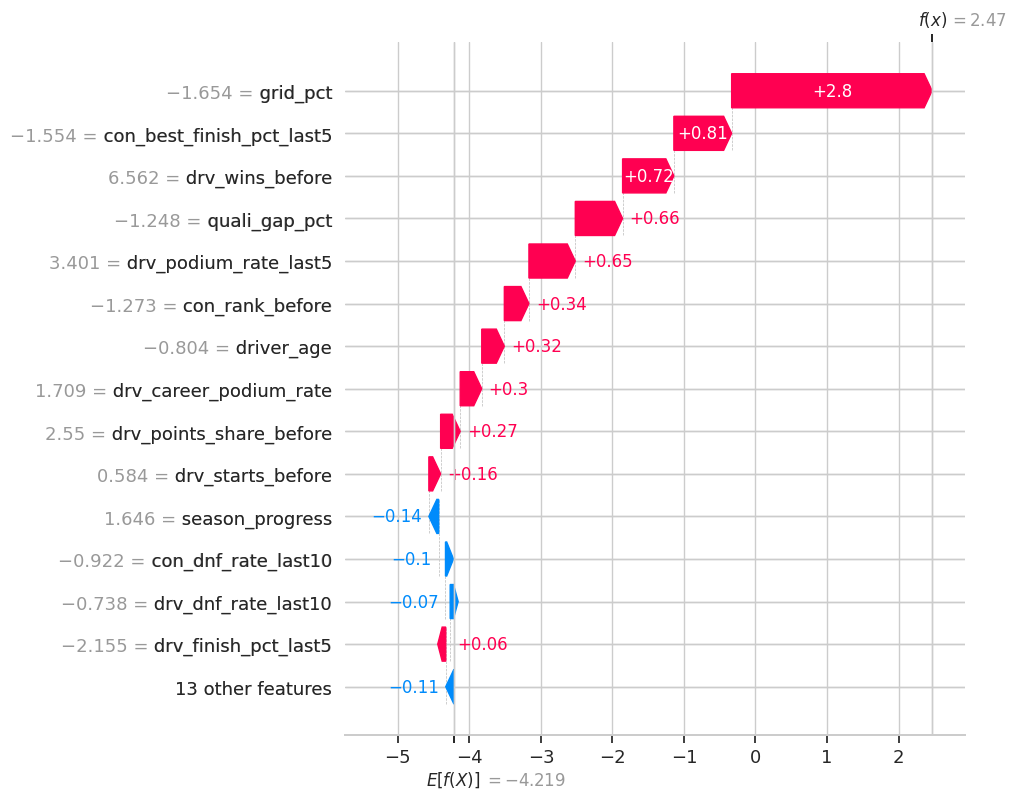

In [48]:
val_probs_for_explain = final_lr.predict_proba(val[FEATURES])[:, 1]
candidate_idx = np.flatnonzero(val['podium'].to_numpy() == 1)
if len(candidate_idx):
    local_idx = int(candidate_idx[np.argmax(val_probs_for_explain[candidate_idx])])
else:
    local_idx = int(np.argmax(val_probs_for_explain))

local_shap_values = shap_explainer(X_val_transformed[local_idx:local_idx + 1])
local_shap_values.feature_names = list(shap_feature_names)
row = val.iloc[local_idx]
print('raceId:', row['raceId'], '| driverId:', row['driverId'], '| year:', row['year'])
print('Actual podium label:', int(row['podium']))
print('Predicted podium probability:', round(float(val_probs_for_explain[local_idx]), 4))
shap.plots.waterfall(local_shap_values[0], max_display=15, show=True)


**Result:** For raceId 1073, driverId 830 (2021), the model gives a podium probability of **0.922** (actual: podium). The prediction sits about 6.7 log-odds above the baseline of −4.22.

- **grid_pct** alone adds +2.8 (about 42% of the shift), because the driver starts near the front.
- The rest comes from strong form: recent constructor finishing (+0.81), career wins (+0.72), qualifying gap (+0.66) and recent podium rate (+0.65). No feature pushes meaningfully against it (largest is −0.14).
- This is the easiest case, the highest-probability true podium, so it shows how the model combines agreeing signals, not how it handles borderline cases.
- These are explanations of the model's behaviour, not causes of podium finishes.

## 28. Inference function

`predict_podium(record)` returns the podium prediction for **one driver in one race** from pre-race information only. It uses the recommended model (logistic regression, §23), its preprocessing pipeline fitted on the training window, and the decision threshold frozen in §20.

- **Input:** a dict with any of the 16 features in `FEATURES` (Table 3 of the report). Every feature is known before the start: grid, qualifying, and form and standings built from earlier races only.
- **Missing values:** any feature that is absent, `None` or `NaN` is filled by the pipeline exactly as in training: median imputation plus a missing-indicator column. A record with no qualifying data, a debut or a season opener therefore still gets a prediction.
- **Checks:** unknown keys raise an error, so post-race fields such as `positionOrder` or `points` cannot slip in. Values outside the range seen in training are flagged.
- **Output:** podium probability, the yes/no decision at the frozen threshold, and which features were imputed or out of range.

Below, the function is demonstrated on a **complete** record and on a **partially missing** copy of the same record. The demo rows come from the last race of 2024. They are only scored; nothing is tuned on them.

In [49]:
INFER = MODELS["Logistic regression"]                      # recommended model: fitted pipeline + frozen threshold
_TRAIN_RANGE = win[FEATURES].agg(["min", "max"])            # value ranges seen in training (2003-2019)
_ALLOWED_IDS = {"raceId", "driverId"}

def predict_podium(record, model=INFER):
    """Predict whether one driver finishes on the podium, using pre-race features only.

    record : dict (or pandas Series) holding any subset of FEATURES (+ optional raceId / driverId).
             Missing, None or NaN features are imputed by the training-fitted pipeline.
    returns: dict with podium_probability, predicted_podium (0/1), threshold, imputed_features,
             outside_training_range.
    """
    rec = dict(record)
    unknown = sorted(set(rec) - set(FEATURES) - _ALLOWED_IDS)
    if unknown:
        raise ValueError(f"Not model features (possibly post-race fields): {unknown}")
    row = pd.DataFrame([{f: rec.get(f, np.nan) for f in FEATURES}], dtype=float)
    imputed = [f for f in FEATURES if pd.isna(row.at[0, f])]
    outside = [f for f in FEATURES if f not in imputed
               and not (_TRAIN_RANGE.at["min", f] <= row.at[0, f] <= _TRAIN_RANGE.at["max", f])]
    p = float(model["pipe"].predict_proba(row)[:, 1][0])
    return {"podium_probability": round(p, 4), "predicted_podium": int(p >= model["thr"]),
            "threshold": round(model["thr"], 3), "imputed_features": imputed, "outside_training_range": outside}

def record_from_table(race_id, driver_id):
    """Pre-race feature record for one driver-race from the leakage-safe modelling table."""
    r = modeling_table[(modeling_table.raceId == race_id) & (modeling_table.driverId == driver_id)]
    assert len(r) == 1, "no such driver-race"
    return {"raceId": race_id, "driverId": driver_id, **r.iloc[0][FEATURES].to_dict()}

# ---- demo race: the last race of 2024 ----
last_race = races_t[races_t.year == 2024].sort_values("round").iloc[-1]
demo = modeling_table[modeling_table.raceId == last_race.raceId].sort_values("grid_pct")
drv_names = clean["drivers"].assign(driverId=clean["drivers"].driverId.astype(int)).set_index("driverId")
pick = demo.iloc[0]                                          # the pole sitter
rid, did = int(pick.raceId), int(pick.driverId)
who = f"{drv_names.at[did, 'forename']} {drv_names.at[did, 'surname']}"
print(f"Demo: {last_race['name']} {last_race.year}, {who} (raceId {rid}, driverId {did}), actual podium = {int(pick.podium)}")

# 1) complete record
full_rec = record_from_table(rid, did)
res_full = predict_podium(full_rec)

# 2) partially missing record: same driver-race, but no qualifying data and no constructor standings
partial_rec = {k: v for k, v in full_rec.items() if k not in ["quali_gap_pct", "grid_penalty", "con_rank_before"]}
partial_rec["drv_podium_rate_last5"] = None
res_partial = predict_podium(partial_rec)

display(pd.DataFrame({"complete record": res_full, "partially missing record": res_partial}).T)

# consistency check: the function reproduces the pipeline's own prediction for the complete record
direct = INFER["pipe"].predict_proba(modeling_table.loc[[pick.name], FEATURES])[:, 1][0]
assert abs(direct - res_full["podium_probability"]) < 1e-4
# guard check: post-race fields are rejected
try:
    predict_podium({**full_rec, "positionOrder": 1}); raise AssertionError("post-race field was accepted")
except ValueError as e:
    print("Rejected as expected:", e)

# the whole grid of the demo race, ranked by predicted probability
grid_view = demo[["driverId", "podium"] + FEATURES].copy()
grid_view["driver"] = grid_view.driverId.map(lambda d: drv_names.at[int(d), "surname"])
grid_view["p_podium"] = [predict_podium(r)["podium_probability"] for r in demo[FEATURES].to_dict("records")]
display(grid_view.sort_values("p_podium", ascending=False)[["driver", "p_podium", "podium"]].head(6).reset_index(drop=True))

Demo: Abu Dhabi Grand Prix 2024, Lando Norris (raceId 1144, driverId 846), actual podium = 1


,podium_probability,predicted_podium,threshold,imputed_features,outside_training_range
complete record,0.6477,1,0.39,[],[]
partially missing record,0.5781,1,0.39,"[quali_gap_pct, grid_penalty, drv_podium_rate_last5, con_rank_before]",[]


Rejected as expected: Not model features (possibly post-race fields): ['positionOrder']


,driver,p_podium,podium
0,Verstappen,0.7289,0
1,Norris,0.6477,1
2,Sainz,0.5697,1
3,Piastri,0.4839,0
4,Russell,0.1837,0
5,Gasly,0.0770,0


**Result:** the complete record and the partially missing record both return a prediction. For the partial record the four removed features are listed as imputed, and the probability moves because the pipeline replaces them with training medians and sets their missing indicators. The function matches the pipeline's own prediction to four decimals, rejects post-race fields, and ranks the whole grid of the demo race.